In [59]:
from pathlib import Path
import sys
import importlib.metadata as metadata
import numpy as np

ROOT = Path.cwd()
SRC = ROOT / "src"
DATA_FILE = ROOT / "data" / "pbmc3k_hvg_panel.h5ad"
MODEL_FILE = SRC / "vae_torch.py"

print(" ENVIRONMENT CHECK")
print("-" * 40)
print("Project:", ROOT)
print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("PyTorch package:", metadata.version("torch"))
print("Dataset exists:", DATA_FILE.exists())
print("VAE file exists:", MODEL_FILE.exists())

if MODEL_FILE.exists():
    print("VAE file size:", MODEL_FILE.stat().st_size, "bytes")
    print("Contains VAE class:", "class VAE" in MODEL_FILE.read_text())

 ENVIRONMENT CHECK
----------------------------------------
Project: /Users/gorgeous_jane/pbmc3k-vae-explainability
Python: /Users/gorgeous_jane/.venv/bin/python
NumPy: 1.26.4
PyTorch package: 2.2.2
Dataset exists: True
VAE file exists: True
VAE file size: 1805 bytes
Contains VAE class: True


In [60]:

from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Reference cell-type labels
labels = adata.obs["louvain_cluster"].astype(str).to_numpy()

# 1. Silhouette score for VAE latent representation
vae_score = silhouette_score(
    latent_mu,
    labels,
    metric="euclidean"
)

# 2. Create a 16-dimensional PCA representation
pca = PCA(
    n_components=16,
    random_state=42
)

pca_embedding = pca.fit_transform(X_dense)

# 3. Silhouette score for PCA
pca_score = silhouette_score(
    pca_embedding,
    labels,
    metric="euclidean"
)

# 4. Display comparison
print("VAE vs PCA: SILHOUETTE COMPARISON")
print("-" * 45)
print(f"VAE (16 dimensions): {vae_score:.4f}")
print(f"PCA (16 components): {pca_score:.4f}")
print("-" * 45)

if vae_score > pca_score:
    print("VAE has stronger label separation.")
elif pca_score > vae_score:
    print("PCA has stronger label separation.")
else:
    print("Both representations have equal scores.")


VAE vs PCA: SILHOUETTE COMPARISON
---------------------------------------------
VAE (16 dimensions): 0.2462
PCA (16 components): 0.3122
---------------------------------------------
PCA has stronger label separation.


In [62]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Standardise VAE latent dimensions
vae_scaled = StandardScaler().fit_transform(
    latent_mu
)

# Standardise PCA components
pca_scaled = StandardScaler().fit_transform(
    pca_embedding
)

# Calculate standardised silhouette scores
vae_scaled_score = silhouette_score(
    vae_scaled,
    labels,
    metric="euclidean"
)

pca_scaled_score = silhouette_score(
    pca_scaled,
    labels,
    metric="euclidean"
)

print("STANDARDISED VAE vs PCA")
print("-" * 45)
print(f"VAE: {vae_scaled_score:.4f}")
print(f"PCA: {pca_scaled_score:.4f}")
print("-" * 45)

print(
    "Higher score:",
    "VAE" if vae_scaled_score > pca_scaled_score
    else "PCA" if pca_scaled_score > vae_scaled_score
    else "Equal"
)

STANDARDISED VAE vs PCA
---------------------------------------------
VAE: 0.0964
PCA: 0.1415
---------------------------------------------
Higher score: PCA


In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np

# Identify VAE dimensions with variance above 0.01
latent_variances = np.var(
    latent_mu ,
    axis=0
)

active_indices = np.where(latent_variances > 0.01)[0]

# Select active VAE dimensions
vae_active = latent_mu [:, active_indices]

# Select the same number of PCA components
pca_matched = pca_embedding[:, :len(active_indices)]

# Calculate scores without standardisation
vae_active_raw = silhouette_score(
    vae_active, labels
)

pca_matched_raw = silhouette_score(
    pca_matched, labels
)

# Calculate scores after standardisation
vae_active_scaled = silhouette_score(
    StandardScaler().fit_transform(vae_active),
    labels
)

pca_matched_scaled = silhouette_score(
    StandardScaler().fit_transform(pca_matched),
    labels
)

print("ACTIVE-DIMENSION COMPARISON")
print("-" * 50)
print("Active VAE dimensions:", len(active_indices))
print("Excluded dimensions:", 16 - len(active_indices))
print("-" * 50)
print(f"VAE active (raw):        {vae_active_raw:.4f}")
print(f"PCA matched (raw):       {pca_matched_raw:.4f}")
print(f"VAE active (scaled):     {vae_active_scaled:.4f}")
print(f"PCA matched (scaled):    {pca_matched_scaled:.4f}")
print("-" * 50)

ACTIVE-DIMENSION COMPARISON
--------------------------------------------------
Active VAE dimensions: 13
Excluded dimensions: 3
--------------------------------------------------
VAE active (raw):        0.2471
PCA matched (raw):       0.3430
VAE active (scaled):     0.1178
PCA matched (scaled):    0.1844
--------------------------------------------------


In [67]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    balanced_accuracy_score,
    accuracy_score
)
from sklearn.neighbors import KNeighborsClassifier

# 1. Prepare train/test masks
is_train = (
    adata.obs["split"].astype(str).to_numpy() == "train"
)
is_test = ~is_train

labels = adata.obs["louvain_cluster"].astype(str).to_numpy()

# 2. Obtain latent representations
Z = latent_mu

Z_train = Z[is_train]
Z_test = Z[is_test]

# 3. Select top 7 dimensions using TRAINING cells only
train_variances = np.var(Z_train, axis=0)

top7 = np.argsort(train_variances)[::-1][:7]

Z7_train = Z_train[:, top7]
Z7_test = Z_test[:, top7]

# 4. Fit PCA on training expression data only
pca = PCA(n_components=16, random_state=42)

PCA_train = pca.fit_transform(X_dense[is_train])
PCA_test = pca.transform(X_dense[is_test])

# 5. Define evaluation function
def evaluate(name, train_embedding, test_embedding):

    # Fit scaling on training cells only
    scaler = StandardScaler()

    train_scaled = scaler.fit_transform(train_embedding)
    test_scaled = scaler.transform(test_embedding)

    # Silhouette on held-out cells
    sil = silhouette_score(
        test_scaled,
        labels[is_test]
    )

    # Train kNN on training cells
    knn = KNeighborsClassifier(n_neighbors=15)

    knn.fit(train_scaled, labels[is_train])

    predictions = knn.predict(test_scaled)

    acc = accuracy_score(
        labels[is_test],
        predictions
    )

    bal_acc = balanced_accuracy_score(
        labels[is_test],
        predictions
    )

    print(
        f"{name:<18} "
        f"Silhouette: {sil:.4f} | "
        f"Accuracy: {acc:.4f} | "
        f"Balanced accuracy: {bal_acc:.4f}"
    )


# 6. Run four comparisons
print("HELD-OUT TEST EVALUATION")
print("=" * 85)
print("Training cells:", is_train.sum())
print("Test cells:", is_test.sum())
print("Selected VAE dimensions:", top7 + 1)
print("-" * 85)

evaluate("VAE 16 dims", Z_train, Z_test)
evaluate("VAE top 7 dims", Z7_train, Z7_test)
evaluate("PCA 7 comps", PCA_train[:, :7], PCA_test[:, :7])
evaluate("PCA 16 comps", PCA_train, PCA_test)

print("=" * 85)

HELD-OUT TEST EVALUATION
Training cells: 2110
Test cells: 528
Selected VAE dimensions: [15  7  2  5 14  9 16]
-------------------------------------------------------------------------------------
VAE 16 dims        Silhouette: 0.1339 | Accuracy: 0.9110 | Balanced accuracy: 0.7782
VAE top 7 dims     Silhouette: 0.2626 | Accuracy: 0.9280 | Balanced accuracy: 0.8332
PCA 7 comps        Silhouette: 0.3464 | Accuracy: 0.9242 | Balanced accuracy: 0.8514
PCA 16 comps       Silhouette: 0.1708 | Accuracy: 0.9242 | Balanced accuracy: 0.8460


In [69]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# 1. Define established immune-cell marker genes
marker_genes = [
    "CD79A", "MS4A1",       # B cells
    "NKG7", "GNLY",         # NK cells
    "LYZ", "CST3",           # Monocytes
    "CD3D", "CD3E", "CD3G", # T cells
    "IL7R", "CD8A", "CCR7"  # T-cell subpopulations
]

# 2. Check which genes are available
available_markers = [
    gene for gene in marker_genes
    if gene in adata.var_names
]

missing_markers = [
    gene for gene in marker_genes
    if gene not in adata.var_names
]

print("Available markers:", available_markers)
print("Missing markers:", missing_markers)

# 3. Extract expression of marker genes
marker_expression = adata[:, available_markers].X

if hasattr(marker_expression, "toarray"):
    marker_expression = marker_expression.toarray()

marker_expression = np.asarray(
    marker_expression,
    dtype=np.float32
)

# 4. Get VAE latent means
latent_array = latent_mu

# 5. Calculate Spearman correlations
results = []

for dim in range(latent_array.shape[1]):

    for j, gene in enumerate(available_markers):

        rho, p_value = spearmanr(
            latent_array[:, dim],
            marker_expression[:, j]
        )

        results.append({
            "latent_dimension": f"latent_{dim + 1}",
            "marker_gene": gene,
            "spearman_rho": rho,
            "p_value": p_value
        })

# 6. Create results DataFrame
correlation_df = pd.DataFrame(results)

# 7. Rank associations by absolute correlation
correlation_df["abs_rho"] = (
    correlation_df["spearman_rho"].abs()
)

top_correlations = (
    correlation_df
    .sort_values("abs_rho", ascending=False)
    .head(20)
    .drop(columns="abs_rho")
)

print("\nTOP 20 LATENT–MARKER ASSOCIATIONS")
print("=" * 65)

display(top_correlations.round(4))

Available markers: ['CD79A', 'MS4A1', 'NKG7', 'GNLY', 'LYZ', 'CST3', 'CD3D', 'CD3E', 'CD3G', 'IL7R', 'CD8A', 'CCR7']
Missing markers: []

TOP 20 LATENT–MARKER ASSOCIATIONS


,latent_dimension,marker_gene,spearman_rho,p_value
173,latent_15,CST3,0.6707,0.0
172,latent_15,LYZ,0.6230,0.0
98,latent_9,NKG7,-0.6029,0.0
14,latent_2,NKG7,0.5516,0.0
72,latent_7,CD79A,0.5031,0.0
79,latent_7,CD3E,-0.4855,0.0
81,latent_7,IL7R,-0.4714,0.0
174,latent_15,CD3D,-0.4592,0.0
73,latent_7,MS4A1,0.4539,0.0
78,latent_7,CD3D,-0.4427,0.0


In [70]:
# Multiple testing correction using Benjamini-Hochberg

import numpy as np

# Copy original results
correlation_df_fdr = correlation_df.copy()

# Replace numerical underflow zeros with the smallest positive float
p_values = correlation_df_fdr["p_value"].to_numpy()

p_values = np.maximum(
    p_values,
    np.nextafter(0, 1)
)

# Benjamini-Hochberg correction
n = len(p_values)

order = np.argsort(p_values)
ranked_p = p_values[order]

adjusted = ranked_p * n / np.arange(1, n + 1)

# Enforce monotonicity
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]

# Restore original order
q_values = np.empty(n)
q_values[order] = np.minimum(adjusted, 1.0)

correlation_df_fdr["adjusted_p_value"] = q_values

# Identify statistically significant associations
correlation_df_fdr["significant_FDR_0.05"] = (
    correlation_df_fdr["adjusted_p_value"] < 0.05
)

# Display strongest associations
correlation_df_fdr["abs_rho"] = (
    correlation_df_fdr["spearman_rho"].abs()
)

top_fdr = (
    correlation_df_fdr
    .sort_values("abs_rho", ascending=False)
    .head(20)
    .drop(columns="abs_rho")
)

print("MULTIPLE TESTING CORRECTION")
print("=" * 75)
print("Total tests:", n)
print(
    "Significant associations (FDR < 0.05):",
    correlation_df_fdr["significant_FDR_0.05"].sum()
)
print("=" * 75)

display(top_fdr.round(6))

MULTIPLE TESTING CORRECTION
Total tests: 192
Significant associations (FDR < 0.05): 135


,latent_dimension,marker_gene,spearman_rho,p_value,adjusted_p_value,significant_FDR_0.05
173,latent_15,CST3,0.670722,0.0,0.0,True
172,latent_15,LYZ,0.622991,0.0,0.0,True
98,latent_9,NKG7,-0.602902,0.0,0.0,True
14,latent_2,NKG7,0.551643,0.0,0.0,True
72,latent_7,CD79A,0.503071,0.0,0.0,True
79,latent_7,CD3E,-0.485506,0.0,0.0,True
81,latent_7,IL7R,-0.471412,0.0,0.0,True
174,latent_15,CD3D,-0.459191,0.0,0.0,True
73,latent_7,MS4A1,0.453937,0.0,0.0,True
78,latent_7,CD3D,-0.442661,0.0,0.0,True


In [25]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# 1. Prepare data
cell_types = adata.obs["louvain_cluster"].astype(str).to_numpy()

latent_array = latent_mu.numpy()

# 2. Identify populations with at least 50 cells
cell_counts = pd.Series(cell_types).value_counts()

eligible_types = cell_counts[cell_counts >= 50].index.tolist()

print("CELL POPULATIONS INCLUDED")
print("-" * 45)

for cell_type in eligible_types:
    print(f"{cell_type}: {(cell_types == cell_type).sum()} cells")

# 3. Calculate within-population correlations
within_results = []

for cell_type in eligible_types:

    mask = cell_types == cell_type

    for dim in range(latent_array.shape[1]):

        for j, gene in enumerate(available_markers):

            rho, p_value = spearmanr(
                latent_array[mask, dim],
                marker_expression[mask, j]
            )

            within_results.append({
                "cell_type": cell_type,
                "latent_dimension": f"latent_{dim + 1}",
                "marker_gene": gene,
                "spearman_rho": rho,
                "p_value": p_value,
                "n_cells": int(mask.sum())
            })

# 4. Create results table
within_corr_df = pd.DataFrame(within_results)

# 5. Apply global BH correction across all within-type tests
valid = within_corr_df["p_value"].notna()

within_corr_df["adjusted_p_value"] = np.nan

within_corr_df.loc[valid, "adjusted_p_value"] = (
    multipletests(
        within_corr_df.loc[valid, "p_value"],
        method="fdr_bh"
    )[1]
)

within_corr_df["significant_FDR_0.05"] = (
    within_corr_df["adjusted_p_value"] < 0.05
)

# 6. Display strongest within-population associations
within_corr_df["abs_rho"] = (
    within_corr_df["spearman_rho"].abs()
)

top_within = (
    within_corr_df
    .sort_values("abs_rho", ascending=False)
    .head(30)
    .drop(columns="abs_rho")
)

print("\nWITHIN-CELL-TYPE CORRELATION RESULTS")
print("=" * 75)

print("Total tests:", len(within_corr_df))
print(
    "Significant associations:",
    within_corr_df["significant_FDR_0.05"].sum()
)

display(top_within.round(5))

CELL POPULATIONS INCLUDED
---------------------------------------------
CD4 T cells: 1144 cells
CD14+ Monocytes: 480 cells
B cells: 342 cells
CD8 T cells: 316 cells
NK cells: 154 cells
FCGR3A+ Monocytes: 150 cells

WITHIN-CELL-TYPE CORRELATION RESULTS
Total tests: 1152
Significant associations: 202


,cell_type,latent_dimension,marker_gene,spearman_rho,p_value,n_cells,adjusted_p_value,significant_FDR_0.05
590,CD8 T cells,latent_2,NKG7,0.66473,0.00000,316,0.00000,True
674,CD8 T cells,latent_9,NKG7,-0.59343,0.00000,316,0.00000,True
1012,FCGR3A+ Monocytes,latent_5,LYZ,0.53399,0.00000,150,0.00000,True
657,CD8 T cells,latent_7,IL7R,-0.49181,0.00000,316,0.00000,True
855,NK cells,latent_8,GNLY,0.48378,0.00000,154,0.00000,True
831,NK cells,latent_6,GNLY,-0.46029,0.00000,154,0.00000,True
364,CD14+ Monocytes,latent_15,LYZ,0.45881,0.00000,480,0.00000,True
729,CD8 T cells,latent_13,IL7R,-0.45842,0.00000,316,0.00000,True
244,CD14+ Monocytes,latent_5,LYZ,0.45142,0.00000,480,0.00000,True
597,CD8 T cells,latent_2,IL7R,-0.45098,0.00000,316,0.00000,True


In [74]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# 1. Prepare data
cell_types = adata.obs["louvain_cluster"].astype(str).to_numpy()

# latent_mu is already a NumPy array in this notebook
latent_array = np.asarray(latent_mu)

# 2. Identify populations with at least 50 cells
cell_counts = pd.Series(cell_types).value_counts()

eligible_types = cell_counts[cell_counts >= 50].index.tolist()

print("CELL POPULATIONS INCLUDED")
print("-" * 45)

for cell_type in eligible_types:
    print(f"{cell_type}: {(cell_types == cell_type).sum()} cells")

# 3. Calculate within-population correlations
within_results = []

for cell_type in eligible_types:

    mask = cell_types == cell_type

    for dim in range(latent_array.shape[1]):

        for j, gene in enumerate(available_markers):

            rho, p_value = spearmanr(
                latent_array[mask, dim],
                marker_expression[mask, j]
            )

            within_results.append({
                "cell_type": cell_type,
                "latent_dimension": f"latent_{dim + 1}",
                "marker_gene": gene,
                "spearman_rho": rho,
                "p_value": p_value,
                "n_cells": int(mask.sum())
            })

# 4. Create results table
within_corr_df = pd.DataFrame(within_results)

# 5. Apply global BH correction across all within-type tests
valid = within_corr_df["p_value"].notna()

within_corr_df["adjusted_p_value"] = np.nan

within_corr_df.loc[valid, "adjusted_p_value"] = (
    multipletests(
        within_corr_df.loc[valid, "p_value"],
        method="fdr_bh"
    )[1]
)

within_corr_df["significant_FDR_0.05"] = (
    within_corr_df["adjusted_p_value"] < 0.05
)

# 6. Display strongest within-population associations
within_corr_df["abs_rho"] = (
    within_corr_df["spearman_rho"].abs()
)

top_within = (
    within_corr_df
    .sort_values("abs_rho", ascending=False)
    .head(30)
    .drop(columns="abs_rho")
)

print("\nWITHIN-CELL-TYPE CORRELATION RESULTS")
print("=" * 75)

print("Total tests:", len(within_corr_df))
print(
    "Significant associations:",
    within_corr_df["significant_FDR_0.05"].sum()
)

display(top_within.round(5))


CELL POPULATIONS INCLUDED
---------------------------------------------
CD4 T cells: 1144 cells
CD14+ Monocytes: 480 cells
B cells: 342 cells
CD8 T cells: 316 cells
NK cells: 154 cells
FCGR3A+ Monocytes: 150 cells

WITHIN-CELL-TYPE CORRELATION RESULTS
Total tests: 1152
Significant associations: 202


,cell_type,latent_dimension,marker_gene,spearman_rho,p_value,n_cells,adjusted_p_value,significant_FDR_0.05
590,CD8 T cells,latent_2,NKG7,0.66473,0.00000,316,0.00000,True
674,CD8 T cells,latent_9,NKG7,-0.59343,0.00000,316,0.00000,True
1012,FCGR3A+ Monocytes,latent_5,LYZ,0.53399,0.00000,150,0.00000,True
657,CD8 T cells,latent_7,IL7R,-0.49181,0.00000,316,0.00000,True
855,NK cells,latent_8,GNLY,0.48378,0.00000,154,0.00000,True
831,NK cells,latent_6,GNLY,-0.46029,0.00000,154,0.00000,True
364,CD14+ Monocytes,latent_15,LYZ,0.45881,0.00000,480,0.00000,True
729,CD8 T cells,latent_13,IL7R,-0.45842,0.00000,316,0.00000,True
244,CD14+ Monocytes,latent_5,LYZ,0.45142,0.00000,480,0.00000,True
597,CD8 T cells,latent_2,IL7R,-0.45098,0.00000,316,0.00000,True


In [75]:
# Inspect the saved within-cell-type correlation results

print("DATAFRAME SHAPE:", within_corr_df.shape)
print("\nCOLUMN NAMES:")
print(within_corr_df.columns.tolist())

print("\nFIRST FIVE ROWS:")
display(within_corr_df.head())

print("\nCELL TYPES:")
print(within_corr_df["cell_type"].unique())

DATAFRAME SHAPE: (1152, 9)

COLUMN NAMES:
['cell_type', 'latent_dimension', 'marker_gene', 'spearman_rho', 'p_value', 'n_cells', 'adjusted_p_value', 'significant_FDR_0.05', 'abs_rho']

FIRST FIVE ROWS:


,cell_type,latent_dimension,marker_gene,spearman_rho,p_value,n_cells,adjusted_p_value,significant_FDR_0.05,abs_rho
0,CD4 T cells,latent_1,CD79A,-0.060635,0.040316,1144,0.146983,False,0.060635
1,CD4 T cells,latent_1,MS4A1,-0.035516,0.230008,1144,0.468993,False,0.035516
2,CD4 T cells,latent_1,NKG7,0.078330,0.008036,1144,0.046229,True,0.078330
3,CD4 T cells,latent_1,GNLY,0.059549,0.044040,1144,0.155407,False,0.059549
4,CD4 T cells,latent_1,LYZ,-0.026599,0.368733,1144,0.610317,False,0.026599



CELL TYPES:
['CD4 T cells' 'CD14+ Monocytes' 'B cells' 'CD8 T cells' 'NK cells'
 'FCGR3A+ Monocytes']


DATA VALIDATION
------------------------------
DataFrame shape: (1152, 9)
Cell populations: 6
Latent dimensions: 16
Marker genes: 12


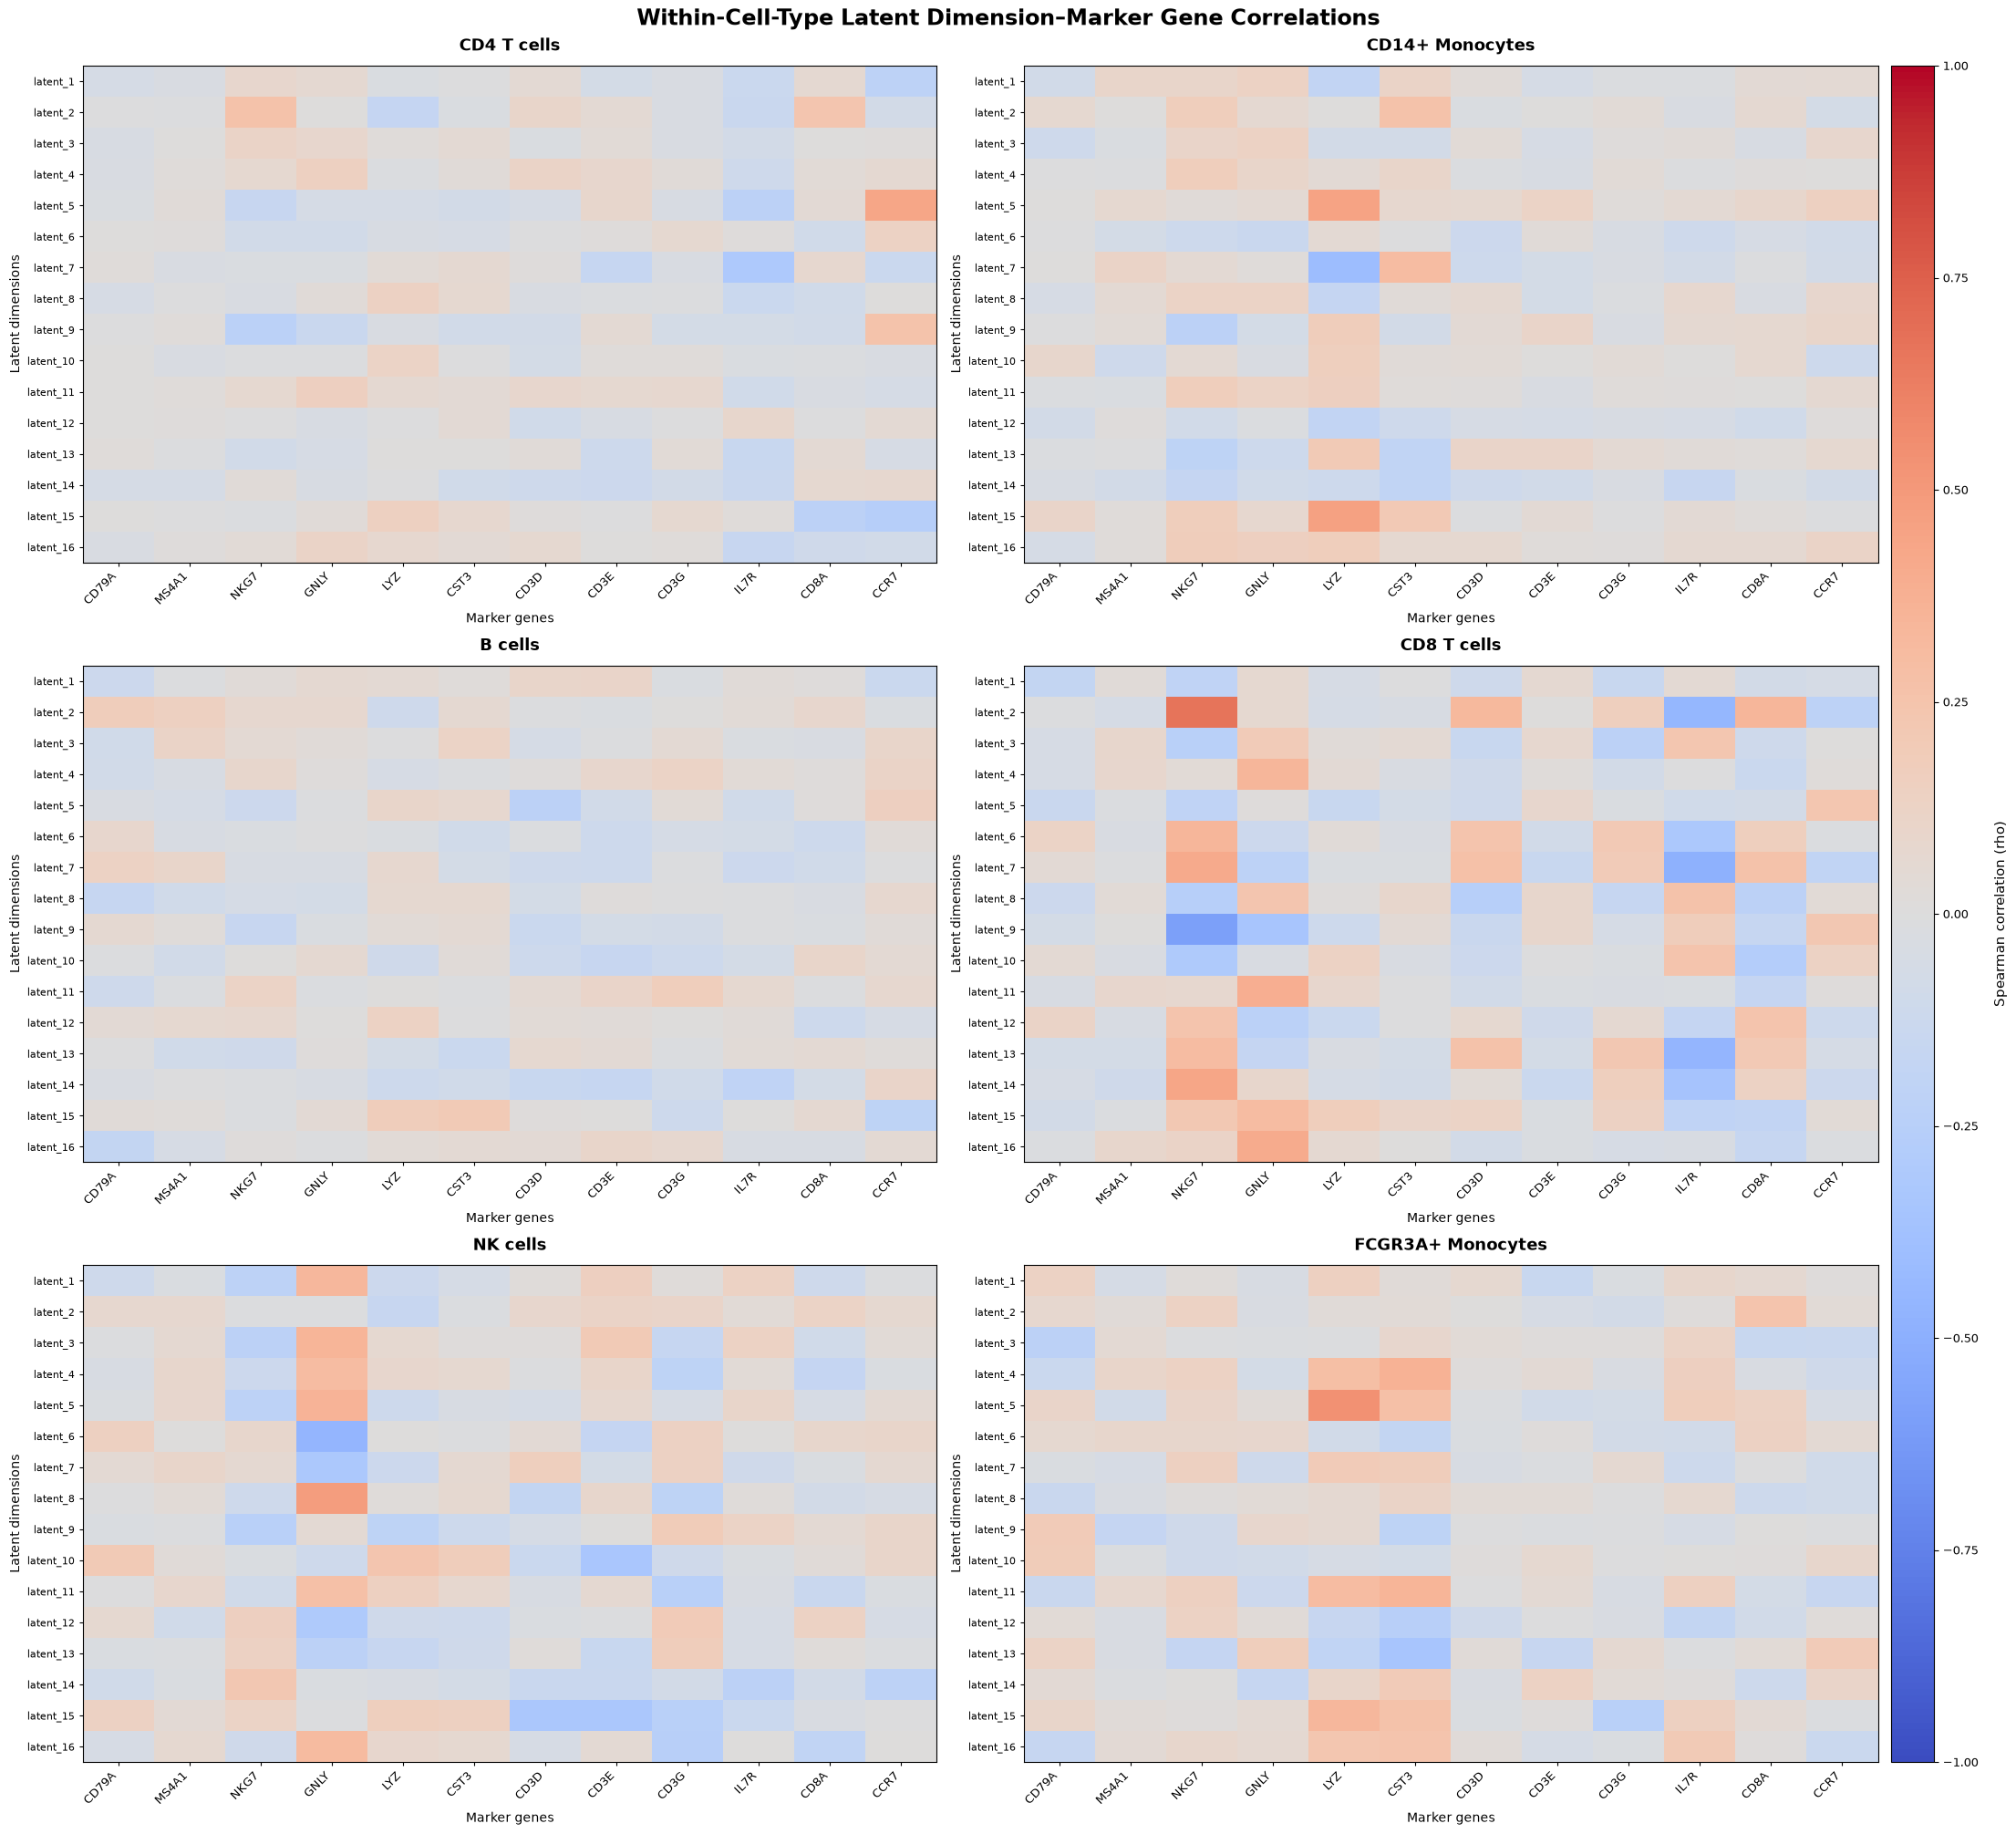


HEATMAP GENERATION COMPLETED
---------------------------------------
Number of heatmaps: 6
Latent dimensions per heatmap: 16
Marker genes per heatmap: 12
Colour bar position: Dedicated right-hand column
Figure saved: /Users/gorgeous_jane/pbmc3k-vae-explainability/figures/day2_within_cell_type_marker_correlations.png
File exists: True


In [76]:
# ============================================================
# WITHIN-CELL-TYPE LATENT DIMENSION–MARKER GENE HEATMAPS
# Six cell populations | 16 latent dimensions | 12 marker genes
# Dedicated colour bar on the right
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Define cell types, markers and latent dimensions
# ------------------------------------------------------------

cell_types = [
    "CD4 T cells",
    "CD14+ Monocytes",
    "B cells",
    "CD8 T cells",
    "NK cells",
    "FCGR3A+ Monocytes"
]

marker_order = [
    "CD79A", "MS4A1",
    "NKG7", "GNLY",
    "LYZ", "CST3",
    "CD3D", "CD3E", "CD3G",
    "IL7R", "CD8A", "CCR7"
]

latent_order = [
    f"latent_{i}" for i in range(1, 17)
]

# ------------------------------------------------------------
# 2. Validate the correlation DataFrame
# ------------------------------------------------------------

required_columns = [
    "cell_type",
    "latent_dimension",
    "marker_gene",
    "spearman_rho"
]

missing_columns = [
    col for col in required_columns
    if col not in within_corr_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("DATA VALIDATION")
print("------------------------------")
print("DataFrame shape:", within_corr_df.shape)
print("Cell populations:", within_corr_df["cell_type"].nunique())
print("Latent dimensions:", within_corr_df["latent_dimension"].nunique())
print("Marker genes:", within_corr_df["marker_gene"].nunique())

# ------------------------------------------------------------
# 3. Create figure with dedicated colour-bar column
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(22, 20),
    constrained_layout=True
)

gs = fig.add_gridspec(
    nrows=3,
    ncols=3,
    width_ratios=[1, 1, 0.05],
    height_ratios=[1, 1, 1]
)

# Six heatmap axes
axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, 0]),
    fig.add_subplot(gs[2, 1])
]

# Independent colour-bar axis
cbar_ax = fig.add_subplot(gs[:, 2])

# ------------------------------------------------------------
# 4. Plot one heatmap for each cell population
# ------------------------------------------------------------

for ax, cell_type in zip(axes, cell_types):

    # Select the current cell population
    subset = within_corr_df[
        within_corr_df["cell_type"] == cell_type
    ]

    # Convert correlation results into a matrix
    heatmap_data = subset.pivot(
        index="latent_dimension",
        columns="marker_gene",
        values="spearman_rho"
    )

    # Ensure consistent ordering
    heatmap_data = heatmap_data.reindex(
        index=latent_order,
        columns=marker_order
    )

    # Check for missing correlations
    if heatmap_data.isna().any().any():
        raise ValueError(
            f"Missing correlation values for {cell_type}"
        )

    # Draw heatmap
    image = ax.imshow(
        heatmap_data.values,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        aspect="auto",
        interpolation="nearest"
    )

    # Titles and axis labels
    ax.set_title(
        cell_type,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Marker genes",
        fontsize=10
    )

    ax.set_ylabel(
        "Latent dimensions",
        fontsize=10
    )

    # X-axis marker labels
    ax.set_xticks(range(len(marker_order)))

    ax.set_xticklabels(
        marker_order,
        rotation=45,
        ha="right",
        fontsize=9
    )

    # Y-axis latent labels
    ax.set_yticks(range(len(latent_order)))

    ax.set_yticklabels(
        latent_order,
        fontsize=8
    )

    ax.tick_params(
        axis="both",
        length=3
    )

# ------------------------------------------------------------
# 5. Add colour bar in its own dedicated column
# ------------------------------------------------------------

cbar = fig.colorbar(
    image,
    cax=cbar_ax,
    orientation="vertical"
)

cbar.set_label(
    "Spearman correlation (rho)",
    fontsize=11,
    labelpad=12
)

cbar.ax.tick_params(labelsize=9)

# ------------------------------------------------------------
# 6. Add overall figure title
# ------------------------------------------------------------

fig.suptitle(
    "Within-Cell-Type Latent Dimension–Marker Gene Correlations",
    fontsize=17,
    fontweight="bold"
)

# ------------------------------------------------------------
# 7. Save figure
# ------------------------------------------------------------

HEATMAP_FILE = (
    ROOT / "figures" /
    "day2_within_cell_type_marker_correlations.png"
)

HEATMAP_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    HEATMAP_FILE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# ------------------------------------------------------------
# 8. Display and confirm
# ------------------------------------------------------------

plt.show()

print("\nHEATMAP GENERATION COMPLETED")
print("---------------------------------------")
print("Number of heatmaps:", len(cell_types))
print("Latent dimensions per heatmap:", len(latent_order))
print("Marker genes per heatmap:", len(marker_order))
print("Colour bar position: Dedicated right-hand column")
print("Figure saved:", HEATMAP_FILE)
print("File exists:", HEATMAP_FILE.exists())

In [77]:
# ============================================================
# INTEGRATED GRADIENTS — PRE-ANALYSIS CHECK
# ============================================================

from pathlib import Path
import torch
import numpy as np

MODEL_FILE = ROOT / "models" / "vae_torch_seed42.pt"
LATENT_FILE = ROOT / "outputs" / "vae_latent_seed42.npz"

print("INTEGRATED GRADIENTS PRE-ANALYSIS CHECK")
print("=" * 50)

# Check saved files
print("\nSAVED FILES")
print("-" * 30)
print("Model exists:", MODEL_FILE.exists())
print("Latent data exists:", LATENT_FILE.exists())

# Check model
print("\nPYTORCH MODEL")
print("-" * 30)
print("Model available:", "model" in globals())

if "model" in globals():
    model.eval()
    print("Model architecture:", model)
    print("Model parameters:", sum(p.numel() for p in model.parameters()))
    print("Model device:", next(model.parameters()).device)

# Check expression data
print("\nEXPRESSION DATA")
print("-" * 30)
print("AnnData available:", "adata" in globals())

if "adata" in globals():
    print("Expression shape:", adata.shape)
    print("Gene names available:", len(adata.var_names))
    print("Expression matrix type:", type(adata.X).__name__)

# Check PyTorch input tensor
print("\nINPUT TENSOR")
print("-" * 30)
print("X_tensor available:", "X_tensor" in globals())

if "X_tensor" in globals():
    print("Tensor shape:", tuple(X_tensor.shape))
    print("Tensor dtype:", X_tensor.dtype)
    print("Tensor device:", X_tensor.device)

# Check latent dimensions
print("\nLATENT DATA")
print("-" * 30)
print("latent_mu available:", "latent_mu" in globals())

if "latent_mu" in globals():
    print("Latent shape:", tuple(latent_mu.shape))

print("\nCHECK COMPLETED")

INTEGRATED GRADIENTS PRE-ANALYSIS CHECK

SAVED FILES
------------------------------
Model exists: True
Latent data exists: True

PYTORCH MODEL
------------------------------
Model available: True
Model architecture: VAE(
  (encoder): Sequential(
    (0): Linear(in_features=2006, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=2006, bias=True)
  )
)
Model parameters: 1065590
Model device: cpu

EXPRESSION DATA
------------------------------
AnnData available: True
Expression shape: (2638, 2006)
Gene names available: 2006
Expression matrix type: csr_matrix

INPUT TEN

In [78]:
# ============================================================
# INTEGRATED GRADIENTS — CONFIGURATION
# ============================================================

import torch
import numpy as np
from pathlib import Path

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Model configuration
model.eval()
DEVICE = torch.device("cpu")
model.to(DEVICE)

# Input data
X_ig = X_tensor.to(
    device=DEVICE,
    dtype=torch.float32
)

# Baseline: zero-expression reference
baseline = torch.zeros(
    X_ig.shape[1],
    dtype=torch.float32,
    device=DEVICE
)

# Integrated Gradients settings
IG_STEPS = 50
IG_BATCH_SIZE = 32

N_CELLS = X_ig.shape[0]
N_GENES = X_ig.shape[1]
LATENT_DIM = 16

# Output directory
IG_DIR = ROOT / "outputs" / "integrated_gradients"
IG_DIR.mkdir(parents=True, exist_ok=True)

print("INTEGRATED GRADIENTS CONFIGURED")
print("=" * 45)
print("Input shape:", tuple(X_ig.shape))
print("Baseline shape:", tuple(baseline.shape))
print("Integration steps:", IG_STEPS)
print("Batch size:", IG_BATCH_SIZE)
print("Latent dimensions:", LATENT_DIM)
print("Device:", DEVICE)
print("Output directory:", IG_DIR)

INTEGRATED GRADIENTS CONFIGURED
Input shape: (2638, 2006)
Baseline shape: (2006,)
Integration steps: 50
Batch size: 32
Latent dimensions: 16
Device: cpu
Output directory: /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/integrated_gradients


In [79]:
# ============================================================
# INTEGRATED GRADIENTS — ATTRIBUTION CALCULATION
# ============================================================

import torch
import numpy as np
from tqdm.auto import tqdm

# Storage: cells × genes × latent dimensions
ig_attributions = np.zeros(
    (N_CELLS, N_GENES, LATENT_DIM),
    dtype=np.float32
)

# Store completeness errors
ig_completeness_errors = np.zeros(
    (N_CELLS, LATENT_DIM),
    dtype=np.float32
)

model.eval()

for start in tqdm(
    range(0, N_CELLS, IG_BATCH_SIZE),
    desc="Integrated Gradients"
):

    end = min(start + IG_BATCH_SIZE, N_CELLS)

    x_batch = X_ig[start:end]

    batch_size = x_batch.shape[0]

    # Difference between input and baseline
    input_difference = x_batch - baseline

    # Accumulate gradients along the integration path
    gradient_sum = torch.zeros_like(
        x_batch
    )

    for step in range(1, IG_STEPS + 1):

        alpha = step / IG_STEPS

        interpolated = (
            baseline.unsqueeze(0)
            + alpha * input_difference
        ).detach().requires_grad_(True)

        # Encoder posterior mean
        mu, _ = model.encode(interpolated)

        # Calculate gradients for all latent dimensions
        for latent_idx in range(LATENT_DIM):

            gradient = torch.autograd.grad(
                outputs=mu[:, latent_idx].sum(),
                inputs=interpolated,
                retain_graph=(latent_idx < LATENT_DIM - 1)
            )[0]

            # Accumulate gradients separately per dimension
            if latent_idx == 0:
                gradients_this_step = []

            gradients_this_step.append(
                gradient.detach()
            )

        # Store gradients for this integration step
        if step == 1:
            gradient_accumulator = torch.zeros(
                (batch_size, N_GENES, LATENT_DIM),
                dtype=torch.float32
            )

        for latent_idx, gradient in enumerate(
            gradients_this_step
        ):
            gradient_accumulator[:, :, latent_idx] += (
                gradient / IG_STEPS
            )

    # Integrated Gradients = input difference × average gradient
    for latent_idx in range(LATENT_DIM):

        ig_values = (
            input_difference
            * gradient_accumulator[:, :, latent_idx]
        )

        ig_attributions[
            start:end, :, latent_idx
        ] = ig_values.detach().cpu().numpy()

    # Completeness check
    with torch.no_grad():

        mu_input, _ = model.encode(x_batch)

        mu_baseline, _ = model.encode(
            baseline.unsqueeze(0).expand(batch_size, -1)
        )

        attribution_sum = torch.tensor(
            ig_attributions[start:end].sum(axis=1),
            dtype=torch.float32
        )

        completeness_error = (
            mu_input - mu_baseline - attribution_sum
        )

        ig_completeness_errors[start:end] = (
            completeness_error.cpu().numpy()
        )

print("\nINTEGRATED GRADIENTS COMPLETED")
print("=" * 45)
print("Attribution shape:", ig_attributions.shape)
print("Completeness error shape:", ig_completeness_errors.shape)
print("NaN values:", np.isnan(ig_attributions).sum())
print("Infinite values:", np.isinf(ig_attributions).sum())
print(
    "Mean absolute completeness error:",
    np.abs(ig_completeness_errors).mean()
)
print(
    "Maximum absolute completeness error:",
    np.abs(ig_completeness_errors).max()
)

Integrated Gradients:   0%|          | 0/83 [00:00<?, ?it/s]


INTEGRATED GRADIENTS COMPLETED
Attribution shape: (2638, 2006, 16)
Completeness error shape: (2638, 16)
NaN values: 0
Infinite values: 0
Mean absolute completeness error: 0.004782542
Maximum absolute completeness error: 0.038604856


In [80]:
# ============================================================
# INTEGRATED GRADIENTS — SAVE RESULTS
# ============================================================

import numpy as np

# Save the complete attribution tensor
IG_ATTRIBUTION_FILE = (
    IG_DIR / "integrated_gradients_attributions.npy"
)

np.save(
    IG_ATTRIBUTION_FILE,
    ig_attributions
)

# Save completeness errors
IG_ERROR_FILE = (
    IG_DIR / "integrated_gradients_completeness_errors.npy"
)

np.save(
    IG_ERROR_FILE,
    ig_completeness_errors
)

# Save metadata
IG_METADATA_FILE = (
    IG_DIR / "integrated_gradients_metadata.npz"
)

np.savez(
    IG_METADATA_FILE,
    gene_names=np.asarray(adata.var_names),
    cell_ids=np.asarray(adata.obs_names),
    cell_types=np.asarray(
        adata.obs["louvain_cluster"].astype(str)
    ),
    latent_names=np.asarray(
        [f"latent_{i}" for i in range(1, LATENT_DIM + 1)]
    ),
    integration_steps=IG_STEPS,
    baseline="zero_expression",
    seed=SEED
)

print("INTEGRATED GRADIENTS RESULTS SAVED")
print("=" * 45)

print("Attributions:", IG_ATTRIBUTION_FILE.exists())
print("Completeness errors:", IG_ERROR_FILE.exists())
print("Metadata:", IG_METADATA_FILE.exists())

print("\nATTRIBUTION SHAPE:", ig_attributions.shape)
print("ATTRIBUTION SIZE (MB):",
      round(IG_ATTRIBUTION_FILE.stat().st_size / (1024**2), 2))

print("\nOUTPUT DIRECTORY:")
print(IG_DIR)

INTEGRATED GRADIENTS RESULTS SAVED
Attributions: True
Completeness errors: True
Metadata: True

ATTRIBUTION SHAPE: (2638, 2006, 16)
ATTRIBUTION SIZE (MB): 322.99

OUTPUT DIRECTORY:
/Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/integrated_gradients


In [82]:
# ============================================================
# INTEGRATED GRADIENTS — GENE IMPORTANCE RANKING
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Get gene names
# ------------------------------------------------------------

gene_names = np.asarray(adata.var_names)

assert len(gene_names) == N_GENES
assert ig_attributions.shape == (N_CELLS, N_GENES, LATENT_DIM)

# ------------------------------------------------------------
# 2. Calculate attribution statistics
# ------------------------------------------------------------

mean_absolute = np.mean(
    np.abs(ig_attributions),
    axis=0
)

mean_signed = np.mean(
    ig_attributions,
    axis=0
)

std_attribution = np.std(
    ig_attributions,
    axis=0
)

# ------------------------------------------------------------
# 3. Create complete gene ranking
# ------------------------------------------------------------

ranking_records = []

for latent_idx in range(LATENT_DIM):

    for gene_idx, gene in enumerate(gene_names):

        ranking_records.append({
            "latent_dimension": f"latent_{latent_idx + 1}",
            "gene": gene,
            "mean_absolute_ig": mean_absolute[gene_idx, latent_idx],
            "mean_signed_ig": mean_signed[gene_idx, latent_idx],
            "std_ig": std_attribution[gene_idx, latent_idx]
        })

ig_ranking_df = pd.DataFrame(ranking_records)

# Rank genes within each latent dimension
ig_ranking_df["rank"] = (
    ig_ranking_df.groupby("latent_dimension")[
        "mean_absolute_ig"
    ]
    .rank(method="min", ascending=False)
    .astype(int)
)

ig_ranking_df = ig_ranking_df.sort_values(
    ["latent_dimension", "rank"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. Save complete ranking
# ------------------------------------------------------------

IG_RANKING_FILE = (
    IG_DIR / "integrated_gradients_gene_ranking.csv"
)

ig_ranking_df.to_csv(
    IG_RANKING_FILE,
    index=False
)

# ------------------------------------------------------------
# 5. Extract top 20 genes per latent dimension
# ------------------------------------------------------------

top20_ig_df = (
    ig_ranking_df
    .groupby("latent_dimension", sort=False)
    .head(20)
    .reset_index(drop=True)
)

IG_TOP20_FILE = (
    IG_DIR / "integrated_gradients_top20_genes.csv"
)

top20_ig_df.to_csv(
    IG_TOP20_FILE,
    index=False
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("INTEGRATED GRADIENTS GENE RANKING COMPLETED")
print("=" * 55)

print("Complete ranking shape:", ig_ranking_df.shape)
print("Top 20 ranking shape:", top20_ig_df.shape)

print("\nTOP 10 GENES PER LATENT DIMENSION")
print("-" * 55)

for latent_name in [
    f"latent_{i}" for i in range(1, LATENT_DIM + 1)
]:

    print(f"\n{latent_name}")

    display(
        top20_ig_df[
            top20_ig_df["latent_dimension"] == latent_name
        ][
            ["rank", "gene", "mean_absolute_ig", "mean_signed_ig"]
        ].head(10)
    )

print("\nFILES SAVED")
print("-" * 55)
print("Complete ranking:", IG_RANKING_FILE.exists())
print("Top 20 genes:", IG_TOP20_FILE.exists())
print("Output folder:", IG_DIR)

INTEGRATED GRADIENTS GENE RANKING COMPLETED
Complete ranking shape: (32096, 6)
Top 20 ranking shape: (320, 6)

TOP 10 GENES PER LATENT DIMENSION
-------------------------------------------------------

latent_1


,rank,gene,mean_absolute_ig,mean_signed_ig
0,1,RPL13,0.018386,0.016591
1,2,MT-CO2,0.018327,-0.016590
2,3,RPL34,0.017456,-0.014234
3,4,RPS5,0.016543,0.016510
4,5,RPL18A,0.015569,0.015110
5,6,MALAT1,0.015197,0.011361
6,7,RPS27A,0.011372,0.009360
7,8,S100A4,0.010816,-0.003463
8,9,CD74,0.010737,0.007403
9,10,RPL21,0.010669,0.008712



latent_2


,rank,gene,mean_absolute_ig,mean_signed_ig
160,1,RPL34,0.237471,-0.237471
161,2,MT-CO2,0.203369,-0.203369
162,3,RPS3A,0.124338,-0.124138
163,4,JUNB,0.108515,-0.108515
164,5,MALAT1,0.089251,0.089133
165,6,LTB,0.086046,-0.086046
166,7,RPS27A,0.082308,-0.081180
167,8,CCL5,0.080696,0.080696
168,9,CD74,0.068690,0.068690
169,10,UBB,0.065184,0.065184



latent_3


,rank,gene,mean_absolute_ig,mean_signed_ig
180,1,RPL34,0.016827,-0.009646
181,2,MT-CO2,0.016124,-0.005044
182,3,RPL13,0.012195,0.011721
183,4,S100A4,0.011778,0.003263
184,5,MALAT1,0.008967,0.000432
185,6,TPT1,0.007393,0.007265
186,7,S100A6,0.006980,0.003088
187,8,SELL,0.006733,0.006654
188,9,SRSF5,0.006445,0.006442
189,10,RPS3A,0.006340,-0.001297


... (23 outputs left out)

,rank,gene,mean_absolute_ig,mean_signed_ig
120,1,RPL34,0.200006,-0.200006
121,2,MT-CO2,0.158360,-0.158360
122,3,RPS3A,0.117160,-0.117160
123,4,RPS27A,0.102405,-0.102405
124,5,S100A4,0.087390,0.087390
125,6,MALAT1,0.069387,-0.069339
126,7,RPL13,0.065549,-0.065548
127,8,RPL21,0.065226,-0.065226
128,9,RPS5,0.053817,-0.053817
129,10,ARPC1B,0.051640,0.051640



latent_16


,rank,gene,mean_absolute_ig,mean_signed_ig
140,1,SRSF5,0.053027,0.053027
141,2,CCL5,0.052296,-0.052263
142,3,SF3B5,0.048616,0.048616
143,4,GIMAP4,0.047495,-0.047495
144,5,LIMD2,0.046727,0.046727
145,6,RPL34,0.045080,-0.036350
146,7,HNRNPM,0.042222,-0.042222
147,8,MALAT1,0.042202,-0.038976
148,9,SELL,0.041627,0.041627
149,10,GNLY,0.040886,0.040886



FILES SAVED
-------------------------------------------------------
Complete ranking: True
Top 20 genes: True
Output folder: /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/integrated_gradients


In [35]:
# ============================================================
# INTEGRATED GRADIENTS — KNOWN MARKER GENE EVALUATION
# ============================================================

import pandas as pd
import numpy as np

marker_genes = [
    "CD79A", "MS4A1",
    "NKG7", "GNLY",
    "LYZ", "CST3",
    "CD3D", "CD3E", "CD3G",
    "IL7R", "CD8A", "CCR7"
]

# Select marker genes from the complete IG ranking
marker_ig_df = ig_ranking_df[
    ig_ranking_df["gene"].isin(marker_genes)
].copy()

# Summarise their rankings across all 16 dimensions
marker_summary = (
    marker_ig_df.groupby("gene")
    .agg(
        mean_absolute_ig=("mean_absolute_ig", "mean"),
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        best_rank=("rank", "min"),
        top20_dimensions=("rank", lambda x: (x <= 20).sum())
    )
    .reset_index()
    .sort_values("mean_absolute_ig", ascending=False)
)

print("KNOWN MARKER GENE — IG SUMMARY")
print("=" * 65)
display(marker_summary.round(5))

# Save marker summary
MARKER_SUMMARY_FILE = (
    IG_DIR / "integrated_gradients_known_marker_summary.csv"
)

marker_summary.to_csv(
    MARKER_SUMMARY_FILE,
    index=False
)

# Create a table showing each marker's rank in every dimension
marker_rank_table = marker_ig_df.pivot(
    index="gene",
    columns="latent_dimension",
    values="rank"
)

marker_rank_table = marker_rank_table.reindex(
    index=marker_genes,
    columns=[f"latent_{i}" for i in range(1, 17)]
)

print("\nMARKER GENE RANKS ACROSS LATENT DIMENSIONS")
print("=" * 65)
display(marker_rank_table)

MARKER_RANK_FILE = (
    IG_DIR / "integrated_gradients_marker_ranks.csv"
)

marker_rank_table.to_csv(MARKER_RANK_FILE)

print("\nFILES SAVED")
print("Marker summary:", MARKER_SUMMARY_FILE.exists())
print("Marker rank table:", MARKER_RANK_FILE.exists())

KNOWN MARKER GENE — IG SUMMARY


,gene,mean_absolute_ig,mean_rank,median_rank,best_rank,top20_dimensions
9,LYZ,0.01583,35.6875,29.0,13,3
8,IL7R,0.01331,63.7500,68.5,10,2
11,NKG7,0.01171,54.1250,45.0,7,2
7,GNLY,0.01051,60.8750,41.5,10,3
2,CD3E,0.01017,72.3750,62.0,12,1
6,CST3,0.00739,81.0000,77.5,23,0
0,CCR7,0.00694,145.8125,126.5,20,1
1,CD3D,0.00625,112.0000,113.5,15,1
4,CD79A,0.00534,125.4375,82.0,57,0
5,CD8A,0.00381,230.1250,234.5,55,0



MARKER GENE RANKS ACROSS LATENT DIMENSIONS


latent_dimension,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6,latent_7,latent_8,latent_9,latent_10,latent_11,latent_12,latent_13,latent_14,latent_15,latent_16
gene,,,,,,,,,,,,,,,,
CD79A,86,117,73,57,71,78,68,64,217,258,63,93,121,450,134,57
MS4A1,300,173,650,281,132,379,93,313,694,434,498,201,320,536,193,402
NKG7,54,14,67,40,119,24,92,47,7,25,43,106,58,37,92,41
GNLY,65,171,42,11,84,27,35,38,28,155,10,54,89,114,41,10
LYZ,35,13,29,29,35,46,87,13,70,21,25,57,43,25,17,26
CST3,92,139,86,59,141,122,45,74,93,81,71,119,23,46,36,69
CD3D,112,70,93,115,218,128,150,79,131,77,119,62,101,192,15,130
CD3E,50,149,52,37,30,75,12,112,192,78,72,42,32,75,37,113
CD3G,206,506,160,290,480,109,331,293,178,293,214,336,314,353,440,646



FILES SAVED
Marker summary: True
Marker rank table: True


In [36]:
# ============================================================
# INTEGRATED GRADIENTS — CELL-TYPE-SPECIFIC MARKER EVALUATION
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# Load saved IG attributions without loading the entire file
IG_FILE = IG_DIR / "integrated_gradients_attributions.npy"
META_FILE = IG_DIR / "integrated_gradients_metadata.npz"

ig_array = np.load(IG_FILE, mmap_mode="r")
ig_meta = np.load(META_FILE, allow_pickle=True)

gene_names = ig_meta["gene_names"].astype(str)
ig_cell_ids = ig_meta["cell_ids"].astype(str)
cell_ids = adata.obs_names.astype(str).to_numpy()

# Confirm that attribution rows match the AnnData cell order
assert ig_array.shape[0] == adata.n_obs, "Cell count mismatch"
assert ig_array.shape[1] == len(gene_names), "Gene count mismatch"
assert np.array_equal(ig_cell_ids, cell_ids), "Cell order mismatch"

print("IG attribution array:", ig_array.shape)
print("Cell alignment verified:", True)

# Known marker genes
marker_genes = [
    "CD79A", "MS4A1",
    "NKG7", "GNLY",
    "LYZ", "CST3",
    "CD3D", "CD3E", "CD3G",
    "IL7R", "CD8A", "CCR7"
]

gene_to_index = {
    gene: i for i, gene in enumerate(gene_names)
}

available_markers = [
    gene for gene in marker_genes
    if gene in gene_to_index
]

assert len(available_markers) == len(marker_genes), (
    "One or more marker genes are missing"
)

cell_labels = adata.obs["louvain_cluster"].astype(str).to_numpy()
cell_type_results = []

# Process each cell population separately
for cell_type in sorted(np.unique(cell_labels)):

    cell_indices = np.where(cell_labels == cell_type)[0]
    n_cells = len(cell_indices)

    # Accumulate absolute IG values in small batches
    attribution_sum = np.zeros(
        (len(gene_names), ig_array.shape[2]),
        dtype=np.float64
    )

    for start in range(0, n_cells, 64):
        batch_indices = cell_indices[start:start + 64]

        attribution_sum += np.abs(
            ig_array[batch_indices]
        ).sum(axis=0)

    mean_abs_ig = attribution_sum / n_cells

    # Rank all genes separately for each latent dimension
    ranked_indices = np.argsort(-mean_abs_ig, axis=0)

    gene_ranks = np.empty_like(ranked_indices)
    gene_ranks[
        ranked_indices,
        np.arange(ig_array.shape[2])
    ] = np.arange(1, len(gene_names) + 1)[:, None]

    # Retain results for the 12 known marker genes
    for gene in available_markers:

        gene_index = gene_to_index[gene]

        for latent_index in range(ig_array.shape[2]):

            cell_type_results.append({
                "cell_type": cell_type,
                "n_cells": n_cells,
                "gene": gene,
                "latent_dimension": f"latent_{latent_index + 1}",
                "mean_absolute_ig": mean_abs_ig[
                    gene_index, latent_index
                ],
                "rank": gene_ranks[
                    gene_index, latent_index
                ]
            })

# Create marker-level results
cell_type_marker_df = pd.DataFrame(cell_type_results)

# Summarise each marker across the 16 latent dimensions
cell_type_marker_summary = (
    cell_type_marker_df
    .groupby(["cell_type", "n_cells", "gene"])
    .agg(
        mean_absolute_ig=("mean_absolute_ig", "mean"),
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        best_rank=("rank", "min"),
        top20_dimensions=("rank", lambda x: (x <= 20).sum())
    )
    .reset_index()
    .sort_values(["cell_type", "mean_rank"])
)

# Save results
CELL_TYPE_MARKER_FILE = (
    IG_DIR / "integrated_gradients_cell_type_marker_ranks.csv"
)

CELL_TYPE_SUMMARY_FILE = (
    IG_DIR / "integrated_gradients_cell_type_marker_summary.csv"
)

cell_type_marker_df.to_csv(
    CELL_TYPE_MARKER_FILE, index=False
)

cell_type_marker_summary.to_csv(
    CELL_TYPE_SUMMARY_FILE, index=False
)

print("\nCELL-TYPE-SPECIFIC IG MARKER SUMMARY")
print("=" * 75)

for cell_type in sorted(cell_type_marker_summary["cell_type"].unique()):

    subset = cell_type_marker_summary[
        cell_type_marker_summary["cell_type"] == cell_type
    ]

    n_cells = int(subset["n_cells"].iloc[0])

    print(f"\n{cell_type} (n={n_cells})")
    display(
        subset[
            [
                "gene",
                "mean_absolute_ig",
                "mean_rank",
                "best_rank",
                "top20_dimensions"
            ]
        ].round(4)
    )

print("\nFILES SAVED")
print("Cell-type marker ranks:", CELL_TYPE_MARKER_FILE.exists())
print("Cell-type marker summary:", CELL_TYPE_SUMMARY_FILE.exists())

IG attribution array: (2638, 2006, 16)
Cell alignment verified: True

CELL-TYPE-SPECIFIC IG MARKER SUMMARY

B cells (n=342)


,gene,mean_absolute_ig,mean_rank,best_rank,top20_dimensions
4,CD79A,0.0347,13.5000,1,13
10,MS4A1,0.0135,49.5625,18,2
9,LYZ,0.0084,66.7500,20,1
0,CCR7,0.0055,175.9375,28,0
7,GNLY,0.0028,196.4375,55,0
8,IL7R,0.0028,285.8125,82,0
6,CST3,0.0022,305.6875,78,0
11,NKG7,0.0024,306.6875,64,0
2,CD3E,0.0019,347.6875,91,0
1,CD3D,0.0005,845.3750,181,0



CD14+ Monocytes (n=480)


,gene,mean_absolute_ig,mean_rank,best_rank,top20_dimensions
21,LYZ,0.0387,17.5625,2,10
18,CST3,0.0230,29.6875,4,9
23,NKG7,0.0058,153.8750,36,0
19,GNLY,0.0043,180.1875,59,0
20,IL7R,0.0027,313.0000,106,0
14,CD3E,0.0012,549.2500,153,0
13,CD3D,0.0007,580.6250,200,0
16,CD79A,0.0007,679.9375,312,0
22,MS4A1,0.0006,810.3125,259,0
12,CCR7,0.0007,829.9375,286,0



CD4 T cells (n=1144)


,gene,mean_absolute_ig,mean_rank,best_rank,top20_dimensions
32,IL7R,0.0227,32.6250,4,7
26,CD3E,0.0167,38.3125,6,5
25,CD3D,0.0102,57.2500,10,2
24,CCR7,0.0133,64.0625,11,1
33,LYZ,0.0098,70.1250,13,3
35,NKG7,0.0051,124.1875,31,0
31,GNLY,0.0036,183.6875,49,0
27,CD3G,0.0025,194.8125,68,0
29,CD8A,0.0033,265.3125,50,0
30,CST3,0.0021,330.4375,96,0


... (7 outputs left out)

,gene,mean_absolute_ig,mean_rank,best_rank,top20_dimensions
78,CST3,0.0114,57.6875,6,1
81,LYZ,0.0085,77.8125,30,0
83,NKG7,0.0057,110.1875,42,0
79,GNLY,0.0053,118.3125,38,0
74,CD3E,0.0022,261.0000,104,0
80,IL7R,0.0014,365.4375,148,0
77,CD8A,0.0023,366.0625,61,0
75,CD3G,0.0011,412.6250,182,0
73,CD3D,0.0013,441.5625,68,0
82,MS4A1,0.0008,509.3750,156,0



NK cells (n=154)


,gene,mean_absolute_ig,mean_rank,best_rank,top20_dimensions
91,GNLY,0.0891,7.1250,1,14
95,NKG7,0.0506,14.1250,1,12
93,LYZ,0.0086,106.0625,19,1
86,CD3E,0.0073,123.5000,32,0
92,IL7R,0.0042,272.0625,66,0
90,CST3,0.0028,288.1875,79,0
89,CD8A,0.0024,349.1250,101,0
85,CD3D,0.0021,389.0000,68,0
87,CD3G,0.0008,710.3750,268,0
84,CCR7,0.0006,860.4375,375,0



FILES SAVED
Cell-type marker ranks: True
Cell-type marker summary: True


In [83]:
# ============================================================
# SHAP — ENVIRONMENT CHECK
# ============================================================

import sys
import importlib.util

print("Python executable:", sys.executable)

shap_spec = importlib.util.find_spec("shap")

if shap_spec is None:
    print("SHAP installed:", False)
    print("We will need to install a compatible version.")
else:
    import shap
    print("SHAP installed:", True)
    print("SHAP version:", shap.__version__)

print("PyTorch version:", torch.__version__)
print("VAE device:", next(model.parameters()).device)
print("Model in evaluation mode:", not model.training)
print("Input tensor shape:", tuple(X_tensor.shape))

Python executable: /Users/gorgeous_jane/.venv/bin/python
SHAP installed: True
SHAP version: 0.48.0
PyTorch version: 2.2.2
VAE device: cpu
Model in evaluation mode: True
Input tensor shape: (2638, 2006)


In [84]:
# ============================================================
# SHAP — CHECK EXISTING DEPENDENCIES BEFORE INSTALLATION
# ============================================================

from importlib.metadata import version, PackageNotFoundError

packages = [
    "numpy",
    "scipy",
    "pandas",
    "scikit-learn",
    "numba",
    "llvmlite",
    "slicer",
    "tqdm",
    "packaging",
    "cloudpickle"
]

print("EXISTING SHAP DEPENDENCIES")
print("=" * 55)

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

EXISTING SHAP DEPENDENCIES
numpy: 1.26.4
scipy: 1.13.1
pandas: 2.2.3
scikit-learn: 1.9.1
numba: 0.62.1
llvmlite: 0.45.1
slicer: 0.0.8
tqdm: 4.70.1
packaging: 26.3
cloudpickle: 3.1.2


In [85]:
import sys
import shap
import numpy as np
import pandas as pd
import torch
import scanpy as sc
import anndata

print("PYTHON:", sys.executable)
print("SHAP:", shap.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Scanpy:", sc.__version__)
print("AnnData:", anndata.__version__)

PYTHON: /Users/gorgeous_jane/.venv/bin/python
SHAP: 0.48.0
NumPy: 1.26.4
Pandas: 2.2.3
PyTorch: 2.2.2
Scanpy: 1.11.5
AnnData: 0.11.4


/var/folders/_d/g3_c0q8j10ngrt_d18t66p580000gn/T/ipykernel_79143/2211771558.py:14: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


In [2]:
# ============================================================
# SHAP — CHECK SAVED VAE AND DATA FILES
# ============================================================

from pathlib import Path
import torch

ROOT = Path.cwd()

MODEL_FILE = ROOT / "models" / "vae_torch_seed42.pt"
DATA_FILE = ROOT / "data" / "pbmc3k_hvg_panel_repaired.h5ad"
LATENT_FILE = ROOT / "outputs" / "vae_latent_seed42.npz"
IG_DIR = ROOT / "outputs" / "integrated_gradients"

print("PROJECT ROOT:", ROOT)
print("\nSAVED FILE CHECK")
print("=" * 55)

for name, path in [
    ("VAE model", MODEL_FILE),
    ("Repaired PBMC data", DATA_FILE),
    ("Latent data", LATENT_FILE),
    ("IG attribution array", IG_DIR / "integrated_gradients_attributions.npy"),
    ("IG metadata", IG_DIR / "integrated_gradients_metadata.npz")
]:
    print(f"{name}: {path.exists()}")

if MODEL_FILE.exists():
    checkpoint = torch.load(
        MODEL_FILE,
        map_location="cpu",
        weights_only=False
    )

    print("\nMODEL CHECKPOINT KEYS")
    print(list(checkpoint.keys()))

PROJECT ROOT: /Users/gorgeous_jane/pbmc3k-vae-explainability

SAVED FILE CHECK
VAE model: True
Repaired PBMC data: True
Latent data: True
IG attribution array: True
IG metadata: True

MODEL CHECKPOINT KEYS
['model_state_dict', 'n_genes', 'latent_dim', 'hidden_dims', 'seed', 'epochs', 'history']


In [87]:
# ============================================================
# SHAP — RESTORE TRAINED VAE AND PBMC DATA
# ============================================================

import numpy as np
import pandas as pd
import scanpy as sc
import torch

from src.vae_torch import VAE

# use the already loaded and validated PBMC dataset
assert adata.shape == (2638, 2006)

# Load saved model checkpoint
checkpoint = torch.load(
    MODEL_FILE,
    map_location="cpu",
    weights_only=False
)

# Reconstruct original VAE architecture
model = VAE(
    n_genes=checkpoint["n_genes"],
    latent_dim=checkpoint["latent_dim"],
    hidden=tuple(checkpoint["hidden_dims"])
)

# Restore trained weights
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Prepare model input
X_dense = adata.X.toarray().astype(np.float32, copy=False)
X_tensor = torch.from_numpy(X_dense)

# Verify restored model and data
print("VAE RESTORATION")
print("=" * 55)
print("Dataset shape:", adata.shape)
print("Input tensor:", tuple(X_tensor.shape))
print("Input dtype:", X_tensor.dtype)
print("Latent dimensions:", checkpoint["latent_dim"])
print("Training epochs:", checkpoint["epochs"])
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Model in evaluation mode:", not model.training)
print("Device:", next(model.parameters()).device)

# Verify latent output
with torch.no_grad():
    reconstructed, mu, logvar = model(X_tensor[:5])

print("\nFORWARD PASS")
print("Reconstruction shape:", tuple(reconstructed.shape))
print("Latent mean shape:", tuple(mu.shape))
print("Latent log variance shape:", tuple(logvar.shape))
print("All outputs finite:", all(
    torch.isfinite(x).all().item()
    for x in [reconstructed, mu, logvar]
))

VAE RESTORATION
Dataset shape: (2638, 2006)
Input tensor: (2638, 2006)
Input dtype: torch.float32
Latent dimensions: 16
Training epochs: 100
Model parameters: 1065590
Model in evaluation mode: True
Device: cpu

FORWARD PASS
Reconstruction shape: (5, 2006)
Latent mean shape: (5, 16)
Latent log variance shape: (5, 16)
All outputs finite: True


In [88]:
# ============================================================
# SHAP — PREPARE BACKGROUND AND EXPLANATION DATA
# ============================================================

import numpy as np
import torch

# Reproducible background selection
SHAP_SEED = 42
BACKGROUND_SIZE = 100
EXPLANATION_SIZE = 200

rng = np.random.default_rng(SHAP_SEED)

# Identify training and test cells
train_indices = np.where(
    adata.obs["split"].astype(str).to_numpy() == "train"
)[0]

test_indices = np.where(
    adata.obs["split"].astype(str).to_numpy() == "test"
)[0]

assert len(train_indices) > BACKGROUND_SIZE
assert len(test_indices) >= EXPLANATION_SIZE

# Randomly select background cells from training data
background_indices = rng.choice(
    train_indices,
    size=BACKGROUND_SIZE,
    replace=False
)

# Randomly select explanation cells from held-out test data
explanation_indices = rng.choice(
    test_indices,
    size=EXPLANATION_SIZE,
    replace=False
)

# Create SHAP input tensors
background_data = X_tensor[background_indices].clone()
explanation_data = X_tensor[explanation_indices].clone()

# Confirm dimensions and data integrity
print("SHAP DATA PREPARATION")
print("=" * 55)

print("Training cells:", len(train_indices))
print("Test cells:", len(test_indices))
print("Background cells:", len(background_indices))
print("Explanation cells:", len(explanation_indices))

print("\nBACKGROUND SHAPE:", tuple(background_data.shape))
print("EXPLANATION SHAPE:", tuple(explanation_data.shape))

print("\nData type:", background_data.dtype)
print("Device:", background_data.device)

print(
    "Background values finite:",
    torch.isfinite(background_data).all().item()
)

print(
    "Explanation values finite:",
    torch.isfinite(explanation_data).all().item()
)

print(
    "Background and explanation cells separate:",
    len(set(background_indices).intersection(explanation_indices)) == 0
)

SHAP DATA PREPARATION
Training cells: 2110
Test cells: 528
Background cells: 100
Explanation cells: 200

BACKGROUND SHAPE: (100, 2006)
EXPLANATION SHAPE: (200, 2006)

Data type: torch.float32
Device: cpu
Background values finite: True
Explanation values finite: True
Background and explanation cells separate: True


In [89]:
# ============================================================
# SHAP — GRADIENT EXPLAINER TEST
# ============================================================

import shap
import torch
import numpy as np

# Wrapper returning the 16 encoder latent means
class VAEEncoderForSHAP(torch.nn.Module):

    def __init__(self, vae):
        super().__init__()
        self.vae = vae

    def forward(self, x):
        mu, logvar = self.vae.encode(x)
        return mu


# Create SHAP-compatible model
shap_model = VAEEncoderForSHAP(model)
shap_model.eval()

# Small test subset
test_background = background_data[:50]
test_explanations = explanation_data[:10]

# Initialise GradientExplainer
gradient_explainer = shap.GradientExplainer(
    shap_model,
    test_background
)

print("SHAP EXPLAINER INITIALISED")
print("=" * 55)

# Calculate attribution for latent dimension 1
shap_test_values = gradient_explainer.shap_values(
    test_explanations,
    nsamples=50
)

print("\nSHAP TEST COMPLETED")

if isinstance(shap_test_values, list):
    print("Output type: list")
    print("Number of outputs:", len(shap_test_values))
    print("First output shape:", np.asarray(shap_test_values[0]).shape)
else:
    print("Output type:", type(shap_test_values))
    print("Output shape:", np.asarray(shap_test_values).shape)

print(
    "All SHAP values finite:",
    np.isfinite(np.asarray(shap_test_values)).all()
)

SHAP EXPLAINER INITIALISED

SHAP TEST COMPLETED
Output type: <class 'numpy.ndarray'>
Output shape: (10, 2006, 16)
All SHAP values finite: True


In [90]:
# ============================================================
# SHAP — FULL VAE LATENT ATTRIBUTION
# ============================================================

import numpy as np
import pandas as pd
import torch
import time

# Ensure model remains in evaluation mode
shap_model.eval()

SHAP_NSAMPLES = 50
SHAP_BATCH_SIZE = 20

# Create output directory
SHAP_DIR = ROOT / "outputs" / "shap"
SHAP_DIR.mkdir(parents=True, exist_ok=True)

# Allocate result array
shap_attributions = np.zeros(
    (
        len(explanation_data),
        X_tensor.shape[1],
        checkpoint["latent_dim"]
    ),
    dtype=np.float32
)

print("STARTING SHAP ATTRIBUTION")
print("=" * 60)
print("Explanation cells:", len(explanation_data))
print("Genes:", X_tensor.shape[1])
print("Latent dimensions:", checkpoint["latent_dim"])
print("Batch size:", SHAP_BATCH_SIZE)
print("SHAP samples:", SHAP_NSAMPLES)

start_time = time.time()

# Calculate SHAP in batches
for start in range(0, len(explanation_data), SHAP_BATCH_SIZE):

    end = min(start + SHAP_BATCH_SIZE, len(explanation_data))

    batch = explanation_data[start:end]

    batch_values = gradient_explainer.shap_values(
        batch,
        nsamples=SHAP_NSAMPLES
    )

    shap_attributions[start:end] = np.asarray(
        batch_values,
        dtype=np.float32
    )

    print(
        f"Completed cells {start + 1}-{end} "
        f"of {len(explanation_data)}"
    )

elapsed = (time.time() - start_time) / 60

print("\nSHAP ATTRIBUTION COMPLETED")
print("=" * 60)
print("Attribution shape:", shap_attributions.shape)
print("Data type:", shap_attributions.dtype)
print("NaN values:", np.isnan(shap_attributions).sum())
print("Infinite values:", np.isinf(shap_attributions).sum())
print("Mean absolute SHAP:", np.mean(np.abs(shap_attributions)))
print("Runtime (minutes):", round(elapsed, 2))

STARTING SHAP ATTRIBUTION
Explanation cells: 200
Genes: 2006
Latent dimensions: 16
Batch size: 20
SHAP samples: 50
Completed cells 1-20 of 200
Completed cells 21-40 of 200
Completed cells 41-60 of 200
Completed cells 61-80 of 200
Completed cells 81-100 of 200
Completed cells 101-120 of 200
Completed cells 121-140 of 200
Completed cells 141-160 of 200
Completed cells 161-180 of 200
Completed cells 181-200 of 200

SHAP ATTRIBUTION COMPLETED
Attribution shape: (200, 2006, 16)
Data type: float32
NaN values: 0
Infinite values: 0
Mean absolute SHAP: 0.001679449
Runtime (minutes): 0.58


In [91]:
from pathlib import Path
import numpy as np

# Locate the completed SHAP attribution array
candidate_names = [
    "shap_attributions",
    "shap_values_all",
    "shap_array"
]

shap_array = None

for name in candidate_names:
    if name in globals():
        candidate = globals()[name]
        if getattr(candidate, "shape", None) == (200, 2006, 16):
            shap_array = candidate
            print("Using attribution variable:", name)
            break

if shap_array is None:
    raise ValueError(
        "Could not find the complete SHAP array. "
        "Please tell me the variable name used in your completed cell."
    )

# Create output folder
SHAP_DIR = ROOT / "outputs" / "shap"
SHAP_DIR.mkdir(parents=True, exist_ok=True)

# Save attribution array
SHAP_FILE = SHAP_DIR / "shap_gradient_attributions_test200.npy"
np.save(SHAP_FILE, np.asarray(shap_array, dtype=np.float32))

# Prepare metadata
SHAP_METADATA_FILE = SHAP_DIR / "shap_gradient_metadata.npz"

np.savez_compressed(
    SHAP_METADATA_FILE,
    gene_names=adata.var_names.to_numpy(dtype=str),
    cell_ids=adata.obs_names.to_numpy(dtype=str)[explanation_indices],
    cell_types=adata.obs["louvain_cluster"].astype(str).to_numpy()[explanation_indices],
    split=adata.obs["split"].astype(str).to_numpy()[explanation_indices],
    latent_names=np.array(
        [f"latent_{i}" for i in range(1, 17)]
    ),
    explanation_indices=explanation_indices,
    background_indices=background_indices,
    background_cell_ids=adata.obs_names.to_numpy(dtype=str)[background_indices],
    method="SHAP GradientExplainer",
    background_size=100,
    explanation_size=200,
    nsamples=50,
    seed=SHAP_SEED
)

# Verify saved files
print("\nSHAP FILE VERIFICATION")
print("=" * 55)

print("Attributions saved:", SHAP_FILE.exists())
print("Metadata saved:", SHAP_METADATA_FILE.exists())
print("Attribution shape:", np.load(SHAP_FILE, mmap_mode="r").shape)
print("Metadata size:", SHAP_METADATA_FILE.stat().st_size, "bytes")
print("Attribution size:", round(SHAP_FILE.stat().st_size / (1024**2), 2), "MB")

Using attribution variable: shap_attributions

SHAP FILE VERIFICATION
Attributions saved: True
Metadata saved: True
Attribution shape: (200, 2006, 16)
Metadata size: 21091 bytes
Attribution size: 24.49 MB


## Preliminary SHAP Gene Ranking (200 Explanation Cells)

This analysis represents the earlier exploratory SHAP run, based on 200 explanation cells.

The resulting gene rankings were retained for the preliminary marker-gene analysis. However, this preliminary ranking was not used for the final 528-cell SHAP comparisons.

For the final analysis, SHAP gene rankings were rebuilt using the two complete 528-cell SHAP runs (random seeds 0 and 1). These final rankings provide the consistent basis for comparison with the Integrated Gradients (IG) results.

**Note:** The preliminary ranking is retained for transparency and reproducibility of the analysis workflow. It should not be interpreted as the final SHAP gene ranking.

In [92]:
import numpy as np
import pandas as pd

# Load saved SHAP attributions without changing the original file
shap_array = np.load(SHAP_FILE, mmap_mode="r")

# Load gene and latent dimension names
shap_metadata = np.load(SHAP_METADATA_FILE, allow_pickle=False)

gene_names = shap_metadata["gene_names"]
latent_names = shap_metadata["latent_names"]

# Calculate mean absolute SHAP for every gene and latent dimension
shap_mean_abs = np.mean(np.abs(shap_array), axis=0)

# Calculate mean signed SHAP
shap_mean_signed = np.mean(shap_array, axis=0)

# Calculate standard deviation
shap_std = np.std(shap_array, axis=0)

# Create ranking table
shap_ranking_rows = []

for latent_idx, latent_name in enumerate(latent_names):

    order = np.argsort(shap_mean_abs[:, latent_idx])[::-1]

    for rank, gene_idx in enumerate(order, start=1):

        shap_ranking_rows.append({
            "latent_dimension": latent_name,
            "gene": gene_names[gene_idx],
            "mean_absolute_shap": shap_mean_abs[gene_idx, latent_idx],
            "mean_signed_shap": shap_mean_signed[gene_idx, latent_idx],
            "std_shap": shap_std[gene_idx, latent_idx],
            "rank": rank
        })

shap_ranking_df = pd.DataFrame(shap_ranking_rows)

# Extract top 20 genes per latent dimension
shap_top20_df = (
    shap_ranking_df
    .groupby("latent_dimension", sort=False)
    .head(20)
    .reset_index(drop=True)
)

# Save rankings
SHAP_RANKING_FILE = SHAP_DIR / "shap_gene_ranking.csv"
SHAP_TOP20_FILE = SHAP_DIR / "shap_top20_genes.csv"

shap_ranking_df.to_csv(SHAP_RANKING_FILE, index=False)
shap_top20_df.to_csv(SHAP_TOP20_FILE, index=False)

print("SHAP GENE RANKING COMPLETED")
print("=" * 55)
print("Complete ranking shape:", shap_ranking_df.shape)
print("Top 20 ranking shape:", shap_top20_df.shape)
print("Expected rows:", 2006 * 16)
print("All values finite:", np.isfinite(
    shap_ranking_df[
        ["mean_absolute_shap", "mean_signed_shap", "std_shap"]
    ].to_numpy()
).all())

print("\nTOP 10 GENES PER LATENT DIMENSION")
print("-" * 55)

for latent_name in latent_names:
    print(f"\n{latent_name}")
    display(
        shap_top20_df[
            shap_top20_df["latent_dimension"] == latent_name
        ][["rank", "gene", "mean_absolute_shap", "mean_signed_shap"]]
        .head(10)
    )

print("\nFiles saved:")
print("Complete ranking:", SHAP_RANKING_FILE.exists())
print("Top 20 ranking:", SHAP_TOP20_FILE.exists())

SHAP GENE RANKING COMPLETED
Complete ranking shape: (32096, 6)
Top 20 ranking shape: (320, 6)
Expected rows: 32096
All values finite: True

TOP 10 GENES PER LATENT DIMENSION
-------------------------------------------------------

latent_1


,rank,gene,mean_absolute_shap,mean_signed_shap
0,1,FCGR3A,0.006871,0.001197
1,2,MT-CO2,0.006652,-0.001151
2,3,GIMAP4,0.006508,0.000436
3,4,GNLY,0.006418,0.001425
4,5,CD79B,0.006176,0.001565
5,6,HLA-DRB1,0.006080,0.000463
6,7,NKG7,0.005837,-0.000742
7,8,HLA-DPB1,0.005783,0.000543
8,9,CTSS,0.005755,-0.001202
9,10,PPP1R2,0.005668,-0.000988



latent_2


,rank,gene,mean_absolute_shap,mean_signed_shap
20,1,CCL5,0.138399,-0.016147
21,2,RPL34,0.086815,-0.004028
22,3,NKG7,0.085737,-0.010064
23,4,MT-CO2,0.066087,-0.011605
24,5,LYZ,0.063504,-0.005018
25,6,LTB,0.053780,0.005309
26,7,CTSW,0.053192,-0.000074
27,8,S100A8,0.050086,-0.005674
28,9,CST7,0.049443,-0.004477
29,10,PTPRCAP,0.045735,-0.004968



latent_3


,rank,gene,mean_absolute_shap,mean_signed_shap
40,1,GNLY,0.007141,0.001492
41,2,GIMAP4,0.006749,0.000163
42,3,SELL,0.006609,-0.001416
43,4,HNRNPM,0.006540,-0.000808
44,5,SF3B5,0.006156,0.000900
45,6,C9orf16,0.006053,-0.000906
46,7,NKG7,0.005927,-0.000674
47,8,SMDT1,0.005496,0.002590
48,9,TRAF3IP3,0.004553,-0.002079
49,10,CD79A,0.004396,0.001220


... (23 outputs left out)

,rank,gene,mean_absolute_shap,mean_signed_shap
280,1,RPL34,0.069994,-0.004819
281,2,CCL5,0.065875,0.006901
282,3,S100A4,0.057637,0.006481
283,4,S100A11,0.054331,0.004785
284,5,MT-CO2,0.053026,-0.008325
285,6,LGALS1,0.044049,0.007253
286,7,LYZ,0.041233,0.002169
287,8,TYROBP,0.040656,0.002659
288,9,COTL1,0.039106,0.009785
289,10,CD3D,0.035941,-0.004597



latent_16


,rank,gene,mean_absolute_shap,mean_signed_shap
300,1,GNLY,0.072286,0.011690
301,2,CCL5,0.059169,0.003048
302,3,HNRNPM,0.058482,-0.007402
303,4,SF3B5,0.056635,0.006931
304,5,C9orf16,0.054458,-0.008156
305,6,GIMAP4,0.052322,0.001858
306,7,SELL,0.051498,-0.013709
307,8,HLA-DPB1,0.040721,-0.005110
308,9,HLA-DRB1,0.040256,-0.002184
309,10,NKG7,0.040214,-0.005112



Files saved:
Complete ranking: True
Top 20 ranking: True


## Preliminary SHAP Marker-Gene Analysis — 200 Explanation Cells

This analysis examines the ranking of the 12 established immune-cell marker genes across the seven active latent dimensions, using the preliminary SHAP gene rankings generated from 200 explanation cells.

The marker ranks and summary statistics are retained as part of the exploratory analysis.

These preliminary results were not used as the final SHAP marker-gene rankings or for the final 528-cell SHAP versus Integrated Gradients comparisons.

The final comparisons use SHAP attributions from both complete 528-cell runs (random seeds 0 and 1), with rankings reconstructed from the averaged mean absolute SHAP importance.

**Note:** This preliminary analysis is retained for transparency and reproducibility. Its results should be interpreted separately from the final 528-cell analysis.

In [93]:
import numpy as np
import pandas as pd

ACTIVE = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

MARKERS = [
    "CD79A", "MS4A1", "NKG7", "GNLY",
    "LYZ", "CST3", "CD3D", "CD3E",
    "CD3G", "IL7R", "CD8A", "CCR7"
]

TOP = 20

# Restrict SHAP rankings to the seven active dimensions
shap_active_df = shap_ranking_df[
    shap_ranking_df["latent_dimension"].isin(ACTIVE)
].copy()

# Marker ranks across active dimensions
shap_marker_ranks = shap_active_df[
    shap_active_df["gene"].isin(MARKERS)
][[
    "latent_dimension",
    "gene",
    "rank",
    "mean_absolute_shap",
    "mean_signed_shap"
]].sort_values(
    ["gene", "latent_dimension"]
).reset_index(drop=True)

# Marker summary
shap_marker_summary = (
    shap_marker_ranks
    .groupby("gene")
    .agg(
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        best_rank=("rank", "min"),
        top20_dimensions=("rank", lambda x: int((x <= TOP).sum()))
    )
    .reset_index()
    .sort_values("mean_rank")
)

# Observed top-20 marker hits
observed_hits = int((shap_marker_ranks["rank"] <= TOP).sum())

# Expected count under a simple random-gene reference
expected_hits = (
    len(MARKERS) * len(ACTIVE) * TOP / len(gene_names)
)

print("SHAP MARKER ANALYSIS — SEVEN ACTIVE DIMENSIONS")
print("=" * 65)

print("\nMARKER RANK TABLE")
display(shap_marker_ranks)

print("\nMARKER SUMMARY")
display(shap_marker_summary)

print("\nOBSERVED VERSUS SIMPLE RANDOM EXPECTED")
print("Observed marker hits:", observed_hits)
print("Expected marker hits:", round(expected_hits, 3))

# Save results
shap_marker_ranks.to_csv(
    SHAP_DIR / "shap_active7_marker_ranks.csv",
    index=False
)

shap_marker_summary.to_csv(
    SHAP_DIR / "shap_active7_marker_summary.csv",
    index=False
)

print("\nFiles saved:")
print("Rank table:", (SHAP_DIR / "shap_active7_marker_ranks.csv").exists())
print("Summary:", (SHAP_DIR / "shap_active7_marker_summary.csv").exists())

SHAP MARKER ANALYSIS — SEVEN ACTIVE DIMENSIONS

MARKER RANK TABLE


,latent_dimension,gene,rank,mean_absolute_shap,mean_signed_shap
0,latent_14,CCR7,351,0.005781,0.000839
1,latent_15,CCR7,20,0.023595,0.002359
2,latent_16,CCR7,650,0.002842,-0.000439
3,latent_2,CCR7,152,0.008293,-0.000213
4,latent_5,CCR7,6,0.075505,-0.008528
...,...,...,...,...,...
79,latent_16,NKG7,10,0.040214,-0.005112
80,latent_2,NKG7,3,0.085737,-0.010064
81,latent_5,NKG7,38,0.022887,0.002233
82,latent_7,NKG7,86,0.010707,0.001285



MARKER SUMMARY


,gene,mean_rank,median_rank,best_rank,top20_dimensions
11,NKG7,33.571429,19.0,1,4
7,GNLY,50.571429,18.0,1,4
8,IL7R,64.714286,22.0,7,3
9,LYZ,70.428571,48.0,5,2
4,CD79A,98.000000,66.0,15,2
2,CD3E,122.000000,38.0,12,1
6,CST3,128.142857,66.0,17,1
0,CCR7,176.285714,37.0,6,3
1,CD3D,232.428571,218.0,10,1
10,MS4A1,263.571429,93.0,31,0



OBSERVED VERSUS SIMPLE RANDOM EXPECTED
Observed marker hits: 21
Expected marker hits: 0.837

Files saved:
Rank table: True
Summary: True


In [94]:
import numpy as np
import pandas as pd
import torch

# Calculate model outputs for explained cells and background cells
shap_model.eval()

with torch.no_grad():

    explained_outputs = shap_model(explanation_data).cpu().numpy()
    background_outputs = shap_model(background_data).cpu().numpy()

# Expected output under the training-cell background
expected_output = background_outputs.mean(axis=0)

# Model output difference from background expectation
output_difference = explained_outputs - expected_output

# Sum gene-level SHAP values for each cell and latent dimension
shap_sum = np.asarray(shap_array).sum(axis=1)

# Additivity residual
additivity_error = shap_sum - output_difference

# Absolute errors
absolute_error = np.abs(additivity_error)

# Summary for each latent dimension
additivity_summary = pd.DataFrame({
    "latent_dimension": latent_names,
    "mean_absolute_error": absolute_error.mean(axis=0),
    "max_absolute_error": absolute_error.max(axis=0),
    "output_sd": explained_outputs.std(axis=0),
    "mean_output_difference": np.abs(output_difference).mean(axis=0)
})

additivity_summary["max_error_over_output_sd"] = (
    additivity_summary["max_absolute_error"] /
    additivity_summary["output_sd"].replace(0, np.nan)
)

print("SHAP ADDITIVITY CHECK")
print("=" * 65)
display(additivity_summary.round(6))

print("\nOVERALL")
print("Mean absolute additivity error:", round(absolute_error.mean(), 6))
print("Maximum absolute additivity error:", round(absolute_error.max(), 6))
print("All errors finite:", np.isfinite(additivity_error).all())

# Save results
additivity_summary.to_csv(
    SHAP_DIR / "shap_additivity_summary.csv",
    index=False
)

np.save(
    SHAP_DIR / "shap_additivity_errors.npy",
    additivity_error
)

print("\nSummary saved:",
      (SHAP_DIR / "shap_additivity_summary.csv").exists())
print("Errors saved:",
      (SHAP_DIR / "shap_additivity_errors.npy").exists())

SHAP ADDITIVITY CHECK


,latent_dimension,mean_absolute_error,max_absolute_error,output_sd,mean_output_difference,max_error_over_output_sd
0,latent_1,0.023227,0.093883,0.083298,0.068323,1.127074
1,latent_2,0.203404,0.751329,1.027609,0.840170,0.731143
2,latent_3,0.018959,0.060869,0.065148,0.053770,0.934324
3,latent_4,0.030324,0.130588,0.117166,0.089887,1.114554
4,latent_5,0.140130,0.471292,0.842422,0.705520,0.559449
5,latent_6,0.020676,0.106640,0.089001,0.069333,1.198192
6,latent_7,0.148019,0.452335,1.030735,0.856321,0.438846
7,latent_8,0.020235,0.081743,0.086573,0.067258,0.944209
8,latent_9,0.094844,0.310258,0.569349,0.411076,0.544936
9,latent_10,0.014579,0.080692,0.051359,0.039496,1.571142



OVERALL
Mean absolute additivity error: 0.078323
Maximum absolute additivity error: 0.751329
All errors finite: True

Summary saved: True
Errors saved: True


In [96]:
import numpy as np
import torch
import time

# Prepare all held-out test cells
test_indices = np.where(
    adata.obs["split"].astype(str).to_numpy() == "test"
)[0]

X_test_full = X_tensor[test_indices].clone()

# Verify the background and test sets
assert len(test_indices) == 528
assert len(background_data) == 100
assert len(np.intersect1d(background_indices, test_indices)) == 0

# Configuration
SHAP_NSAMPLES_FINAL = 500
SHAP_BATCH_SIZE_FINAL = 20

# Reinitialise explainer with all 100 background cells
gradient_explainer = shap.GradientExplainer(
    shap_model,
    background_data
)

# Seed 0
seed = 0
np.random.seed(seed)
torch.manual_seed(seed)

# Separate output file for seed 0
SHAP_SEED0_FILE = (
    SHAP_DIR / "shap_attributions_test528_seed0.npy"
)

shap_seed0 = np.lib.format.open_memmap(
    SHAP_SEED0_FILE,
    mode="w+",
    dtype=np.float32,
    shape=(528, 2006, 16)
)

start_time = time.time()

print("FINAL SHAP RUN — SEED 0")
print("=" * 60)
print("Test cells:", len(X_test_full))
print("Background cells:", len(background_data))
print("SHAP samples:", SHAP_NSAMPLES_FINAL)
print("Batch size:", SHAP_BATCH_SIZE_FINAL)

for start in range(0, len(X_test_full), SHAP_BATCH_SIZE_FINAL):

    end = min(start + SHAP_BATCH_SIZE_FINAL, len(X_test_full))

    batch = X_test_full[start:end]

    batch_values = gradient_explainer.shap_values(
        batch,
        nsamples=SHAP_NSAMPLES_FINAL
    )

    batch_values = np.asarray(batch_values, dtype=np.float32)

    expected_shape = (len(batch), 2006, 16)

    if batch_values.shape != expected_shape:
        raise ValueError(
            f"Unexpected shape: {batch_values.shape}"
        )

    shap_seed0[start:end] = batch_values
    shap_seed0.flush()

    print(f"Completed cells {start + 1}-{end} of 528")

elapsed = (time.time() - start_time) / 60

print("\nSEED 0 COMPLETED")
print("=" * 60)
print("Shape:", shap_seed0.shape)
print("All values finite:", np.isfinite(shap_seed0).all())
print("Runtime (minutes):", round(elapsed, 2))
print("Saved:", SHAP_SEED0_FILE.exists())

FINAL SHAP RUN — SEED 0
Test cells: 528
Background cells: 100
SHAP samples: 500
Batch size: 20
Completed cells 1-20 of 528
Completed cells 21-40 of 528
Completed cells 41-60 of 528
Completed cells 61-80 of 528
Completed cells 81-100 of 528
Completed cells 101-120 of 528
Completed cells 121-140 of 528
Completed cells 141-160 of 528
Completed cells 161-180 of 528
Completed cells 181-200 of 528
Completed cells 201-220 of 528
Completed cells 221-240 of 528
Completed cells 241-260 of 528
Completed cells 261-280 of 528
Completed cells 281-300 of 528
Completed cells 301-320 of 528
Completed cells 321-340 of 528
Completed cells 341-360 of 528
Completed cells 361-380 of 528
Completed cells 381-400 of 528
Completed cells 401-420 of 528
Completed cells 421-440 of 528
Completed cells 441-460 of 528
Completed cells 461-480 of 528
Completed cells 481-500 of 528
Completed cells 501-520 of 528
Completed cells 521-528 of 528

SEED 0 COMPLETED
Shape: (528, 2006, 16)
All values finite: True
Runtime (minu

In [97]:
import numpy as np
import torch
import shap
import time

# Reinitialise the explainer for Seed 1
gradient_explainer_seed1 = shap.GradientExplainer(
    shap_model,
    background_data
)

# Set random seed
seed = 1
np.random.seed(seed)
torch.manual_seed(seed)

# Save to a separate file; preserve Seed 0
SHAP_SEED1_FILE = SHAP_DIR / "shap_attributions_test528_seed1.npy"

shap_seed1 = np.lib.format.open_memmap(
    SHAP_SEED1_FILE,
    mode="w+",
    dtype=np.float32,
    shape=(528, 2006, 16)
)

start_time = time.time()

print("FINAL SHAP RUN — SEED 1")
print("=" * 60)
print("Test cells:", len(X_test_full))
print("Background cells:", len(background_data))
print("SHAP samples:", SHAP_NSAMPLES_FINAL)
print("Batch size:", SHAP_BATCH_SIZE_FINAL)

for start in range(0, len(X_test_full), SHAP_BATCH_SIZE_FINAL):
    end = min(start + SHAP_BATCH_SIZE_FINAL, len(X_test_full))

    batch = X_test_full[start:end]

    batch_values = gradient_explainer_seed1.shap_values(
        batch,
        nsamples=SHAP_NSAMPLES_FINAL
    )

    batch_values = np.asarray(batch_values, dtype=np.float32)

    expected_shape = (len(batch), 2006, 16)

    if batch_values.shape != expected_shape:
        raise ValueError(
            f"Unexpected SHAP shape: {batch_values.shape}"
        )

    shap_seed1[start:end] = batch_values
    shap_seed1.flush()

    print(f"Completed cells {start + 1}-{end} of 528")

elapsed = (time.time() - start_time) / 60

print("\nSEED 1 COMPLETED")
print("=" * 60)
print("Shape:", shap_seed1.shape)
print("All values finite:", np.isfinite(shap_seed1).all())
print("Runtime (minutes):", round(elapsed, 2))
print("Saved:", SHAP_SEED1_FILE.exists())

FINAL SHAP RUN — SEED 1
Test cells: 528
Background cells: 100
SHAP samples: 500
Batch size: 20
Completed cells 1-20 of 528
Completed cells 21-40 of 528
Completed cells 41-60 of 528
Completed cells 61-80 of 528
Completed cells 81-100 of 528
Completed cells 101-120 of 528
Completed cells 121-140 of 528
Completed cells 141-160 of 528
Completed cells 161-180 of 528
Completed cells 181-200 of 528
Completed cells 201-220 of 528
Completed cells 221-240 of 528
Completed cells 241-260 of 528
Completed cells 261-280 of 528
Completed cells 281-300 of 528
Completed cells 301-320 of 528
Completed cells 321-340 of 528
Completed cells 341-360 of 528
Completed cells 361-380 of 528
Completed cells 381-400 of 528
Completed cells 401-420 of 528
Completed cells 421-440 of 528
Completed cells 441-460 of 528
Completed cells 461-480 of 528
Completed cells 481-500 of 528
Completed cells 501-520 of 528
Completed cells 521-528 of 528

SEED 1 COMPLETED
Shape: (528, 2006, 16)
All values finite: True
Runtime (minu

In [98]:
import numpy as np
import pandas as pd
import torch

# Load both completed runs without loading unnecessary copies into memory
shap_seed0_check = np.load(
    SHAP_DIR / "shap_attributions_test528_seed0.npy",
    mmap_mode="r"
)

shap_seed1_check = np.load(
    SHAP_DIR / "shap_attributions_test528_seed1.npy",
    mmap_mode="r"
)

# Calculate model outputs for test and background cells
shap_model.eval()

with torch.no_grad():
    test_outputs = (
        shap_model(X_test_full).detach().cpu().numpy()
    )

    background_outputs = (
        shap_model(background_data).detach().cpu().numpy()
    )

expected_output = background_outputs.mean(axis=0)
output_difference = test_outputs - expected_output

output_sd = test_outputs.std(axis=0)
mean_abs_output_gap = np.abs(output_difference).mean(axis=0)

# Evaluate both SHAP runs
results = []

for seed, shap_array in [
    (0, shap_seed0_check),
    (1, shap_seed1_check)
]:
    shap_sum = shap_array.sum(axis=1)

    residual = shap_sum - output_difference
    abs_residual = np.abs(residual)

    mean_error = abs_residual.mean(axis=0)
    max_error = abs_residual.max(axis=0)

    for d in range(16):
        results.append({
            "seed": seed,
            "latent_dimension": f"latent_{d + 1}",
            "mean_absolute_error": mean_error[d],
            "max_absolute_error": max_error[d],
            "output_sd": output_sd[d],
            "mean_absolute_output_gap": mean_abs_output_gap[d],
            "mean_error_over_output_sd": (
                mean_error[d] / output_sd[d]
                if output_sd[d] > 0 else np.nan
            ),
            "mean_error_over_output_gap": (
                mean_error[d] / mean_abs_output_gap[d]
                if mean_abs_output_gap[d] > 0 else np.nan
            )
        })

additivity_results = pd.DataFrame(results)

ACTIVE_DIMS = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

active_additivity = additivity_results[
    additivity_results["latent_dimension"].isin(ACTIVE_DIMS)
].copy()

print("SHAP ADDITIVITY CHECK — ACTIVE DIMENSIONS")
print("=" * 75)

print(
    active_additivity.round(5).to_string(index=False)
)

# Project-specific acceptance threshold
print("\nACCEPTANCE CHECK")
print("=" * 75)

for seed in [0, 1]:
    seed_results = active_additivity[
        active_additivity["seed"] == seed
    ]

    passed = (
        seed_results["mean_error_over_output_sd"] <= 0.05
    )

    print(
        f"Seed {seed}: "
        f"{passed.sum()}/7 active dimensions pass "
        f"the 5% mean-error/output-SD threshold"
    )

# Save results separately
additivity_file = (
    SHAP_DIR / "shap_final_additivity_test528.csv"
)

additivity_results.to_csv(additivity_file, index=False)

print("\nSaved:", additivity_file.exists())

SHAP ADDITIVITY CHECK — ACTIVE DIMENSIONS
 seed latent_dimension  mean_absolute_error  max_absolute_error  output_sd  mean_absolute_output_gap  mean_error_over_output_sd  mean_error_over_output_gap
    0         latent_2              0.04327             0.23734    0.97052                   0.78463                    0.04459                     0.05515
    0         latent_5              0.04190             0.18852    0.89647                   0.74113                    0.04674                     0.05654
    0         latent_7              0.04339             0.15379    1.02751                   0.85880                    0.04223                     0.05052
    0         latent_9              0.02519             0.12564    0.58187                   0.42109                    0.04329                     0.05982
    0        latent_14              0.04449             0.15662    0.82138                   0.63986                    0.05416                     0.06953
    0        latent_15

In [99]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Load gene names from the SHAP metadata
shap_metadata = np.load(
    SHAP_DIR / "shap_gradient_metadata.npz",
    allow_pickle=True
)

gene_names = shap_metadata["gene_names"].astype(str)

assert len(gene_names) == 2006
assert shap_seed0_check.shape == (528, 2006, 16)
assert shap_seed1_check.shape == (528, 2006, 16)

ACTIVE_INDICES = [1, 4, 6, 8, 13, 14, 15]

stability_results = []
shared_gene_results = []

print("SHAP TOP-20 GENE STABILITY — SEED 0 vs SEED 1")
print("=" * 85)

for d in ACTIVE_INDICES:

    # Mean absolute attribution across all 528 test cells
    importance_0 = np.abs(
        shap_seed0_check[:, :, d]
    ).mean(axis=0)

    importance_1 = np.abs(
        shap_seed1_check[:, :, d]
    ).mean(axis=0)

    # Rank genes independently for each seed
    order_0 = np.argsort(-importance_0)
    order_1 = np.argsort(-importance_1)

    top20_0 = order_0[:20]
    top20_1 = order_1[:20]

    shared_indices = sorted(
        set(top20_0).intersection(set(top20_1))
    )

    shared_genes = gene_names[shared_indices]

    # Full-ranking Spearman correlation
    ranks_0 = np.empty(len(gene_names), dtype=int)
    ranks_1 = np.empty(len(gene_names), dtype=int)

    ranks_0[order_0] = np.arange(1, len(gene_names) + 1)
    ranks_1[order_1] = np.arange(1, len(gene_names) + 1)

    rho, p_value = spearmanr(ranks_0, ranks_1)

    stability_results.append({
        "latent_dimension": f"latent_{d + 1}",
        "shared_top20": len(shared_indices),
        "top20_overlap_percent": len(shared_indices) / 20 * 100,
        "spearman_rank_correlation": rho,
        "spearman_p_value": p_value,
        "passes_15_gene_threshold": len(shared_indices) >= 15
    })

    shared_gene_results.append({
        "latent_dimension": f"latent_{d + 1}",
        "shared_genes": ", ".join(shared_genes)
    })

    print(f"\nlatent_{d + 1}")
    print("-" * 60)
    print("Shared top-20 genes:", len(shared_indices), "/ 20")
    print("Shared genes:", ", ".join(shared_genes))
    print("Spearman rank correlation:", round(rho, 4))

stability_df = pd.DataFrame(stability_results)
shared_genes_df = pd.DataFrame(shared_gene_results)

print("\n\nSTABILITY SUMMARY")
print("=" * 85)
print(stability_df.round(4).to_string(index=False))

print("\nDimensions passing the 15/20 threshold:",
      stability_df["passes_15_gene_threshold"].sum(), "/ 7")

# Save results without overwriting previous analyses
stability_df.to_csv(
    SHAP_DIR / "shap_final_seed_stability_test528.csv",
    index=False
)

shared_genes_df.to_csv(
    SHAP_DIR / "shap_final_shared_top20_genes_test528.csv",
    index=False
)

print("\nBoth stability files saved:",
      (SHAP_DIR / "shap_final_seed_stability_test528.csv").exists()
      and
      (SHAP_DIR / "shap_final_shared_top20_genes_test528.csv").exists())

SHAP TOP-20 GENE STABILITY — SEED 0 vs SEED 1

latent_2
------------------------------------------------------------
Shared top-20 genes: 20 / 20
Shared genes: S100A11, S100A9, S100A8, S100A6, RPL34, IL7R, GZMA, CD74, LTB, HLA-DPA1, HLA-DPB1, CTSW, PTPRCAP, LYZ, UBB, CCL5, CST7, JUNB, NKG7, MT-CO2
Spearman rank correlation: 0.9999

latent_5
------------------------------------------------------------
Shared top-20 genes: 20 / 20
Shared genes: S100A11, S100A8, S100A6, S100A4, FCGR3A, SELL, GPX1, RPL34, IL7R, LTB, GZMH, IL32, CCL5, CCR7, GRN, LIMD2, CD79B, LGALS2, LGALS1, MT-CO2
Spearman rank correlation: 0.9999

latent_7
------------------------------------------------------------
Shared top-20 genes: 20 / 20
Shared genes: S100A9, S100A8, SELL, RPL34, IL7R, CD74, HLA-DRA, HLA-DRB1, HLA-DQA1, HLA-DQB1, HLA-DMA, HLA-DPA1, HLA-DPB1, GIMAP7, GIMAP4, CD3E, GZMH, IL32, LGALS2, MT-CO2
Spearman rank correlation: 0.9999

latent_9
------------------------------------------------------------
Share

In [100]:
import numpy as np
from pathlib import Path

# Locate existing IG files
IG_DIR = ROOT / "outputs" / "integrated_gradients"

IG_FILE = IG_DIR / "integrated_gradients_attributions.npy"
IG_METADATA_FILE = IG_DIR / "integrated_gradients_metadata.npz"

# Load IG attributions using memory mapping
ig_array = np.load(IG_FILE, mmap_mode="r")

# Load metadata
ig_metadata = np.load(
    IG_METADATA_FILE,
    allow_pickle=True
)

ig_gene_names = ig_metadata["gene_names"].astype(str)
ig_cell_ids = ig_metadata["cell_ids"].astype(str)

# Get the held-out test cell IDs in their original order
test_cell_ids = adata.obs_names.to_numpy().astype(str)[test_indices]

print("INTEGRATED GRADIENTS ALIGNMENT CHECK")
print("=" * 65)

print("IG attribution shape:", ig_array.shape)
print("IG gene count:", len(ig_gene_names))
print("IG cell count:", len(ig_cell_ids))
print("Test cell count:", len(test_indices))
print("Test cells match IG metadata:",
      np.array_equal(test_cell_ids, ig_cell_ids[test_indices]))
print("Gene names match SHAP:",
      np.array_equal(ig_gene_names, gene_names))
print("Test indices:", len(test_indices))

assert ig_array.shape == (2638, 2006, 16)
assert len(test_indices) == 528
assert np.array_equal(test_cell_ids, ig_cell_ids[test_indices])
assert np.array_equal(ig_gene_names, gene_names)

print("\nAll alignment checks passed.")

INTEGRATED GRADIENTS ALIGNMENT CHECK
IG attribution shape: (2638, 2006, 16)
IG gene count: 2006
IG cell count: 2638
Test cell count: 528
Test cells match IG metadata: True
Gene names match SHAP: True
Test indices: 528

All alignment checks passed.


In [101]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ACTIVE_INDICES = [1, 4, 6, 8, 13, 14, 15]

# Load IG completeness-independent attribution rankings
# Extract only the 528 held-out test cells
ig_test = ig_array[test_indices, :, :]

# Calculate mean absolute IG importance per gene and dimension
ig_importance = np.abs(ig_test).mean(axis=0)

# Calculate mean absolute SHAP importance separately for each seed
shap_importance_0 = np.abs(shap_seed0_check).mean(axis=0)
shap_importance_1 = np.abs(shap_seed1_check).mean(axis=0)

# Average the two seed-specific importance estimates
shap_importance = (
    shap_importance_0 + shap_importance_1
) / 2

comparison_results = []
comparison_gene_results = []

print("SHAP vs INTEGRATED GRADIENTS")
print("=" * 80)
print("Test cells: 528")
print("Genes:", len(gene_names))
print("Comparison: mean absolute attribution")
print("SHAP: average of two seeds")

for d in ACTIVE_INDICES:

    ig_scores = ig_importance[:, d]
    shap_scores = shap_importance[:, d]

    # Rank genes from highest to lowest importance
    ig_order = np.argsort(-ig_scores)
    shap_order = np.argsort(-shap_scores)

    ig_top20 = ig_order[:20]
    shap_top20 = shap_order[:20]

    shared = sorted(
        set(ig_top20).intersection(set(shap_top20))
    )

    # Calculate full-ranking Spearman correlation
    ig_ranks = np.empty(len(gene_names), dtype=int)
    shap_ranks = np.empty(len(gene_names), dtype=int)

    ig_ranks[ig_order] = np.arange(1, len(gene_names) + 1)
    shap_ranks[shap_order] = np.arange(1, len(gene_names) + 1)

    rho, p_value = spearmanr(ig_ranks, shap_ranks)

    comparison_results.append({
        "latent_dimension": f"latent_{d + 1}",
        "shared_top20": len(shared),
        "top20_overlap_percent": len(shared) / 20 * 100,
        "spearman_rank_correlation": rho,
        "spearman_p_value": p_value
    })

    comparison_gene_results.append({
        "latent_dimension": f"latent_{d + 1}",
        "shared_top20_genes": ", ".join(
            gene_names[shared]
        ),
        "IG_top20_genes": ", ".join(
            gene_names[ig_top20]
        ),
        "SHAP_top20_genes": ", ".join(
            gene_names[shap_top20]
        )
    })

    print(f"\nlatent_{d + 1}")
    print("-" * 60)
    print("Shared top-20 genes:", len(shared), "/ 20")
    print("Spearman correlation:", round(rho, 4))
    print("Shared genes:", ", ".join(gene_names[shared]))

comparison_df = pd.DataFrame(comparison_results)
comparison_genes_df = pd.DataFrame(comparison_gene_results)

print("\n\nCROSS-METHOD COMPARISON SUMMARY")
print("=" * 80)
print(comparison_df.round(4).to_string(index=False))

# Save comparison outputs separately
comparison_df.to_csv(
    SHAP_DIR / "shap_vs_ig_test528_summary.csv",
    index=False
)

comparison_genes_df.to_csv(
    SHAP_DIR / "shap_vs_ig_test528_gene_lists.csv",
    index=False
)

print("\nSaved summary:",
      (SHAP_DIR / "shap_vs_ig_test528_summary.csv").exists())

print("Saved gene lists:",
      (SHAP_DIR / "shap_vs_ig_test528_gene_lists.csv").exists())

SHAP vs INTEGRATED GRADIENTS
Test cells: 528
Genes: 2006
Comparison: mean absolute attribution
SHAP: average of two seeds

latent_2
------------------------------------------------------------
Shared top-20 genes: 13 / 20
Spearman correlation: 0.9567
Shared genes: S100A6, RPL34, CD74, LTB, HLA-DPA1, HLA-DPB1, PTPRCAP, LYZ, UBB, CCL5, JUNB, NKG7, MT-CO2

latent_5
------------------------------------------------------------
Shared top-20 genes: 10 / 20
Spearman correlation: 0.9593
Shared genes: S100A11, S100A6, S100A4, SELL, RPL34, LTB, IL32, LIMD2, LGALS1, MT-CO2

latent_7
------------------------------------------------------------
Shared top-20 genes: 14 / 20
Spearman correlation: 0.9568
Shared genes: S100A9, SELL, RPL34, IL7R, CD74, HLA-DRA, HLA-DRB1, HLA-DPA1, HLA-DPB1, GIMAP7, GIMAP4, CD3E, IL32, MT-CO2

latent_9
------------------------------------------------------------
Shared top-20 genes: 10 / 20
Spearman correlation: 0.9584
Shared genes: S100A4, RPL34, LTB, CTSW, IL32, COTL1,

In [102]:
print("SHAP importance available:", "shap_importance" in globals())
print("IG importance available:", "ig_importance" in globals())
print("Test expression available:", "X_test_full" in globals())
print("Gene names available:", "gene_names" in globals())

SHAP importance available: True
IG importance available: True
Test expression available: True
Gene names available: True


# Rationale for Correcting the Expression-Matched Null Tests

## Background

During the evaluation of the PBMC VAE explainability project (Third Analysis Phase), expression-matched null tests were used to assess whether known cell-type marker genes were more highly ranked by SHAP and Integrated Gradients (IG) than would be expected by chance.

The purpose of these tests is to determine whether the observed marker-gene associations represent meaningful explanatory signals rather than simply reflecting differences in gene-expression levels.

## Reason for the correction

A review of the earlier IG null-test code identified a potential latent-dimension indexing error.

The VAE produces 16 latent dimensions, but the analysis focuses on seven active dimensions:

`[2, 5, 7, 9, 14, 15, 16]`

The earlier code used:

```python
for dim_index, dim_name in enumerate(ACTIVE_DIMS):
    scores = ig_importance[:, dim_index]
```

This approach uses the first seven columns of the attribution matrix rather than selecting the actual seven active latent dimensions.

Consequently, the IG marker rankings could have been calculated from the wrong latent dimensions. This would make the resulting marker counts, enrichment ratios and empirical p-values unreliable for the intended comparison.

The correction ensures that the null tests use verified gene rankings corresponding to the actual seven active dimensions.

## What the correction accomplishes

The corrected analysis:

1. Uses the saved SHAP gene rankings from the final 528 held-out test cells.
2. Uses the saved mean-expression-baseline IG rankings for the same 528 test cells.
3. Includes the zero-baseline IG rankings as a separate baseline-sensitivity comparison, where the corresponding ranking file is available and valid.
4. Verifies that each ranking contains the expected 2,006 genes across the seven active latent dimensions.
5. Uses expression-matched control genes to account for the possibility that highly expressed genes are more likely to receive high attribution scores.
6. Repeats the null simulations to estimate empirical p-values and compare observed marker enrichment against the matched null distributions.

## Why this correction is scientifically necessary

A comparison is only meaningful when the methods are evaluated using the same biological targets, corresponding latent dimensions and comparable test-cell populations.

If IG rankings are taken from the wrong latent dimensions, the resulting comparison with SHAP does not answer the intended research question. It may incorrectly suggest that IG provides weaker or stronger marker-gene explanations.

Correcting the indexing ensures that the analysis evaluates the seven dimensions identified as active in the trained VAE, rather than unrelated or inactive dimensions.

The correction is therefore necessary to protect the validity, reproducibility and interpretation of the explainability results.

## Effect on the interpretation of results

The corrected results must replace any earlier null-test conclusions that relied on the potentially misindexed IG rankings.

The correction is not intended to improve the apparent performance of IG or to produce statistically significant results. It is intended to ensure that the statistical tests measure what the study claims to measure.

SHAP, zero-baseline IG and mean-baseline IG must remain separately identified because they use different attribution approaches or baseline assumptions.

Any differences in enrichment, marker rankings or empirical p-values should be reported transparently, including results that do not reach statistical significance.

## Reproducibility and reporting

The corrected null-test outputs should be retained alongside the original attribution rankings. The analysis should document:

- The seven active latent dimensions.
- The 528 held-out test cells used for the final comparison.
- The 2,006 genes included in the analysis.
- The expression-matching procedure.
- The number of null simulations performed.
- The observed marker counts and empirical p-values.
- The distinction between SHAP, zero-baseline IG and mean-baseline IG.

This correction strengthens the methodological reliability of the third analysis phase and provides a defensible basis for the final comparison of SHAP and Integrated Gradients.

**Conclusion:** The correction was necessary because the earlier IG null-test implementation could select the wrong latent-dimension columns. Recalculating the tests from verified rankings ensures that the statistical comparisons reflect the intended seven active VAE dimensions and can be reported with greater confidence.

In [103]:

# ============================================================
# PBMC VAE — CORRECTED EXPRESSION-MATCHED NULL TESTS
#
# Uses verified saved rankings:
#   1. SHAP: average of seeds 0 and 1
#   2. IG mean baseline: training-cell mean
#   3. IG zero baseline
#
# 528 held-out test cells
# 2006 genes
# 7 active latent dimensions
# 5000 matched-null permutations
#
# Does not recalculate model attributions.
# Does not overwrite existing files.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path.cwd()

SHAP_DIR = ROOT / "outputs" / "shap"
ATTR_DIR = ROOT / "outputs" / "attributions"

ACTIVE_DIMS = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

MARKERS = [
    "CD79A", "MS4A1", "NKG7", "GNLY",
    "LYZ", "CST3", "CD3D", "CD3E",
    "CD3G", "IL7R", "CD8A", "CCR7"
]

HVG_SELECTED = [
    "CD79A", "MS4A1", "NKG7",
    "GNLY", "LYZ", "CST3"
]

N_DRAW = 5000
TOP_VALUES = (10, 20, 50)
SEED = 42

# ============================================================
# 2. LOAD VERIFIED RANKING FILES
# ============================================================

SHAP_FILE = SHAP_DIR / "shap_gene_ranking.csv"

IG_MEAN_FILE = ATTR_DIR / "ig_mean_ranking.csv"

IG_ZERO_FILE = ATTR_DIR / "ig_zero_ranking.csv"

assert SHAP_FILE.exists(), f"Missing: {SHAP_FILE}"
assert IG_MEAN_FILE.exists(), f"Missing: {IG_MEAN_FILE}"
assert IG_ZERO_FILE.exists(), f"Missing: {IG_ZERO_FILE}"

shap_ranking = pd.read_csv(SHAP_FILE)

ig_mean_ranking = pd.read_csv(IG_MEAN_FILE)

ig_zero_ranking = pd.read_csv(IG_ZERO_FILE)

print("RANKING FILES LOADED")
print("=" * 65)

print("SHAP:", shap_ranking.shape)
print("Mean-baseline IG:", ig_mean_ranking.shape)
print("Zero-baseline IG:", ig_zero_ranking.shape)

# ============================================================
# 3. STANDARDISE RANKING COLUMN NAMES
# ============================================================

shap_ranking = shap_ranking.rename(
    columns={
        "latent_dimension": "dimension"
    }
).copy()

ig_mean_ranking = ig_mean_ranking.copy()

ig_zero_ranking = ig_zero_ranking.copy()

# ============================================================
# 4. VERIFY RANKING STRUCTURE
# ============================================================

def verify_ranking(df, name):

    required = {
        "gene",
        "dimension",
        "rank"
    }

    missing = required - set(df.columns)

    assert not missing, (
        f"{name}: missing columns {missing}"
    )

    df["gene"] = df["gene"].astype(str)

    df["dimension"] = df["dimension"].astype(str)

    df["rank"] = pd.to_numeric(
        df["rank"],
        errors="raise"
    )

    df = df[
        df["dimension"].isin(ACTIVE_DIMS)
    ].copy()

    assert df.shape[0] == 2006 * 7, (
        f"{name}: unexpected number of rows: {df.shape}"
    )

    assert df["gene"].nunique() == 2006

    assert df.groupby("dimension")["gene"].nunique().eq(2006).all()

    assert not df.duplicated(
        ["gene", "dimension"]
    ).any()

    assert np.isfinite(df["rank"]).all()

    return df


shap_ranking = verify_ranking(
    shap_ranking,
    "SHAP"
)

ig_mean_ranking = verify_ranking(
    ig_mean_ranking,
    "Mean-baseline IG"
)

ig_zero_ranking = verify_ranking(
    ig_zero_ranking,
    "Zero-baseline IG"
)

print("\nRANKING VALIDATION")
print("=" * 65)

for name, df in [
    ("SHAP", shap_ranking),
    ("Mean-baseline IG", ig_mean_ranking),
    ("Zero-baseline IG", ig_zero_ranking)
]:
    print(
        f"{name}: {len(df)} rows | "
        f"{df['gene'].nunique()} genes | "
        f"{df['dimension'].nunique()} dimensions"
    )

# ============================================================
# 5. VERIFY TEST EXPRESSION DATA
# ============================================================

assert "X_test_full" in globals(), (
    "X_test_full is not available. Run the existing "
    "test-data preparation cell first."
)

assert "gene_names" in globals(), (
    "gene_names is not available."
)

if isinstance(X_test_full, torch.Tensor):
    X_test_expr = (
        X_test_full.detach()
        .cpu()
        .numpy()
    )
else:
    X_test_expr = np.asarray(X_test_full)

gene_names = np.asarray(
    gene_names
).astype(str)

assert X_test_expr.shape == (528, 2006)

assert len(gene_names) == 2006

assert np.isfinite(X_test_expr).all()

# ============================================================
# 6. CALCULATE EXPRESSION DECILES
# ============================================================

mean_expression = pd.Series(
    X_test_expr.mean(axis=0),
    index=gene_names
)

assert mean_expression.index.is_unique

decile = pd.qcut(
    mean_expression,
    q=10,
    labels=False,
    duplicates="drop"
)

assert decile.notna().all()

assert decile.nunique() == 10

missing_markers = [
    g for g in MARKERS
    if g not in mean_expression.index
]

assert not missing_markers, (
    f"Missing marker genes: {missing_markers}"
)

print("\nEXPRESSION MATCHING")
print("=" * 65)

print("Test cells:", X_test_expr.shape[0])
print("Genes:", X_test_expr.shape[1])
print("Expression deciles:", decile.nunique())
print("Markers:", len(MARKERS))

# ============================================================
# 7. BUILD EXPRESSION-MATCHED CONTROL POOLS
# ============================================================

marker_set = set(MARKERS)

control_pools = {}

for marker in MARKERS:

    matched_genes = decile.index[
        (decile == decile[marker]) &
        (~decile.index.isin(marker_set))
    ].to_numpy()

    assert len(matched_genes) > 0, (
        f"No matched controls for {marker}"
    )

    control_pools[marker] = matched_genes

print("\nMATCHED CONTROL POOLS")
print("=" * 65)

for marker in MARKERS:
    print(
        f"{marker}: "
        f"{len(control_pools[marker])} matched genes"
    )

# ============================================================
# 8. CORRECTED EXPRESSION-MATCHED NULL TEST
# ============================================================

def corrected_null_test(
    ranking_df,
    markers,
    top=20,
    n_draw=5000,
    seed=42
):

    rng = np.random.default_rng(seed)

    # Gene x active-dimension rank matrix
    rank_matrix = (
        ranking_df
        .pivot(
            index="gene",
            columns="dimension",
            values="rank"
        )
        .reindex(columns=ACTIVE_DIMS)
    )

    assert rank_matrix.shape == (2006, 7)

    assert not rank_matrix.isna().any().any()

    # Genes x dimensions: True if gene is in top K
    hit_matrix = (
        rank_matrix.to_numpy() <= top
    )

    gene_positions = {
        gene: i
        for i, gene in enumerate(rank_matrix.index)
    }

    valid_markers = [
        marker for marker in markers
        if marker in gene_positions
    ]

    marker_positions = np.array([
        gene_positions[marker]
        for marker in valid_markers
    ])

    # Observed marker-dimension pairs
    observed_pairs = int(
        hit_matrix[marker_positions].sum()
    )

    # Observed distinct markers
    observed_distinct = int(
        hit_matrix[marker_positions]
        .any(axis=1)
        .sum()
    )

    # Matched-null simulations
    null_pairs = np.zeros(n_draw, dtype=int)

    null_distinct = np.zeros(n_draw, dtype=int)

    for iteration in range(n_draw):

        sampled_genes = [
            rng.choice(control_pools[marker])
            for marker in valid_markers
        ]

        sampled_positions = np.array([
            gene_positions[gene]
            for gene in sampled_genes
        ])

        sampled_hits = hit_matrix[sampled_positions]

        null_pairs[iteration] = int(
            sampled_hits.sum()
        )

        null_distinct[iteration] = int(
            sampled_hits.any(axis=1).sum()
        )

    def calculate_statistics(observed, null_values):

        null_mean = float(null_values.mean())

        null_sd = float(null_values.std(ddof=1))

        enrichment = (
            observed / null_mean
            if null_mean > 0
            else np.nan
        )

        # Upper-tail empirical p-value
        p_value = (
            1 + np.sum(null_values >= observed)
        ) / (n_draw + 1)

        return {
            "observed": observed,
            "null_mean": null_mean,
            "null_sd": null_sd,
            "enrichment_ratio": enrichment,
            "empirical_p_value": p_value
        }

    return {
        "marker_dimension_pairs": calculate_statistics(
            observed_pairs,
            null_pairs
        ),
        "distinct_markers": calculate_statistics(
            observed_distinct,
            null_distinct
        )
    }


# ============================================================
# 9. RUN ALL METHODS AND SENSITIVITY TESTS
# ============================================================

METHODS = {
    "SHAP": shap_ranking,
    "IG_mean_baseline": ig_mean_ranking,
    "IG_zero_baseline": ig_zero_ranking
}

MARKER_SETS = {
    "all_12": MARKERS,
    "6_HVG_selected": HVG_SELECTED
}

results = []

for method_name, ranking_df in METHODS.items():

    print("\nRUNNING:", method_name)

    for marker_label, marker_list in MARKER_SETS.items():

        for top_k in TOP_VALUES:

            test_result = corrected_null_test(
                ranking_df=ranking_df,
                markers=marker_list,
                top=top_k,
                n_draw=N_DRAW,
                seed=SEED
            )

            for counted, statistics in test_result.items():

                results.append({
                    "method": method_name,
                    "markers": marker_label,
                    "top_k": top_k,
                    "counted": counted,
                    **statistics
                })

                print(
                    f"{marker_label} | "
                    f"Top {top_k} | "
                    f"{counted} | "
                    f"Observed: {statistics['observed']} | "
                    f"Null mean: {statistics['null_mean']:.3f} | "
                    f"Enrichment: {statistics['enrichment_ratio']:.3f} | "
                    f"p: {statistics['empirical_p_value']:.4f}"
                )

results_df = pd.DataFrame(results)

# ============================================================
# 10. BUILD CORRECTED MARKER RANK DETAILS
# ============================================================

marker_details = []

for method_name, ranking_df in METHODS.items():

    for dimension in ACTIVE_DIMS:

        subset = ranking_df[
            ranking_df["dimension"] == dimension
        ].copy()

        for marker in MARKERS:

            marker_row = subset[
                subset["gene"] == marker
            ]

            assert len(marker_row) == 1

            rank = int(
                marker_row["rank"].iloc[0]
            )

            marker_details.append({
                "method": method_name,
                "dimension": dimension,
                "gene": marker,
                "rank": rank,
                "top_10": rank <= 10,
                "top_20": rank <= 20,
                "top_50": rank <= 50
            })

marker_details_df = pd.DataFrame(
    marker_details
)

# ============================================================
# 11. DISPLAY FINAL RESULTS
# ============================================================

print("\n\nCORRECTED EXPRESSION-MATCHED NULL TEST RESULTS")
print("=" * 90)

display(
    results_df.round(5)
)

print("\nCORRECTED MARKER RANK DETAILS")
print("=" * 90)

display(
    marker_details_df.sort_values(
        ["method", "dimension", "rank"]
    ).reset_index(drop=True)
)

# ============================================================
# 12. SAVE WITHOUT OVERWRITING EXISTING FILES
# ============================================================

output_files = {
    "summary": (
        SHAP_DIR /
        "corrected_expression_matched_null_test_v2.csv"
    ),
    "marker_details": (
        SHAP_DIR /
        "corrected_expression_matched_marker_details_v2.csv"
    )
}

existing_files = [
    str(path)
    for path in output_files.values()
    if path.exists()
]

if existing_files:

    print("\nSTOPPED — Existing files protected.")

    for path in existing_files:
        print(path)

    print("No files were overwritten.")

else:

    results_df.to_csv(
        output_files["summary"],
        index=False
    )

    marker_details_df.to_csv(
        output_files["marker_details"],
        index=False
    )

    print("\nCORRECTED RESULTS SAVED")
    print("=" * 65)

    for name, path in output_files.items():
        print(name, ":", path)
        print("Exists:", path.exists())

# ============================================================
# 13. FINAL VALIDATION
# ============================================================

assert len(results_df) == 36

assert len(marker_details_df) == 3 * 7 * 12

assert np.isfinite(
    results_df[
        [
            "observed",
            "null_mean",
            "null_sd",
            "enrichment_ratio",
            "empirical_p_value"
        ]
    ].to_numpy()
).all()

assert results_df["empirical_p_value"].between(
    0, 1
).all()

print("\nFINAL VALIDATION")
print("=" * 65)

print("Methods:", list(METHODS.keys()))
print("Active dimensions:", len(ACTIVE_DIMS))
print("Markers:", len(MARKERS))
print("Null simulations per test:", N_DRAW)
print("Summary rows:", len(results_df))
print("Marker detail rows:", len(marker_details_df))
print("All statistical results finite:", True)

print("\nCORRECTED EXPRESSION-MATCHED ANALYSIS COMPLETED")


RANKING FILES LOADED
SHAP: (32096, 6)
Mean-baseline IG: (14042, 4)
Zero-baseline IG: (14042, 4)

RANKING VALIDATION
SHAP: 14042 rows | 2006 genes | 7 dimensions
Mean-baseline IG: 14042 rows | 2006 genes | 7 dimensions
Zero-baseline IG: 14042 rows | 2006 genes | 7 dimensions

EXPRESSION MATCHING
Test cells: 528
Genes: 2006
Expression deciles: 10
Markers: 12

MATCHED CONTROL POOLS
CD79A: 193 matched genes
MS4A1: 196 matched genes
NKG7: 193 matched genes
GNLY: 193 matched genes
LYZ: 193 matched genes
CST3: 193 matched genes
CD3D: 193 matched genes
CD3E: 193 matched genes
CD3G: 196 matched genes
IL7R: 193 matched genes
CD8A: 196 matched genes
CCR7: 196 matched genes

RUNNING: SHAP
all_12 | Top 10 | marker_dimension_pairs | Observed: 10 | Null mean: 2.469 | Enrichment: 4.050 | p: 0.0116
all_12 | Top 10 | distinct_markers | Observed: 6 | Null mean: 1.411 | Enrichment: 4.254 | p: 0.0016
all_12 | Top 20 | marker_dimension_pairs | Observed: 21 | Null mean: 4.777 | Enrichment: 4.396 | p: 0.0006


,method,markers,top_k,counted,observed,null_mean,null_sd,enrichment_ratio,empirical_p_value
0,SHAP,all_12,10,marker_dimension_pairs,10,2.4690,2.40545,4.05022,0.01160
1,SHAP,all_12,10,distinct_markers,6,1.4106,1.08952,4.25351,0.00160
2,SHAP,all_12,20,marker_dimension_pairs,21,4.7774,3.16339,4.39570,0.00060
3,SHAP,all_12,20,distinct_markers,9,2.4214,1.31505,3.71686,0.00020
4,SHAP,all_12,50,marker_dimension_pairs,35,12.2130,4.74297,2.86580,0.00020
5,SHAP,all_12,50,distinct_markers,11,5.2784,1.49176,2.08396,0.00040
6,SHAP,6_HVG_selected,10,marker_dimension_pairs,7,1.5110,1.87899,4.63269,0.02519
7,SHAP,6_HVG_selected,10,distinct_markers,3,0.8488,0.84503,3.53440,0.04099
8,SHAP,6_HVG_selected,20,marker_dimension_pairs,13,2.8986,2.43736,4.48492,0.00320
9,SHAP,6_HVG_selected,20,distinct_markers,5,1.4624,1.02391,3.41904,0.00240



CORRECTED MARKER RANK DETAILS


,method,dimension,gene,rank,top_10,top_20,top_50
0,IG_mean_baseline,latent_14,LYZ,37,False,False,True
1,IG_mean_baseline,latent_14,NKG7,41,False,False,True
2,IG_mean_baseline,latent_14,CD3E,44,False,False,True
3,IG_mean_baseline,latent_14,CST3,54,False,False,False
4,IG_mean_baseline,latent_14,IL7R,57,False,False,False
...,...,...,...,...,...,...,...
247,SHAP,latent_9,CD3E,261,False,False,False
248,SHAP,latent_9,IL7R,312,False,False,False
249,SHAP,latent_9,CD3D,339,False,False,False
250,SHAP,latent_9,CD8A,397,False,False,False



CORRECTED RESULTS SAVED
summary : /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/shap/corrected_expression_matched_null_test_v2.csv
Exists: True
marker_details : /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/shap/corrected_expression_matched_marker_details_v2.csv
Exists: True

FINAL VALIDATION
Methods: ['SHAP', 'IG_mean_baseline', 'IG_zero_baseline']
Active dimensions: 7
Markers: 12
Null simulations per test: 5000
Summary rows: 36
Marker detail rows: 252
All statistical results finite: True

CORRECTED EXPRESSION-MATCHED ANALYSIS COMPLETED


In [20]:
import numpy as np
import pandas as pd

# ============================================================
# 1. CONFIGURATION
# ============================================================

N_DRAW = 5000
TOP = 20

ACTIVE_INDICES = [1, 4, 6, 8, 13, 14, 15]

MARKERS = [
    "CD79A", "MS4A1", "NKG7", "GNLY",
    "LYZ", "CST3", "CD3D", "CD3E",
    "CD3G", "IL7R", "CD8A", "CCR7"
]

rng = np.random.default_rng(0)

# ============================================================
# 2. VERIFY EXISTING DATA
# ============================================================

assert "shap_importance" in globals()
assert "ig_importance" in globals()
assert "X_test_full" in globals()
assert "gene_names" in globals()

assert shap_importance.shape == (2006, 16)
assert ig_importance.shape == (2006, 16)
assert len(gene_names) == 2006

missing_markers = [
    marker for marker in MARKERS
    if marker not in gene_names
]

if missing_markers:
    raise ValueError(
        f"Markers missing from gene list: {missing_markers}"
    )

print("DATA VERIFICATION")
print("=" * 65)
print("Test cells:", len(X_test_full))
print("Genes:", len(gene_names))
print("Markers:", len(MARKERS))
print("Active dimensions:", len(ACTIVE_INDICES))

# ============================================================
# 3. CALCULATE MEAN EXPRESSION IN TEST CELLS
# ============================================================

X_test_expr = X_test_full.detach().cpu().numpy()

mean_expr = pd.Series(
    X_test_expr.mean(axis=0),
    index=gene_names
)

# Assign each gene to an expression decile
expression_deciles = pd.qcut(
    mean_expr,
    10,
    labels=False,
    duplicates="drop"
)

marker_deciles = expression_deciles.loc[MARKERS]

# ============================================================
# 4. BUILD EXPRESSION-MATCHED GENE POOLS
# ============================================================

non_marker_genes = [
    gene for gene in gene_names
    if gene not in MARKERS
]

matched_pools = {}

for marker in MARKERS:

    marker_decile = marker_deciles.loc[marker]

    pool = [
        gene for gene in non_marker_genes
        if expression_deciles.loc[gene] == marker_decile
    ]

    if len(pool) == 0:
        raise ValueError(
            f"No matched genes available for {marker}"
        )

    matched_pools[marker] = np.array(pool)

print("\nMATCHED POOL VERIFICATION")
print("=" * 65)

for marker in MARKERS:
    print(
        f"{marker}: {len(matched_pools[marker])} matched genes"
    )

# ============================================================
# 5. PREPARE SHAP AND IG IMPORTANCE MATRICES
# ============================================================

method_importance = {
    "SHAP": shap_importance,
    "IG": ig_importance
}

null_results = []
marker_hit_details = []

# ============================================================
# 6. RUN EXPRESSION-MATCHED NULL SIMULATIONS
# ============================================================

for method, importance in method_importance.items():

    print(f"\n\nRUNNING {method} NULL TEST")
    print("=" * 65)

    # Identify top-20 genes in each active dimension
    top_gene_sets = {}

    observed_hits = 0
    observed_marker_hits = []

    for d in ACTIVE_INDICES:

        top_indices = np.argsort(
            -importance[:, d]
        )[:TOP]

        top_genes = set(gene_names[top_indices])

        top_gene_sets[d] = top_genes

        for marker in MARKERS:

            if marker in top_genes:

                observed_hits += 1

                observed_marker_hits.append(
                    (f"latent_{d + 1}", marker)
                )

    # --------------------------------------------------------
    # Null simulations:
    # For each marker, draw one expression-matched gene.
    # Count how often it appears in each active dimension's
    # top-20 list.
    # --------------------------------------------------------

    null_counts = np.zeros(
        N_DRAW,
        dtype=int
    )

    for marker in MARKERS:

        pool = matched_pools[marker]

        sampled_genes = rng.choice(
            pool,
            size=N_DRAW,
            replace=True
        )

        for d in ACTIVE_INDICES:

            top_genes = top_gene_sets[d]

            null_counts += np.isin(
                sampled_genes,
                list(top_genes)
            )

    # --------------------------------------------------------
    # Calculate enrichment statistics
    # --------------------------------------------------------

    null_mean = null_counts.mean()

    null_sd = null_counts.std(
        ddof=1
    )

    empirical_p = (
        1 + np.sum(null_counts >= observed_hits)
    ) / (N_DRAW + 1)

    enrichment_ratio = (
        observed_hits / null_mean
        if null_mean > 0
        else np.nan
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    null_results.append({

        "method": method,

        "observed_marker_hits": observed_hits,

        "null_mean_hits": null_mean,

        "null_sd": null_sd,

        "enrichment_ratio": enrichment_ratio,

        "empirical_p_value": empirical_p

    })

    for dimension, marker in observed_marker_hits:

        marker_hit_details.append({

            "method": method,

            "latent_dimension": dimension,

            "marker": marker

        })

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print("Observed marker hits:", observed_hits)

    print(
        "Expected null hits:",
        round(null_mean, 3)
    )

    print(
        "Null standard deviation:",
        round(null_sd, 3)
    )

    print(
        "Enrichment ratio:",
        round(enrichment_ratio, 3)
    )

    print(
        "Empirical p-value:",
        empirical_p
    )

    print("\nObserved marker hits by dimension:")

    for dimension, marker in observed_marker_hits:
        print(f"{dimension}: {marker}")

# ============================================================
# 7. FINAL SUMMARY
# ============================================================

null_summary = pd.DataFrame(
    null_results
)

marker_hits_df = pd.DataFrame(
    marker_hit_details
)

print("\n\nEXPRESSION-MATCHED NULL TEST SUMMARY")
print("=" * 75)

print(
    null_summary.round(4).to_string(index=False)
)

# ============================================================
# 8. SAVE RESULTS
# ============================================================

SHAP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

summary_file = (
    SHAP_DIR /
    "shap_ig_expression_matched_null_test528.csv"
)

details_file = (
    SHAP_DIR /
    "shap_ig_expression_matched_marker_hits_test528.csv"
)

null_summary.to_csv(
    summary_file,
    index=False
)

marker_hits_df.to_csv(
    details_file,
    index=False
)

print("\nSAVED FILES")
print("=" * 65)

print("Summary:", summary_file)
print("Summary saved:", summary_file.exists())

print("Marker details:", details_file)
print("Marker details saved:", details_file.exists())

print("\nEXPRESSION-MATCHED NULL TEST COMPLETED")

DATA VERIFICATION
Test cells: 528
Genes: 2006
Markers: 12
Active dimensions: 7

MATCHED POOL VERIFICATION
CD79A: 193 matched genes
MS4A1: 196 matched genes
NKG7: 193 matched genes
GNLY: 193 matched genes
LYZ: 193 matched genes
CST3: 193 matched genes
CD3D: 193 matched genes
CD3E: 193 matched genes
CD3G: 196 matched genes
IL7R: 193 matched genes
CD8A: 196 matched genes
CCR7: 196 matched genes


RUNNING SHAP NULL TEST
Observed marker hits: 16
Expected null hits: 5.012
Null standard deviation: 3.337
Enrichment ratio: 3.192
Empirical p-value: 0.004399120175964807

Observed marker hits by dimension:
latent_2: NKG7
latent_2: LYZ
latent_2: IL7R
latent_5: IL7R
latent_5: CCR7
latent_7: CD3E
latent_7: IL7R
latent_9: NKG7
latent_9: GNLY
latent_9: CCR7
latent_15: GNLY
latent_15: LYZ
latent_15: CST3
latent_15: CD3D
latent_16: NKG7
latent_16: GNLY


RUNNING IG NULL TEST
Observed marker hits: 8
Expected null hits: 5.458
Null standard deviation: 3.793
Enrichment ratio: 1.466
Empirical p-value: 0.27074

In [22]:
print("RANKING VARIABLES")
print("-----------------")

for name in [
    "shap_ranking_df",
    "ig_ranking_df",
    "shap_importance",
    "ig_importance",
    "gene_names",
    "ACTIVE",
    "ACTIVE_DIMS",
    "decile",
    "MARKERS"
]:
    print(f"{name}: {name in globals()}")

RANKING VARIABLES
-----------------
shap_ranking_df: True
ig_ranking_df: False
shap_importance: True
ig_importance: True
gene_names: True
ACTIVE: True
ACTIVE_DIMS: True
decile: False
MARKERS: True


In [111]:
import pandas as pd
import numpy as np

# Reconstruct IG ranking from the existing importance matrix
ig_rows = []

for dim_name in ACTIVE_DIMS:
    dim_index = int(dim_name.replace("latent_", "")) - 1
    scores = ig_importance[:, dim_index]

    order = np.argsort(-scores)

    for rank, gene_index in enumerate(order, start=1):
        ig_rows.append({
            "gene": gene_names[gene_index],
            "latent_dimension": dim_name,
            "rank": rank,
            "mean_abs_ig": float(scores[gene_index])
        })

ig_ranking_df = pd.DataFrame(ig_rows)

# Reconstruct SHAP/IG expression deciles from test-cell expression
X_test_expr = X_test_full.detach().cpu().numpy()

mean_expr = pd.Series(
    X_test_expr.mean(axis=0),
    index=gene_names
)

decile = pd.qcut(
    mean_expr,
    10,
    labels=False,
    duplicates="drop"
)

print("IG RANKING RECONSTRUCTED")
print("------------------------")
print("Shape:", ig_ranking_df.shape)
print("Expected rows:", len(gene_names) * len(ACTIVE_DIMS))
print("Expression deciles:", decile.nunique())
print("IG ranking finite:", np.isfinite(
    ig_ranking_df["mean_abs_ig"]
).all())
print("Deciles available:", decile.notna().all())

IG RANKING RECONSTRUCTED
------------------------
Shape: (14042, 4)
Expected rows: 14042
Expression deciles: 10
IG ranking finite: True
Deciles available: True


In [112]:
import numpy as np
import pandas as pd

print("SHAP AND IG RANKING VERIFICATION")
print("=" * 55)

EXPECTED_ROWS = len(gene_names) * len(ACTIVE_DIMS)

for method_name, df in [
    ("SHAP", shap_ranking_df),
    ("IG", ig_ranking_df)
]:
    print(f"\n{method_name}")
    print("-" * 30)

    print("Shape:", df.shape)
    print("Expected rows:", EXPECTED_ROWS)

    print("Dimensions correct:",
          set(df["latent_dimension"].unique()) == set(ACTIVE_DIMS))

    print("Genes per dimension:")
    print(df.groupby("latent_dimension")["gene"].nunique().to_dict())

    print("Unique genes per dimension:",
          (df.groupby("latent_dimension")["gene"].nunique() == len(gene_names)).all())

    print("Ranking finite:",
          np.isfinite(df["rank"]).all())

    print("Ranking values valid:",
          df["rank"].between(1, len(gene_names)).all())

    print("No duplicate gene-dimension pairs:",
          not df.duplicated(["gene", "latent_dimension"]).any())

print("\nNULL TEST FUNCTION VERIFICATION")
print("=" * 55)

print("null_test exists:", "null_test" in globals())
print("MARKERS:", len(MARKERS))
print("HVG_SELECTED:", len(HVG_SELECTED) if "HVG_SELECTED" in globals() else "Not defined")

print("\nTEST DATA VERIFICATION")
print("=" * 55)

print("Test cells:", len(test_indices))
print("Genes:", len(gene_names))
print("Expression matrix shape:", X_test_full.shape)

print("\nVERIFICATION COMPLETED")

SHAP AND IG RANKING VERIFICATION

SHAP
------------------------------
Shape: (32096, 6)
Expected rows: 14042
Dimensions correct: False
Genes per dimension:
{'latent_1': 2006, 'latent_10': 2006, 'latent_11': 2006, 'latent_12': 2006, 'latent_13': 2006, 'latent_14': 2006, 'latent_15': 2006, 'latent_16': 2006, 'latent_2': 2006, 'latent_3': 2006, 'latent_4': 2006, 'latent_5': 2006, 'latent_6': 2006, 'latent_7': 2006, 'latent_8': 2006, 'latent_9': 2006}
Unique genes per dimension: True
Ranking finite: True
Ranking values valid: True
No duplicate gene-dimension pairs: True

IG
------------------------------
Shape: (14042, 4)
Expected rows: 14042
Dimensions correct: True
Genes per dimension:
{'latent_14': 2006, 'latent_15': 2006, 'latent_16': 2006, 'latent_2': 2006, 'latent_5': 2006, 'latent_7': 2006, 'latent_9': 2006}
Unique genes per dimension: True
Ranking finite: True
Ranking values valid: True
No duplicate gene-dimension pairs: True

NULL TEST FUNCTION VERIFICATION
null_test exists: True


In [113]:
# Restrict SHAP ranking to the seven active dimensions
shap_ranking_df = shap_ranking_df[
    shap_ranking_df["latent_dimension"].isin(ACTIVE_DIMS)
].copy()

print("CORRECTED SHAP RANKING")
print("======================")
print("Shape:", shap_ranking_df.shape)
print("Expected rows:", len(gene_names) * len(ACTIVE_DIMS))
print("Dimensions:", sorted(shap_ranking_df["latent_dimension"].unique()))
print("Genes per dimension:")
print(shap_ranking_df.groupby("latent_dimension")["gene"].nunique())

CORRECTED SHAP RANKING
Shape: (14042, 6)
Expected rows: 14042
Dimensions: ['latent_14', 'latent_15', 'latent_16', 'latent_2', 'latent_5', 'latent_7', 'latent_9']
Genes per dimension:
latent_dimension
latent_14    2006
latent_15    2006
latent_16    2006
latent_2     2006
latent_5     2006
latent_7     2006
latent_9     2006
Name: gene, dtype: int64


In [114]:

HVG_SELECTED = ["CD79A", "MS4A1", "NKG7", "GNLY", "LYZ", "CST3"]

rows = []

for method_name, df in [
    ("SHAP", shap_ranking_df),
    ("IG", ig_ranking_df)
]:
    for marker_label, marker_list in [
        ("all 12", MARKERS),
        ("6 HVG-selected", HVG_SELECTED)
    ]:
        for top_k in (10, 20, 50):
            for distinct in (False, True):

                observed, null_mean, null_sd, p_value = null_test(
                    df,
                    marker_list,
                    top=top_k,
                    distinct=distinct,
                    n_draw=5000,
                    seed=0
                )

                rows.append({
                    "method": method_name,
                    "markers": marker_label,
                    "top_k": top_k,
                    "counted": (
                        "distinct genes" if distinct
                        else "marker-dimension pairs"
                    ),
                    "observed": observed,
                    "null_mean": round(null_mean, 2),
                    "null_sd": round(null_sd, 2),
                    "p_value": round(p_value, 4)
                })

sensitivity_results = pd.DataFrame(rows)

print(sensitivity_results.to_string(index=False))

sensitivity_results.to_csv(
    ROOT / "outputs" / "shap" / "shap_ig_marker_sensitivity_test528.csv",
    index=False
)

print("\nSaved sensitivity results.")

method        markers  top_k                counted  observed  null_mean  null_sd  p_value
  SHAP         all 12     10 marker-dimension pairs        10       2.48     2.40   0.0144
  SHAP         all 12     10         distinct genes        12      11.83     0.39   0.8380
  SHAP         all 12     20 marker-dimension pairs        21       4.79     3.15   0.0004
  SHAP         all 12     20         distinct genes        12      11.83     0.39   0.8380
  SHAP         all 12     50 marker-dimension pairs        35      12.16     4.66   0.0002
  SHAP         all 12     50         distinct genes        12      11.83     0.39   0.8380
  SHAP 6 HVG-selected     10 marker-dimension pairs         7       1.54     1.90   0.0266
  SHAP 6 HVG-selected     10         distinct genes         6       5.95     0.23   0.9486
  SHAP 6 HVG-selected     20 marker-dimension pairs        13       2.93     2.48   0.0028
  SHAP 6 HVG-selected     20         distinct genes         6       5.95     0.23   0.9486

In [115]:
import inspect

print("NULL TEST FUNCTION INSPECTION")
print("=" * 65)

print("\n1. FUNCTION SOURCE CODE")
print("-" * 65)

print(inspect.getsource(null_test))

print("\n2. FUNCTION SIGNATURE")
print("-" * 65)

print(inspect.signature(null_test))

print("\n3. FUNCTION SOURCE LOCATION")
print("-" * 65)

print(inspect.getsourcefile(null_test))

print("\n4. REQUIRED GLOBAL VARIABLES")
print("-" * 65)

for name in [
    "ACTIVE_DIMS",
    "MARKERS",
    "HVG_SELECTED",
    "decile",
    "gene_names",
    "shap_ranking_df",
    "ig_ranking_df"
]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

NULL TEST FUNCTION INSPECTION

1. FUNCTION SOURCE CODE
-----------------------------------------------------------------
def null_test(df, markers, top=20, distinct=False, n_draw=5000, seed=0):
    rng = np.random.default_rng(seed)

    dim_col = next(
        c for c in df.columns
        if df[c].astype(str).str.startswith("latent_").any()
    )

    rm = (
        df[df[dim_col].isin(ACTIVE)]
        .pivot(index="gene", columns=dim_col, values="rank")[ACTIVE]
    )

    hit = rm.to_numpy() <= top
    pos = {g: i for i, g in enumerate(rm.index)}
    genes = [g for g in markers if g in pos]

    marker_set = set(MARKERS)

    if distinct:
        count = lambda h: int(np.unique(h).size)
    else:
        count = lambda h: int(hit[h].sum())

    observed_positions = [pos[g] for g in genes]

    if distinct:
        observed = count(observed_positions)
    else:
        observed = count(observed_positions)

    pools = {}

    for g in genes:
        matched_genes = decile.index[
     

In [117]:

def null_test(df, markers, top=20, distinct=False, n_draw=5000, seed=0):
    rng = np.random.default_rng(seed)

    dim_col = next(
        c for c in df.columns
        if df[c].astype(str).str.startswith("latent_").any()
    )

    rm = (
        df[df[dim_col].isin(ACTIVE)]
        .pivot(index="gene", columns=dim_col, values="rank")[ACTIVE]
    )

    hit = rm.to_numpy() <= top

    pos = {g: i for i, g in enumerate(rm.index)}
    genes = [g for g in markers if g in pos]

    marker_set = set(MARKERS)

    observed_positions = np.array([pos[g] for g in genes])

    if distinct:
        observed = int(
            hit[observed_positions].any(axis=1).sum()
        )
    else:
        observed = int(hit[observed_positions].sum())

    pools = {}

    for g in genes:
        matched_genes = decile.index[
            (decile == decile[g]) &
            (~decile.index.isin(marker_set))
        ]

        pools[g] = np.array([
            pos[x] for x in matched_genes if x in pos
        ])

        if len(pools[g]) == 0:
            raise ValueError(
                f"No matched control genes available for {g}"
            )

    null = []

    for _ in range(n_draw):
        sampled = np.array([
            rng.choice(pools[g]) for g in genes
        ])

        if distinct:
            sampled = np.unique(sampled)
            count = int(hit[sampled].any(axis=1).sum())
        else:
            count = int(hit[sampled].sum())

        null.append(count)

    null = np.asarray(null)

    p_value = (
        1 + np.sum(null >= observed)
    ) / (1 + n_draw)

    return (
        observed,
        null.mean(),
        null.std(ddof=1),
        p_value
    )


In [104]:
print("IG TOP-20 RANKING CHECK")
print("=======================")

for dim in ACTIVE_DIMS:
    subset = ig_ranking_df[
        (ig_ranking_df["latent_dimension"] == dim) &
        (ig_ranking_df["rank"] <= 20)
    ]

    hits = sorted(set(subset["gene"]) & set(MARKERS))

    print(f"{dim}: {hits}")

all_hits = set(
    ig_ranking_df.loc[
        ig_ranking_df["rank"] <= 20, "gene"
    ]
) & set(MARKERS)

print("\nDistinct markers:", sorted(all_hits))
print("Distinct marker count:", len(all_hits))

IG TOP-20 RANKING CHECK
latent_2: ['LYZ', 'NKG7']
latent_5: ['CCR7']
latent_7: ['CD3E', 'IL7R']
latent_9: ['NKG7']
latent_14: []
latent_15: ['CD3D', 'LYZ']
latent_16: ['GNLY']

Distinct markers: ['CCR7', 'CD3D', 'CD3E', 'GNLY', 'IL7R', 'LYZ', 'NKG7']
Distinct marker count: 7


In [105]:
from pathlib import Path
import os

print("IG ARRAY DIAGNOSTIC")
print("===================")

print("ig_zero exists:", "ig_zero" in globals())

if "ig_zero" in globals():
    print("ig_zero shape:", ig_zero.shape)

print("\nSaved IG attribution files:")

for path in sorted(
    (ROOT / "outputs" / "integrated_gradients").glob("*.npy")
):
    print(path.name, f"{path.stat().st_size / (1024**2):.2f} MB")

print("\nReconstructed ranking:")

if "ig_ranking_df" in globals():
    print("ig_ranking_df shape:", ig_ranking_df.shape)
else:
    print("ig_ranking_df: NOT FOUND")

if "ig_importance" in globals():
    print("IG importance shape:", ig_importance.shape)
else:
    print("ig_importance: NOT FOUND")

if "test_indices" in globals():
    print("Test cells:", len(test_indices))
else:
    print("test_indices: NOT FOUND")

IG ARRAY DIAGNOSTIC
ig_zero exists: False

Saved IG attribution files:
integrated_gradients_attributions.npy 322.99 MB
integrated_gradients_completeness_errors.npy 0.16 MB

Reconstructed ranking:
ig_ranking_df shape: (32096, 6)
IG importance shape: (2006, 16)
Test cells: 528


In [106]:
print("IG RANKING DIMENSION VERIFICATION")
print("=================================")

print("Available dimensions:")
print(sorted(ig_ranking_df["latent_dimension"].unique()))

print("\nRows per dimension:")
print(ig_ranking_df.groupby("latent_dimension").size())

print("\nRanking columns:")
print(ig_ranking_df.columns.tolist())

print("\nFirst five rows:")
display(ig_ranking_df.head())

IG RANKING DIMENSION VERIFICATION
Available dimensions:
['latent_1', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9']

Rows per dimension:
latent_dimension
latent_1     2006
latent_10    2006
latent_11    2006
latent_12    2006
latent_13    2006
latent_14    2006
latent_15    2006
latent_16    2006
latent_2     2006
latent_3     2006
latent_4     2006
latent_5     2006
latent_6     2006
latent_7     2006
latent_8     2006
latent_9     2006
dtype: int64

Ranking columns:
['latent_dimension', 'gene', 'mean_absolute_ig', 'mean_signed_ig', 'std_ig', 'rank']

First five rows:


,latent_dimension,gene,mean_absolute_ig,mean_signed_ig,std_ig,rank
0,latent_1,RPL13,0.018386,0.016591,0.012928,1
1,latent_1,MT-CO2,0.018327,-0.016590,0.015677,2
2,latent_1,RPL34,0.017456,-0.014234,0.017432,3
3,latent_1,RPS5,0.016543,0.016510,0.007136,4
4,latent_1,RPL18A,0.015569,0.015110,0.007797,5


In [108]:
print("ACTIVE_DIMS:", ACTIVE_DIMS)
print("Ranking labels:", sorted(ig_ranking_df["latent_dimension"].unique()))

print("\nMatching check:")
for dim in ACTIVE_DIMS:
    dim_name = f"latent_{dim}"
    count = (
        ig_ranking_df["latent_dimension"] == dim_name
    ).sum()
    print(dim_name, ":", count)

ACTIVE_DIMS: ['latent_2', 'latent_5', 'latent_7', 'latent_9', 'latent_14', 'latent_15', 'latent_16']
Ranking labels: ['latent_1', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9']

Matching check:
latent_latent_2 : 0
latent_latent_5 : 0
latent_latent_7 : 0
latent_latent_9 : 0
latent_latent_14 : 0
latent_latent_15 : 0
latent_latent_16 : 0


In [109]:
print("ACTIVE IG DIMENSION RANKING CHECK")
print("=================================")

for dim_name in ACTIVE_DIMS:

    subset = ig_ranking_df[
        ig_ranking_df["latent_dimension"] == dim_name
    ]

    print(
        f"{dim_name}: {len(subset)} genes | "
        f"Top-ranked gene: {subset.sort_values('rank').iloc[0]['gene']}"
    )

ACTIVE IG DIMENSION RANKING CHECK
latent_2: 2006 genes | Top-ranked gene: RPL34
latent_5: 2006 genes | Top-ranked gene: S100A4
latent_7: 2006 genes | Top-ranked gene: RPL34
latent_9: 2006 genes | Top-ranked gene: MT-CO2
latent_14: 2006 genes | Top-ranked gene: MALAT1
latent_15: 2006 genes | Top-ranked gene: RPL34
latent_16: 2006 genes | Top-ranked gene: SRSF5


In [110]:
import numpy as np
import pandas as pd

# Open the original saved IG array using memory mapping
ig_saved = np.load(
    ROOT / "outputs" / "integrated_gradients" /
    "integrated_gradients_attributions.npy",
    mmap_mode="r"
)

ACTIVE_IDX = [1, 4, 6, 8, 13, 14, 15]
ACTIVE = [f"latent_{i+1}" for i in ACTIVE_IDX]

# Build rankings directly from the saved array,
# using only the 528 held-out test cells.
saved_ig_rows = []

for dim_index in range(ig_saved.shape[2]):

    scores = np.abs(
        ig_saved[test_indices, :, dim_index]
    ).mean(axis=0)

    order = np.argsort(-scores)

    for rank, gene_index in enumerate(order, start=1):
        saved_ig_rows.append({
            "gene": gene_names[gene_index],
            "latent_dimension": f"latent_{dim_index+1}",
            "rank": rank,
            "mean_abs_ig": float(scores[gene_index])
        })

ig_saved_ranking = pd.DataFrame(saved_ig_rows)

# Convert both rankings to gene × dimension matrices
saved_rank_matrix = (
    ig_saved_ranking
    .pivot(index="gene", columns="latent_dimension", values="rank")
)

rebuilt_rank_matrix = (
    ig_ranking_df
    .pivot(index="gene", columns="latent_dimension", values="rank")
)

# Compare marker ranks
MARKERS = [
    "CD79A", "MS4A1", "NKG7", "GNLY", "LYZ", "CST3",
    "CD3D", "CD3E", "CD3G", "IL7R", "CD8A", "CCR7"
]

print("SAVED ARRAY VS RECONSTRUCTED IG RANKING")
print("=======================================")

print("\nSaved array shape:", ig_saved.shape)
print("Test cells used:", len(test_indices))
print("Saved ranking shape:", ig_saved_ranking.shape)

print("\nMarker ranks from saved attribution array:")
print(saved_rank_matrix.loc[MARKERS, ACTIVE].to_string())

print("\nMarker ranks from reconstructed ranking:")
print(rebuilt_rank_matrix.loc[MARKERS, ACTIVE].to_string())

common_genes = saved_rank_matrix.index.intersection(
    rebuilt_rank_matrix.index
)

same = saved_rank_matrix.loc[
    common_genes, ACTIVE
].equals(
    rebuilt_rank_matrix.loc[common_genes, ACTIVE]
)

print("\nIdentical ranks across all genes and active dimensions:", same)

print("\nTOP-20 OVERLAP MATRIX")

def top_genes(rank_matrix, dimension, k=20):
    return set(rank_matrix.index[rank_matrix[dimension] <= k])

overlap = pd.DataFrame(
    [
        [
            len(
                top_genes(rebuilt_rank_matrix, a) &
                top_genes(saved_rank_matrix, b)
            )
            for b in ACTIVE
        ]
        for a in ACTIVE
    ],
    index=[f"Rebuilt {d}" for d in ACTIVE],
    columns=[f"Saved {d}" for d in ACTIVE]
)

print(overlap.to_string())

SAVED ARRAY VS RECONSTRUCTED IG RANKING

Saved array shape: (2638, 2006, 16)
Test cells used: 528
Saved ranking shape: (32096, 4)

Marker ranks from saved attribution array:
latent_dimension  latent_2  latent_5  latent_7  latent_9  latent_14  latent_15  latent_16
gene                                                                                     
CD79A                  124        73        67       239        458        147         58
MS4A1                  168       132        93       702        505        200        393
NKG7                    16       121       102         8         39         93         43
GNLY                   159        81        34        26        119         40          8
LYZ                     13        36        92        71         25         16         26
CST3                   155       139        46       105         44         38         72
CD3D                    70       227       145       127        200         14        132
CD3E            

In [118]:

HVG_SELECTED = ["CD79A", "MS4A1", "NKG7", "GNLY", "LYZ", "CST3"]

rows = []

for method_name, df in [
    ("SHAP", shap_ranking_df),
    ("IG", ig_ranking_df)
]:
    for marker_label, marker_list in [
        ("all 12", MARKERS),
        ("6 HVG-selected", HVG_SELECTED)
    ]:
        for top_k in (10, 20, 50):
            for distinct in (False, True):

                observed, null_mean, null_sd, p_value = null_test(
                    df,
                    marker_list,
                    top=top_k,
                    distinct=distinct,
                    n_draw=5000,
                    seed=0
                )

                rows.append({
                    "method": method_name,
                    "markers": marker_label,
                    "top_k": top_k,
                    "counted": (
                        "distinct genes" if distinct
                        else "marker-dimension pairs"
                    ),
                    "observed": observed,
                    "null_mean": round(null_mean, 2),
                    "null_sd": round(null_sd, 2),
                    "p_value": round(p_value, 4)
                })

sensitivity_results = pd.DataFrame(rows)

print("CORRECTED EXPRESSION-MATCHED NULL TEST")
print("=" * 85)
print(sensitivity_results.to_string(index=False))

# Save corrected results separately
output_file = (
    ROOT / "outputs" / "shap" /
    "shap_ig_marker_sensitivity_test528_corrected.csv"
)

sensitivity_results.to_csv(output_file, index=False)

print("\nSAVED FILE")
print("=" * 85)
print("Path:", output_file)
print("Saved:", output_file.exists())
print("Total result rows:", len(sensitivity_results))

assert len(sensitivity_results) == 24
assert output_file.exists()

print("\nCORRECTED SENSITIVITY ANALYSIS COMPLETED")


CORRECTED EXPRESSION-MATCHED NULL TEST
method        markers  top_k                counted  observed  null_mean  null_sd  p_value
  SHAP         all 12     10 marker-dimension pairs        10       2.48     2.40   0.0144
  SHAP         all 12     10         distinct genes         6       1.38     1.06   0.0004
  SHAP         all 12     20 marker-dimension pairs        21       4.79     3.15   0.0004
  SHAP         all 12     20         distinct genes         9       2.37     1.29   0.0002
  SHAP         all 12     50 marker-dimension pairs        35      12.16     4.66   0.0002
  SHAP         all 12     50         distinct genes        11       5.17     1.45   0.0002
  SHAP 6 HVG-selected     10 marker-dimension pairs         7       1.54     1.90   0.0266
  SHAP 6 HVG-selected     10         distinct genes         3       0.85     0.83   0.0358
  SHAP 6 HVG-selected     20 marker-dimension pairs        13       2.93     2.48   0.0028
  SHAP 6 HVG-selected     20         distinct genes

In [119]:

import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests

print("BENJAMINI-HOCHBERG FDR CORRECTION")
print("=" * 65)

# Load corrected expression-matched null-test results
input_file = (
    ROOT / "outputs" / "shap" /
    "shap_ig_marker_sensitivity_test528_corrected.csv"
)

assert input_file.exists(), f"File not found: {input_file}"

fdr_results = pd.read_csv(input_file)

# Verify the input
assert len(fdr_results) == 24, (
    f"Expected 24 comparisons, found {len(fdr_results)}"
)

assert "p_value" in fdr_results.columns

p_values = fdr_results["p_value"].to_numpy(dtype=float)

assert np.isfinite(p_values).all(), "Non-finite p-values found"
assert ((p_values >= 0) & (p_values <= 1)).all(), "Invalid p-values"

# Apply Benjamini-Hochberg correction across all 24 comparisons
reject, adjusted_p, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

# Preserve original empirical p-values
fdr_results["empirical_p_value"] = p_values
fdr_results["fdr_adjusted_p_value"] = adjusted_p
fdr_results["significant_after_fdr"] = reject

# Display results
print("\nFDR-CORRECTED RESULTS")
print("-" * 65)

display(
    fdr_results[
        [
            "method",
            "markers",
            "top_k",
            "counted",
            "observed",
            "null_mean",
            "empirical_p_value",
            "fdr_adjusted_p_value",
            "significant_after_fdr"
        ]
    ].sort_values(
        "fdr_adjusted_p_value"
    )
)

# Save separately; preserve original CSV
output_file = (
    ROOT / "outputs" / "shap" /
    "shap_ig_marker_sensitivity_test528_FDR_corrected.csv"
)

fdr_results.to_csv(output_file, index=False)

print("\nFDR SUMMARY")
print("-" * 65)
print("Total comparisons:", len(fdr_results))
print("Significant before FDR:", (p_values < 0.05).sum())
print("Significant after FDR:", reject.sum())
print("FDR threshold: 0.05")
print("Saved:", output_file)
print("File exists:", output_file.exists())

assert output_file.exists()
assert len(fdr_results) == 24

print("\nFDR CORRECTION COMPLETED")


BENJAMINI-HOCHBERG FDR CORRECTION

FDR-CORRECTED RESULTS
-----------------------------------------------------------------


,method,markers,top_k,counted,observed,null_mean,empirical_p_value,fdr_adjusted_p_value,significant_after_fdr
3,SHAP,all 12,20,distinct genes,9,2.37,0.0002,0.001600,True
4,SHAP,all 12,50,marker-dimension pairs,35,12.16,0.0002,0.001600,True
5,SHAP,all 12,50,distinct genes,11,5.17,0.0002,0.001600,True
1,SHAP,all 12,10,distinct genes,6,1.38,0.0004,0.001920,True
2,SHAP,all 12,20,marker-dimension pairs,21,4.79,0.0004,0.001920,True
9,SHAP,6 HVG-selected,20,distinct genes,5,1.46,0.0016,0.006400,True
10,SHAP,6 HVG-selected,50,marker-dimension pairs,20,7.37,0.0022,0.007543,True
8,SHAP,6 HVG-selected,20,marker-dimension pairs,13,2.93,0.0028,0.008400,True
11,SHAP,6 HVG-selected,50,distinct genes,6,3.12,0.0048,0.012800,True
15,IG,all 12,20,distinct genes,6,2.26,0.0060,0.013091,True



FDR SUMMARY
-----------------------------------------------------------------
Total comparisons: 24
Significant before FDR: 15
Significant after FDR: 14
FDR threshold: 0.05
Saved: /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/shap/shap_ig_marker_sensitivity_test528_FDR_corrected.csv
File exists: True

FDR CORRECTION COMPLETED


In [120]:

# ============================================================
# PBMC VAE — INTEGRATED GRADIENTS (ZERO BASELINE)
# Frozen PyTorch model | 528 test cells | 7 active dimensions
# PyTorch autograd implementation — no Captum required
# ============================================================

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from scipy import sparse

# ============================================================
# 1. PROJECT PATHS AND SETTINGS
# ============================================================

ROOT = Path.cwd()

DATA_FILE = ROOT / "data/pbmc3k_hvg_panel_repaired.h5ad"
MODEL_FILE = ROOT / "models/vae_torch_seed42.pt"

OUT_DIR = ROOT / "outputs/attributions"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TAG = "ig_zero"

ATTR_FILE = OUT_DIR / f"{TAG}.npy"
META_FILE = OUT_DIR / f"{TAG}_meta.npz"
RANK_FILE = OUT_DIR / f"{TAG}_ranking.csv"
COMP_FILE = OUT_DIR / f"{TAG}_completeness.csv"

SEED = 42
N_STEPS = 50
CELL_BATCH = 16

ACTIVE_DIMS = [2, 5, 7, 9, 14, 15, 16]

# Do not overwrite existing results.
existing = [
    p for p in [ATTR_FILE, META_FILE, RANK_FILE, COMP_FILE]
    if p.exists()
]

if existing:
    raise FileExistsError(
        "Existing ig_zero files detected:\n"
        + "\n".join(str(p) for p in existing)
        + "\nChoose a new TAG rather than overwriting results."
    )

# ============================================================
# 2. DEVICE AND RANDOM SEED
# ============================================================

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cpu")

print("DEVICE:", DEVICE)

# ============================================================
# 3. LOAD AND VALIDATE PBMC DATA
# ============================================================

adata = sc.read_h5ad(DATA_FILE)

X_raw = adata.X

if sparse.issparse(X_raw):
    X = X_raw.toarray().astype(np.float32)
else:
    X = np.asarray(X_raw, dtype=np.float32)

gene_names = adata.var_names.astype(str).to_numpy()
all_cell_ids = adata.obs_names.astype(str).to_numpy()

all_cell_types = (
    adata.obs["louvain_cluster"]
    .astype(str)
    .to_numpy()
)

all_splits = (
    adata.obs["split"]
    .astype(str)
    .to_numpy()
)

train_mask = all_splits == "train"
test_mask = all_splits == "test"

X_train = X[train_mask]
X_test = X[test_mask]

test_cell_ids = all_cell_ids[test_mask]
test_cell_types = all_cell_types[test_mask]
test_split = all_splits[test_mask]

print("\nDATA VALIDATION")
print("=" * 55)
print("Dataset shape:", X.shape)
print("Training cells:", X_train.shape[0])
print("Test cells:", X_test.shape[0])
print("Genes:", len(gene_names))
print("All expression values finite:", np.isfinite(X).all())

assert X.shape == (2638, 2006)
assert X_train.shape[0] == 2110
assert X_test.shape[0] == 528
assert len(gene_names) == 2006
assert np.isfinite(X).all()

# ============================================================
# 4. LOAD FROZEN PYTORCH VAE
# ============================================================

sys.path.insert(0, str(ROOT / "src"))

from vae_torch import VAE

checkpoint = torch.load(
    MODEL_FILE,
    map_location="cpu"
)

model = VAE(
    n_genes=checkpoint["n_genes"],
    latent_dim=checkpoint["latent_dim"],
    hidden=tuple(checkpoint["hidden_dims"])
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

assert checkpoint["n_genes"] == 2006
assert checkpoint["latent_dim"] == 16
assert checkpoint["seed"] == 42

print("\nFROZEN MODEL")
print("=" * 55)
print("Model:", MODEL_FILE.name)
print("Training seed:", checkpoint["seed"])
print("Input genes:", checkpoint["n_genes"])
print("Latent dimensions:", checkpoint["latent_dim"])
print("Hidden dimensions:", checkpoint["hidden_dims"])

# ============================================================
# 5. PREPARE TEST TENSORS AND ZERO BASELINE
# ============================================================

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32,
    device=DEVICE
)

baseline = torch.zeros(
    (1, X.shape[1]),
    dtype=torch.float32,
    device=DEVICE
)

# ============================================================
# 6. INTEGRATED GRADIENTS FUNCTION
# ============================================================

def calculate_ig(
    model,
    inputs,
    baseline,
    target,
    n_steps=50
):
    """
    Integrated Gradients using right-endpoint Riemann
    approximation.

    target is a zero-based latent dimension index.
    """

    difference = inputs - baseline

    accumulated_gradients = torch.zeros_like(inputs)

    for step in range(1, n_steps + 1):

        alpha = step / n_steps

        interpolated = (
            baseline + alpha * difference
        ).detach().requires_grad_(True)

        output = model.encode(interpolated)[0][:, target]

        gradients = torch.autograd.grad(
            outputs=output.sum(),
            inputs=interpolated,
            create_graph=False,
            retain_graph=False
        )[0]

        accumulated_gradients += gradients.detach()

    attributions = difference * (
        accumulated_gradients / n_steps
    )

    with torch.no_grad():

        actual_output = model.encode(inputs)[0][:, target]

        baseline_output = model.encode(baseline)[0][:, target]

        completeness_delta = (
            attributions.sum(dim=1)
            - (actual_output - baseline_output)
        )

    return attributions.detach(), completeness_delta.detach()


# ============================================================
# 7. ALLOCATE ATTRIBUTION OUTPUT
# ============================================================

n_cells, n_genes = X_test.shape
n_dims = len(ACTIVE_DIMS)

attr = np.lib.format.open_memmap(
    ATTR_FILE,
    mode="w+",
    dtype=np.float32,
    shape=(n_cells, n_genes, n_dims)
)

completeness_errors = np.zeros(
    (n_cells, n_dims),
    dtype=np.float32
)

# ============================================================
# 8. CALCULATE IG FOR SEVEN ACTIVE DIMENSIONS
# ============================================================

print("\nSTARTING ZERO-BASELINE IG")
print("=" * 55)
print("Test cells:", n_cells)
print("Active dimensions:", ACTIVE_DIMS)
print("Integration steps:", N_STEPS)
print("Cell batch size:", CELL_BATCH)

for j, dim in enumerate(ACTIVE_DIMS):

    print(f"\nCalculating latent_{dim}")

    for start in range(0, n_cells, CELL_BATCH):

        end = min(start + CELL_BATCH, n_cells)

        xb = X_test_tensor[start:end]

        attribution, delta = calculate_ig(
            model=model,
            inputs=xb,
            baseline=baseline,
            target=dim - 1,
            n_steps=N_STEPS
        )

        attr[start:end, :, j] = (
            attribution.cpu().numpy()
        )

        completeness_errors[start:end, j] = (
            delta.cpu().numpy()
        )

        if end % 80 == 0 or end == n_cells:
            print(f"Completed cells: {end}/{n_cells}")

    attr.flush()

# ============================================================
# 9. CALCULATE OUTPUT SPREAD AND COMPLETENESS
# ============================================================

with torch.no_grad():

    model_mu = model.encode(X_test_tensor)[0]

    output_sd = (
        model_mu.std(dim=0, unbiased=False)
        .cpu()
        .numpy()[np.array(ACTIVE_DIMS) - 1]
    )

mean_error = np.abs(completeness_errors).mean(axis=0)

max_error = np.abs(completeness_errors).max(axis=0)

mean_error_over_sd = mean_error / output_sd

completeness_table = pd.DataFrame({
    "dimension": [
        f"latent_{d}" for d in ACTIVE_DIMS
    ],
    "mean_abs_completeness_error": mean_error,
    "max_abs_completeness_error": max_error,
    "output_sd": output_sd,
    "mean_error_over_output_sd": mean_error_over_sd
})

print("\nIG COMPLETENESS TABLE")
print("=" * 85)
print(completeness_table.round(6).to_string(index=False))

# ============================================================
# 10. SAVE ATTRIBUTION METADATA
# ============================================================

np.savez_compressed(
    META_FILE,
    gene_names=gene_names,
    cell_ids=test_cell_ids,
    cell_types=test_cell_types,
    split=test_split,
    dims=np.array(ACTIVE_DIMS),
    method=np.array("integrated_gradients"),
    baseline=np.array("zero"),
    n_steps=np.array(N_STEPS),
    model_seed=np.array(checkpoint["seed"]),
    completeness_errors=completeness_errors,
    output_sd=output_sd
)

completeness_table.to_csv(
    COMP_FILE,
    index=False
)

# ============================================================
# 11. BUILD GENE RANKINGS
# ============================================================

mean_abs_importance = np.abs(attr).mean(axis=0)

ranking_rows = []

for j, dim in enumerate(ACTIVE_DIMS):

    order = np.argsort(
        -mean_abs_importance[:, j],
        kind="stable"
    )

    for rank, gene_idx in enumerate(order, start=1):

        ranking_rows.append({
            "gene": gene_names[gene_idx],
            "dimension": f"latent_{dim}",
            "mean_abs_ig": mean_abs_importance[gene_idx, j],
            "rank": rank
        })

ranking_df = pd.DataFrame(ranking_rows)

ranking_df.to_csv(
    RANK_FILE,
    index=False
)

# ============================================================
# 12. DISPLAY TOP 10 GENES PER DIMENSION
# ============================================================

print("\nTOP 10 GENES PER LATENT DIMENSION")
print("=" * 65)

for dim in ACTIVE_DIMS:

    print(f"\nlatent_{dim}")

    display(
        ranking_df[
            ranking_df["dimension"] == f"latent_{dim}"
        ].head(10)[
            ["gene", "mean_abs_ig", "rank"]
        ]
    )

# ============================================================
# 13. FINAL VALIDATION
# ============================================================

print("\nFINAL IG ZERO-BASELINE CHECK")
print("=" * 55)
print("Attribution shape:", attr.shape)
print("Metadata cells:", len(test_cell_ids))
print("Metadata genes:", len(gene_names))
print("All attribution values finite:", np.isfinite(attr).all())
print("All completeness values finite:", np.isfinite(completeness_errors).all())
print("Saved attribution:", ATTR_FILE)
print("Saved metadata:", META_FILE)
print("Saved ranking:", RANK_FILE)
print("Saved completeness:", COMP_FILE)

assert attr.shape == (528, 2006, 7)
assert np.isfinite(attr).all()
assert np.isfinite(completeness_errors).all()

del attr

print("\nIG ZERO-BASELINE ANALYSIS FINISHED")


FileExistsError: Existing ig_zero files detected:
/Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/attributions/ig_zero.npy
/Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/attributions/ig_zero_meta.npz
/Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/attributions/ig_zero_ranking.csv
/Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/attributions/ig_zero_completeness.csv
Choose a new TAG rather than overwriting results.

In [34]:

# ============================================================
# FRESH 20-CELL IG VERIFICATION
# Check cell IDs, gene order, dimensions and attribution values
# ============================================================

from pathlib import Path
import numpy as np
import scanpy as sc
import torch
import sys
from scipy import sparse

ROOT = Path.cwd()

DATA_FILE = ROOT / "data/pbmc3k_hvg_panel_repaired.h5ad"
MODEL_FILE = ROOT / "models/vae_torch_seed42.pt"

ATTR_FILE = ROOT / "outputs/attributions/ig_zero.npy"
META_FILE = ROOT / "outputs/attributions/ig_zero_meta.npz"

ACTIVE_DIMS = [2, 5, 7, 9, 14, 15, 16]
N_STEPS = 50
N_CHECK = 20

# ------------------------------------------------------------
# 1. LOAD SAVED ATTRIBUTIONS AND METADATA
# ------------------------------------------------------------

saved_attr = np.load(ATTR_FILE, mmap_mode="r")
meta = np.load(META_FILE, allow_pickle=True)

saved_genes = meta["gene_names"].astype(str)
saved_cells = meta["cell_ids"].astype(str)
saved_types = meta["cell_types"].astype(str)
saved_splits = meta["split"].astype(str)
saved_dims = meta["dims"].astype(int)

print("SAVED FILES")
print("=" * 55)
print("Attribution shape:", saved_attr.shape)
print("Metadata dimensions:", saved_dims.tolist())

# ------------------------------------------------------------
# 2. LOAD DATA AND VERIFY METADATA ALIGNMENT
# ------------------------------------------------------------

adata_check = sc.read_h5ad(DATA_FILE)

data_genes = adata_check.var_names.astype(str).to_numpy()
data_cells = adata_check.obs_names.astype(str).to_numpy()
data_types = adata_check.obs["louvain_cluster"].astype(str).to_numpy()
data_splits = adata_check.obs["split"].astype(str).to_numpy()

test_mask = data_splits == "test"

test_ids = data_cells[test_mask]
test_types = data_types[test_mask]
test_splits = data_splits[test_mask]

print("\nMETADATA ALIGNMENT")
print("=" * 55)

print("Gene order matches:", np.array_equal(saved_genes, data_genes))
print("Test cell IDs match:", np.array_equal(saved_cells, test_ids))
print("Cell types match:", np.array_equal(saved_types, test_types))
print("Split labels match:", np.array_equal(saved_splits, test_splits))
print("Dimension labels match:", np.array_equal(saved_dims, ACTIVE_DIMS))

assert np.array_equal(saved_genes, data_genes)
assert np.array_equal(saved_cells, test_ids)
assert np.array_equal(saved_types, test_types)
assert np.array_equal(saved_splits, test_splits)
assert np.array_equal(saved_dims, ACTIVE_DIMS)

# ------------------------------------------------------------
# 3. REBUILD THE FROZEN MODEL
# ------------------------------------------------------------

sys.path.insert(0, str(ROOT / "src"))
from vae_torch import VAE

checkpoint = torch.load(MODEL_FILE, map_location="cpu")

model_check = VAE(
    n_genes=checkpoint["n_genes"],
    latent_dim=checkpoint["latent_dim"],
    hidden=tuple(checkpoint["hidden_dims"])
)

model_check.load_state_dict(checkpoint["model_state_dict"])
model_check.eval()

# ------------------------------------------------------------
# 4. LOAD FIRST 20 TEST CELLS
# ------------------------------------------------------------

X_raw = adata_check.X

X_all = (
    X_raw.toarray().astype(np.float32)
    if sparse.issparse(X_raw)
    else np.asarray(X_raw, dtype=np.float32)
)

X_test = X_all[test_mask]
X_20 = torch.tensor(X_test[:N_CHECK], dtype=torch.float32)

baseline = torch.zeros((1, X_all.shape[1]), dtype=torch.float32)

# ------------------------------------------------------------
# 5. INDEPENDENT IG FUNCTION
# ------------------------------------------------------------

def calculate_ig_check(model, inputs, baseline, target, n_steps=50):

    difference = inputs - baseline
    accumulated_gradients = torch.zeros_like(inputs)

    for step in range(1, n_steps + 1):

        alpha = step / n_steps

        interpolated = (
            baseline + alpha * difference
        ).detach().requires_grad_(True)

        output = model.encode(interpolated)[0][:, target]

        gradients = torch.autograd.grad(
            outputs=output.sum(),
            inputs=interpolated
        )[0]

        accumulated_gradients += gradients.detach()

    return difference * (accumulated_gradients / n_steps)

# ------------------------------------------------------------
# 6. RECOMPUTE AND COMPARE
# ------------------------------------------------------------

print("\nFRESH 20-CELL ATTRIBUTION COMPARISON")
print("=" * 65)

comparison_rows = []

for j, dim in enumerate(ACTIVE_DIMS):

    fresh = calculate_ig_check(
        model=model_check,
        inputs=X_20,
        baseline=baseline,
        target=dim - 1,
        n_steps=N_STEPS
    ).numpy()

    saved = np.asarray(saved_attr[:N_CHECK, :, j])

    difference = np.abs(fresh - saved)

    max_difference = difference.max()
    mean_difference = difference.mean()

    matches = np.allclose(
        fresh,
        saved,
        rtol=1e-5,
        atol=1e-6
    )

    comparison_rows.append({
        "dimension": f"latent_{dim}",
        "max_abs_difference": max_difference,
        "mean_abs_difference": mean_difference,
        "values_match": matches
    })

    print(
        f"latent_{dim}: "
        f"max difference={max_difference:.10f}, "
        f"mean difference={mean_difference:.10f}, "
        f"match={matches}"
    )

comparison_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 7. FINAL VERIFICATION
# ------------------------------------------------------------

all_match = comparison_df["values_match"].all()

print("\nFINAL VERIFICATION")
print("=" * 55)
print("Labels consistent:", all_match)
print("All seven dimensions verified:", all_match)
print("Cells independently checked:", N_CHECK)
print("Genes checked:", len(saved_genes))

assert all_match, (
    "Attribution mismatch detected. Stop before further analyses."
)

print("\nIG ZERO-BASELINE VERIFICATION PASSED")


SAVED FILES
Attribution shape: (528, 2006, 7)
Metadata dimensions: [2, 5, 7, 9, 14, 15, 16]

METADATA ALIGNMENT
Gene order matches: True
Test cell IDs match: True
Cell types match: True
Split labels match: True
Dimension labels match: True

FRESH 20-CELL ATTRIBUTION COMPARISON
latent_2: max difference=0.0000000000, mean difference=0.0000000000, match=True
latent_5: max difference=0.0000000000, mean difference=0.0000000000, match=True
latent_7: max difference=0.0000000000, mean difference=0.0000000000, match=True
latent_9: max difference=0.0000000000, mean difference=0.0000000000, match=True
latent_14: max difference=0.0000000000, mean difference=0.0000000000, match=True
latent_15: max difference=0.0000000000, mean difference=0.0000000000, match=True
latent_16: max difference=0.0000000000, mean difference=0.0000000000, match=True

FINAL VERIFICATION
Labels consistent: True
All seven dimensions verified: True
Cells independently checked: 20
Genes checked: 2006

IG ZERO-BASELINE VERIFICAT

In [36]:
print("MODEL AVAILABLE:", "model_check" in globals())
print("DATA AVAILABLE:", "X_all" in globals())
print("TEST MASK AVAILABLE:", "test_mask" in globals())
print("ADATA AVAILABLE:", "adata_check" in globals())

if all(x in globals() for x in [
    "model_check", "X_all", "test_mask", "adata_check"
]):
    print("READY FOR MEAN-BASELINE IG")

MODEL AVAILABLE: True
DATA AVAILABLE: True
TEST MASK AVAILABLE: True
ADATA AVAILABLE: True
READY FOR MEAN-BASELINE IG


In [37]:

# ============================================================
# MEAN-BASELINE IG — CALCULATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch

OUT = Path.cwd() / "outputs" / "attributions"
OUT.mkdir(parents=True, exist_ok=True)

# New filenames: never overwrite existing results
ATTR_FILE = OUT / "ig_mean.npy"
META_FILE = OUT / "ig_mean_meta.npz"
RANK_FILE = OUT / "ig_mean_ranking.csv"
COMP_FILE = OUT / "ig_mean_completeness.csv"

for path in [ATTR_FILE, META_FILE, RANK_FILE, COMP_FILE]:
    if path.exists():
        raise FileExistsError(f"Protected existing file: {path}")

ACTIVE_DIMS = [2, 5, 7, 9, 14, 15, 16]
N_STEPS = 50
CELL_BATCH = 16

model_mean = model_check
model_mean.eval()

# Split data
X_train = X_all[~test_mask]
X_test = X_all[test_mask]

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

# Training-only mean baseline
baseline = X_train_t.mean(dim=0, keepdim=True)

n_cells, n_genes = X_test_t.shape
n_dims = len(ACTIVE_DIMS)

print("MEAN-BASELINE IG")
print("=" * 55)
print("Training cells:", len(X_train_t))
print("Test cells:", n_cells)
print("Genes:", n_genes)
print("Dimensions:", ACTIVE_DIMS)
print("Integration steps:", N_STEPS)
print("Baseline finite:", torch.isfinite(baseline).all().item())

# IG calculation
def calculate_ig_mean(model, inputs, baseline, target, n_steps=50):
    difference = inputs - baseline
    total_gradients = torch.zeros_like(inputs)

    for step in range(1, n_steps + 1):
        alpha = step / n_steps

        interpolated = (
            baseline + alpha * difference
        ).detach().requires_grad_(True)

        output = model.encode(interpolated)[0][:, target]

        gradients = torch.autograd.grad(
            output.sum(), interpolated
        )[0]

        total_gradients += gradients.detach()

    return difference * (total_gradients / n_steps)

# Allocate output
ig_mean = np.lib.format.open_memmap(
    ATTR_FILE,
    mode="w+",
    dtype=np.float32,
    shape=(n_cells, n_genes, n_dims)
)

completeness_errors = np.zeros(
    (n_cells, n_dims), dtype=np.float32
)
output_sd = np.zeros(n_dims, dtype=np.float32)

with torch.no_grad():
    baseline_mu = model_mean.encode(baseline)[0]

print("\nSTARTING CALCULATION")

for j, dim in enumerate(ACTIVE_DIMS):
    target = dim - 1

    print(f"\nCalculating latent_{dim}")

    with torch.no_grad():
        test_mu = model_mean.encode(X_test_t)[0][:, target]

    output_sd[j] = test_mu.std().item()

    for start in range(0, n_cells, CELL_BATCH):
        end = min(start + CELL_BATCH, n_cells)
        batch = X_test_t[start:end]

        attribution = calculate_ig_mean(
            model_mean,
            batch,
            baseline,
            target,
            N_STEPS
        )

        ig_mean[start:end, :, j] = attribution.numpy()

        delta = test_mu[start:end] - baseline_mu[0, target]
        error = delta - attribution.sum(dim=1)

        completeness_errors[start:end, j] = error.numpy()

        if end % 80 == 0 or end == n_cells:
            print(f"Completed cells: {end}/{n_cells}")

    ig_mean.flush()

print("\nATTRIBUTION CALCULATION FINISHED")
print("Shape:", ig_mean.shape)
print("All finite:", np.isfinite(ig_mean).all())


MEAN-BASELINE IG
Training cells: 2110
Test cells: 528
Genes: 2006
Dimensions: [2, 5, 7, 9, 14, 15, 16]
Integration steps: 50
Baseline finite: True

STARTING CALCULATION

Calculating latent_2
Completed cells: 80/528
Completed cells: 160/528
Completed cells: 240/528
Completed cells: 320/528
Completed cells: 400/528
Completed cells: 480/528
Completed cells: 528/528

Calculating latent_5
Completed cells: 80/528
Completed cells: 160/528
Completed cells: 240/528
Completed cells: 320/528
Completed cells: 400/528
Completed cells: 480/528
Completed cells: 528/528

Calculating latent_7
Completed cells: 80/528
Completed cells: 160/528
Completed cells: 240/528
Completed cells: 320/528
Completed cells: 400/528
Completed cells: 480/528
Completed cells: 528/528

Calculating latent_9
Completed cells: 80/528
Completed cells: 160/528
Completed cells: 240/528
Completed cells: 320/528
Completed cells: 400/528
Completed cells: 480/528
Completed cells: 528/528

Calculating latent_14
Completed cells: 80/528


In [38]:

# ============================================================
# SAVE MEAN-BASELINE IG RESULTS
# Does not recalculate or overwrite the attribution array
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path.cwd() / "outputs" / "attributions"

ATTR_FILE = OUT / "ig_mean.npy"
META_FILE = OUT / "ig_mean_meta.npz"
RANK_FILE = OUT / "ig_mean_ranking.csv"
COMP_FILE = OUT / "ig_mean_completeness.csv"

# Confirm the completed calculation is still in memory
assert "ig_mean" in globals()
assert "completeness_errors" in globals()
assert "output_sd" in globals()

assert ig_mean.shape == (528, 2006, 7)
assert np.isfinite(ig_mean).all()

# Protect existing output files
for path in [META_FILE, RANK_FILE, COMP_FILE]:
    if path.exists():
        raise FileExistsError(f"Protected existing file: {path}")

ACTIVE_DIMS = [2, 5, 7, 9, 14, 15, 16]

# ------------------------------------------------------------
# 1. SAVE METADATA
# ------------------------------------------------------------

gene_names = adata_check.var_names.astype(str).to_numpy()

cell_ids = (
    adata_check.obs_names[test_mask].astype(str).to_numpy()
)

cell_types = (
    adata_check.obs["louvain_cluster"]
    .astype(str).to_numpy()[test_mask]
)

split_labels = (
    adata_check.obs["split"]
    .astype(str).to_numpy()[test_mask]
)

np.savez_compressed(
    META_FILE,
    gene_names=gene_names,
    cell_ids=cell_ids,
    cell_types=cell_types,
    split=split_labels,
    dims=np.asarray(ACTIVE_DIMS, dtype=np.int64),
    baseline_description=np.asarray(
        "Mean expression across training cells only"
    ),
    integration_steps=np.asarray(50),
    model_seed=np.asarray(42)
)

# ------------------------------------------------------------
# 2. SAVE GENE RANKINGS
# ------------------------------------------------------------

ranking_frames = []

for j, dim in enumerate(ACTIVE_DIMS):

    importance = np.abs(
        np.asarray(ig_mean[:, :, j])
    ).mean(axis=0)

    ranking = pd.DataFrame({
        "gene": gene_names,
        "mean_abs_ig": importance,
        "dimension": f"latent_{dim}"
    })

    ranking = ranking.sort_values(
        "mean_abs_ig",
        ascending=False
    ).reset_index(drop=True)

    ranking["rank"] = np.arange(1, len(ranking) + 1)

    ranking_frames.append(ranking)

ranking_df = pd.concat(
    ranking_frames,
    ignore_index=True
)

ranking_df.to_csv(RANK_FILE, index=False)

# ------------------------------------------------------------
# 3. SAVE COMPLETENESS
# ------------------------------------------------------------

completeness_rows = []

for j, dim in enumerate(ACTIVE_DIMS):

    errors = completeness_errors[:, j]

    completeness_rows.append({
        "dimension": f"latent_{dim}",
        "mean_abs_completeness_error": np.mean(np.abs(errors)),
        "max_abs_completeness_error": np.max(np.abs(errors)),
        "output_sd": output_sd[j],
        "mean_error_over_output_sd": (
            np.mean(np.abs(errors)) / output_sd[j]
        )
    })

completeness_df = pd.DataFrame(completeness_rows)
completeness_df.to_csv(COMP_FILE, index=False)

# ------------------------------------------------------------
# 4. REPORT
# ------------------------------------------------------------

print("MEAN-BASELINE IG RESULTS SAVED")
print("=" * 60)

for name, path in [
    ("Attributions", ATTR_FILE),
    ("Metadata", META_FILE),
    ("Gene ranking", RANK_FILE),
    ("Completeness", COMP_FILE)
]:
    print(f"{name}: {path.exists()}")

print("\nATTRIBUTION SHAPE:", ig_mean.shape)
print("RANKING ROWS:", len(ranking_df))

print("\nCOMPLETENESS TABLE")
print(completeness_df.to_string(index=False))

print("\nMEAN-BASELINE IG SAVING COMPLETED")


MEAN-BASELINE IG RESULTS SAVED
Attributions: True
Metadata: True
Gene ranking: True
Completeness: True

ATTRIBUTION SHAPE: (528, 2006, 7)
RANKING ROWS: 14042

COMPLETENESS TABLE
dimension  mean_abs_completeness_error  max_abs_completeness_error  output_sd  mean_error_over_output_sd
 latent_2                     0.004960                    0.030061   0.971442                   0.005105
 latent_5                     0.005750                    0.029637   0.897324                   0.006408
 latent_7                     0.004351                    0.023009   1.028481                   0.004231
 latent_9                     0.003817                    0.022971   0.582425                   0.006553
latent_14                     0.009164                    0.029824   0.822156                   0.011147
latent_15                     0.004246                    0.023962   1.083524                   0.003919
latent_16                     0.003940                    0.022064   0.445496          

In [41]:

import numpy as np
import pandas as pd
from pathlib import Path

ATTR_DIR = Path.cwd() / "outputs" / "attributions"

ig_check = np.load(ATTR_DIR / "ig_mean.npy", mmap_mode="r")
meta = np.load(ATTR_DIR / "ig_mean_meta.npz", allow_pickle=True)
ranking = pd.read_csv(ATTR_DIR / "ig_mean_ranking.csv")
completeness = pd.read_csv(ATTR_DIR / "ig_mean_completeness.csv")

assert ig_check.shape == (528, 2006, 7)
assert np.isfinite(ig_check).all()
assert len(meta["gene_names"]) == 2006
assert len(meta["cell_ids"]) == 528
assert len(meta["cell_types"]) == 528
assert len(meta["dims"]) == 7
assert np.all(meta["split"] == "test")
assert len(ranking) == 2006 * 7
assert len(completeness) == 7

print("MEAN-BASELINE IG VERIFICATION")
print("=" * 45)
print("Attribution shape:", ig_check.shape)
print("All values finite:", np.isfinite(ig_check).all())
print("Dimensions:", meta["dims"].tolist())
print("Baseline:", meta["baseline_description"].item())
print("Integration steps:", meta["integration_steps"].item())
print("Model seed:", meta["model_seed"].item())
print("Ranking rows:", len(ranking))
print("Completeness rows:", len(completeness))

print("\nCOMPLETENESS RESULTS")
display(completeness)

print("\nMEAN-BASELINE IG VERIFICATION PASSED")


MEAN-BASELINE IG VERIFICATION
Attribution shape: (528, 2006, 7)
All values finite: True
Dimensions: [2, 5, 7, 9, 14, 15, 16]
Baseline: Mean expression across training cells only
Integration steps: 50
Model seed: 42
Ranking rows: 14042
Completeness rows: 7

COMPLETENESS RESULTS


,dimension,mean_abs_completeness_error,max_abs_completeness_error,output_sd,mean_error_over_output_sd
0,latent_2,0.004960,0.030061,0.971441,0.005105
1,latent_5,0.005750,0.029637,0.897324,0.006408
2,latent_7,0.004351,0.023009,1.028481,0.004231
3,latent_9,0.003817,0.022971,0.582425,0.006553
4,latent_14,0.009164,0.029824,0.822156,0.011147
5,latent_15,0.004246,0.023962,1.083524,0.003919
6,latent_16,0.003940,0.022064,0.445496,0.008844



MEAN-BASELINE IG VERIFICATION PASSED


In [42]:
import pandas as pd
from pathlib import Path

ATTR_DIR = Path.cwd() / "outputs" / "attributions"

zero_ranking = pd.read_csv(ATTR_DIR / "ig_zero_ranking.csv")
mean_ranking = pd.read_csv(ATTR_DIR / "ig_mean_ranking.csv")

print("ZERO-BASELINE RANKING")
print("Shape:", zero_ranking.shape)
print("Columns:", zero_ranking.columns.tolist())
display(zero_ranking.head())

print("\nMEAN-BASELINE RANKING")
print("Shape:", mean_ranking.shape)
print("Columns:", mean_ranking.columns.tolist())
display(mean_ranking.head())

ZERO-BASELINE RANKING
Shape: (14042, 4)
Columns: ['gene', 'dimension', 'mean_abs_ig', 'rank']


,gene,dimension,mean_abs_ig,rank
0,RPL34,latent_2,0.248037,1
1,MT-CO2,latent_2,0.213233,2
2,RPS3A,latent_2,0.131656,3
3,JUNB,latent_2,0.115133,4
4,MALAT1,latent_2,0.093543,5



MEAN-BASELINE RANKING
Shape: (14042, 4)
Columns: ['gene', 'mean_abs_ig', 'dimension', 'rank']


,gene,mean_abs_ig,dimension,rank
0,CCL5,0.150993,latent_2,1
1,NKG7,0.096176,latent_2,2
2,RPL34,0.082774,latent_2,3
3,MT-CO2,0.068661,latent_2,4
4,LYZ,0.067767,latent_2,5


In [43]:
import pandas as pd
from scipy.stats import spearmanr

# Biological marker genes
marker_genes = [
    "CD79A", "MS4A1", "NKG7", "GNLY",
    "LYZ", "CST3", "CD3D", "CD3E",
    "CD3G", "IL7R", "CD8A", "CCR7"
]

dimensions = zero_ranking["dimension"].unique()

correlation_results = []
overlap_results = []
marker_results = []

for dim in dimensions:

    zero_dim = (
        zero_ranking[zero_ranking["dimension"] == dim]
        [["gene", "mean_abs_ig", "rank"]]
        .rename(columns={
            "mean_abs_ig": "zero_ig",
            "rank": "zero_rank"
        })
    )

    mean_dim = (
        mean_ranking[mean_ranking["dimension"] == dim]
        [["gene", "mean_abs_ig", "rank"]]
        .rename(columns={
            "mean_abs_ig": "mean_ig",
            "rank": "mean_rank"
        })
    )

    merged = zero_dim.merge(mean_dim, on="gene", validate="one_to_one")

    assert len(merged) == 2006

    # Spearman correlation across all genes
    rho, p_value = spearmanr(
        merged["zero_ig"],
        merged["mean_ig"]
    )

    correlation_results.append({
        "dimension": dim,
        "spearman_rho": rho,
        "p_value": p_value
    })

    # Top-20 gene overlap
    zero_top20 = set(
        zero_dim.nsmallest(20, "zero_rank")["gene"]
    )

    mean_top20 = set(
        mean_dim.nsmallest(20, "mean_rank")["gene"]
    )

    overlap = zero_top20 & mean_top20

    overlap_results.append({
        "dimension": dim,
        "overlap_count": len(overlap),
        "overlap_percent": len(overlap) / 20 * 100,
        "shared_genes": ", ".join(sorted(overlap))
    })

    # Marker gene ranking comparison
    marker_subset = merged[merged["gene"].isin(marker_genes)].copy()

    for _, row in marker_subset.iterrows():
        marker_results.append({
            "dimension": dim,
            "gene": row["gene"],
            "zero_rank": int(row["zero_rank"]),
            "mean_rank": int(row["mean_rank"]),
            "rank_change": int(row["mean_rank"] - row["zero_rank"])
        })

correlation_df = pd.DataFrame(correlation_results)
overlap_df = pd.DataFrame(overlap_results)
marker_df = pd.DataFrame(marker_results)

print("ZERO vs MEAN BASELINE IG COMPARISON")
print("=" * 55)

print("\n1. FULL-RANKING SPEARMAN CORRELATIONS")
display(correlation_df.round(5))

print("\n2. TOP-20 GENE OVERLAP")
display(overlap_df)

print("\n3. BIOLOGICAL MARKER GENE RANKS")
display(
    marker_df.sort_values(["dimension", "zero_rank"])
    .reset_index(drop=True)
)

ZERO vs MEAN BASELINE IG COMPARISON

1. FULL-RANKING SPEARMAN CORRELATIONS


,dimension,spearman_rho,p_value
0,latent_2,0.97377,0.0
1,latent_5,0.97562,0.0
2,latent_7,0.97242,0.0
3,latent_9,0.97359,0.0
4,latent_14,0.97750,0.0
5,latent_15,0.97460,0.0
6,latent_16,0.97417,0.0



2. TOP-20 GENE OVERLAP


,dimension,overlap_count,overlap_percent,shared_genes
0,latent_2,12,60.0,"CCL5, CD74, HLA-DPA1, HLA-DPB1, JUNB, LTB, LYZ..."
1,latent_5,10,50.0,"IL32, LGALS1, LIMD2, LTB, MT-CO2, RPL34, S100A..."
2,latent_7,14,70.0,"CD3E, CD74, GIMAP4, GIMAP7, HLA-DPA1, HLA-DPB1..."
3,latent_9,10,50.0,"CCL5, CD37, COTL1, CTSW, IL32, LTB, MT-CO2, NK..."
4,latent_14,5,25.0,"CAPZB, FTL, HSP90AA1, LIMD2, S100A8"
5,latent_15,11,55.0,"ARPC1B, CCL5, CD3D, COTL1, LGALS1, LYZ, MT-CO2..."
6,latent_16,14,70.0,"ATP5D, C9orf16, CCL5, CTSS, GIMAP4, GNLY, HLA-..."



3. BIOLOGICAL MARKER GENE RANKS


,dimension,gene,zero_rank,mean_rank,rank_change
0,latent_14,LYZ,25,37,12
1,latent_14,NKG7,39,41,2
2,latent_14,CST3,44,54,10
3,latent_14,CD3E,70,44,-26
4,latent_14,IL7R,106,57,-49
...,...,...,...,...,...
79,latent_9,CD3G,186,153,-33
80,latent_9,CD3E,199,187,-12
81,latent_9,CD79A,239,113,-126
82,latent_9,CD8A,376,287,-89


In [44]:
# Largest marker rank changes across all dimensions

marker_changes = marker_df.copy()

marker_changes["absolute_rank_change"] = (
    marker_changes["rank_change"].abs()
)

print("LARGEST MARKER RANK CHANGES")
display(
    marker_changes
    .sort_values("absolute_rank_change", ascending=False)
    .head(20)
)

print("\nMOST STABLE MARKER RANKS")
display(
    marker_changes
    .sort_values("absolute_rank_change", ascending=True)
    .head(20)
)

LARGEST MARKER RANK CHANGES


,dimension,gene,zero_rank,mean_rank,rank_change,absolute_rank_change
22,latent_5,CD8A,304,666,362,362
82,latent_16,MS4A1,393,671,278,278
35,latent_7,CD3G,372,631,259,259
42,latent_9,CD3D,127,336,209,209
40,latent_9,IL7R,78,248,170,170
71,latent_15,CD3G,488,321,-167,167
54,latent_14,CD3D,200,359,159,159
6,latent_2,CD3E,148,303,155,155
20,latent_5,CST3,139,289,150,150
81,latent_16,CCR7,387,531,144,144



MOST STABLE MARKER RANKS


,dimension,gene,zero_rank,mean_rank,rank_change,absolute_rank_change
25,latent_7,CD3E,12,12,0,0
14,latent_5,CD3E,30,28,-2,2
24,latent_7,IL7R,10,8,-2,2
60,latent_15,CD3D,14,12,-2,2
49,latent_14,NKG7,39,41,2,2
74,latent_16,IL7R,32,27,-5,5
72,latent_16,GNLY,8,1,-7,7
36,latent_9,NKG7,8,1,-7,7
2,latent_2,IL7R,21,14,-7,7
62,latent_15,IL7R,29,22,-7,7


In [45]:
from pathlib import Path

ATTR_DIR = Path.cwd() / "outputs" / "attributions"

# New output files
output_files = {
    "correlation": ATTR_DIR / "ig_baseline_spearman_comparison.csv",
    "overlap": ATTR_DIR / "ig_baseline_top20_overlap.csv",
    "markers": ATTR_DIR / "ig_baseline_marker_rank_comparison.csv"
}

# Check before saving: never overwrite existing files
existing = [str(path) for path in output_files.values() if path.exists()]

if existing:
    print("STOPPED — These files already exist:")
    for path in existing:
        print(path)
    print("\nNo files were overwritten.")
else:
    correlation_df.to_csv(output_files["correlation"], index=False)
    overlap_df.to_csv(output_files["overlap"], index=False)
    marker_df.to_csv(output_files["markers"], index=False)

    print("IG BASELINE COMPARISON RESULTS SAVED")
    print("=" * 50)

    for name, path in output_files.items():
        print(f"{name}: {path.name}")
        print(f"Size: {path.stat().st_size:,} bytes")

    print("\nAll three comparison tables saved successfully.")

IG BASELINE COMPARISON RESULTS SAVED
correlation: ig_baseline_spearman_comparison.csv
Size: 257 bytes
overlap: ig_baseline_top20_overlap.csv
Size: 747 bytes
markers: ig_baseline_marker_rank_comparison.csv
Size: 2,143 bytes

All three comparison tables saved successfully.


In [46]:
from pathlib import Path

ROOT = Path.cwd()

SHAP_DIR = ROOT / "outputs" / "shap"
ATTR_DIR = ROOT / "outputs" / "attributions"

print("SHAP FILES")
print("=" * 45)

for path in sorted(SHAP_DIR.glob("*")):
    if path.is_file():
        print(path.name, f"({path.stat().st_size:,} bytes)")

print("\nMEAN-BASELINE IG FILES")
print("=" * 45)

for name in [
    "ig_mean.npy",
    "ig_mean_meta.npz",
    "ig_mean_ranking.csv"
]:
    path = ATTR_DIR / name
    print(name, "EXISTS" if path.exists() else "MISSING")

SHAP FILES
shap_active7_marker_ranks.csv (3,700 bytes)
shap_active7_marker_summary.csv (456 bytes)
shap_additivity_errors.npy (12,928 bytes)
shap_additivity_summary.csv (1,133 bytes)
shap_attributions_test528_seed0.npy (67,786,880 bytes)
shap_attributions_test528_seed1.npy (67,786,880 bytes)
shap_final_additivity_test528.csv (2,674 bytes)
shap_final_seed_stability_test528.csv (443 bytes)
shap_final_shared_top20_genes_test528.csv (1,092 bytes)
shap_gene_ranking.csv (1,858,579 bytes)
shap_gradient_attributions_test200.npy (25,676,928 bytes)
shap_gradient_metadata.npz (21,091 bytes)
shap_ig_expression_matched_marker_hits_test528.csv (476 bytes)
shap_ig_expression_matched_null_test528.csv (227 bytes)
shap_ig_marker_sensitivity_test528.csv (1,419 bytes)
shap_ig_marker_sensitivity_test528_v2.csv (1,438 bytes)
shap_top20_genes.csv (17,871 bytes)
shap_vs_ig_test528_gene_lists.csv (2,696 bytes)
shap_vs_ig_test528_summary.csv (390 bytes)

MEAN-BASELINE IG FILES
ig_mean.npy EXISTS
ig_mean_meta.np

In [48]:
from pathlib import Path
import pandas as pd

ATTR_DIR = Path.cwd() / "outputs" / "attributions"
SHAP_DIR = Path.cwd() / "outputs" / "shap"

# Load rankings
ig_ranking = pd.read_csv(
    ATTR_DIR / "ig_mean_ranking.csv"
)

shap_ranking = pd.read_csv(
    SHAP_DIR / "shap_gene_ranking.csv"
)

# Expected columns
required_ig = {"gene", "dimension", "mean_abs_ig", "rank"}
required_shap = {
    "gene", "latent_dimension",
    "mean_absolute_shap", "rank"
}

missing_ig = required_ig - set(ig_ranking.columns)
missing_shap = required_shap - set(shap_ranking.columns)

if missing_ig:
    raise ValueError(f"Missing IG columns: {missing_ig}")

if missing_shap:
    raise ValueError(f"Missing SHAP columns: {missing_shap}")

# Active dimensions
active_dims = [2, 5, 7, 9, 14, 15, 16]

expected_shap_dims = [f"latent_{d}" for d in active_dims]

# Display results
print("MEAN-BASELINE IG")
print("=" * 45)
print("Shape:", ig_ranking.shape)
print("Columns:", ig_ranking.columns.tolist())
print("Dimensions:", sorted(ig_ranking["dimension"].unique()))
display(ig_ranking.head(5))

print("\nSHAP RANKING")
print("=" * 45)
print("Shape:", shap_ranking.shape)
print("Columns:", shap_ranking.columns.tolist())
print("Dimensions:", sorted(shap_ranking["latent_dimension"].unique()))

print("\nSHAP ACTIVE DIMENSIONS")
shap_active = shap_ranking[
    shap_ranking["latent_dimension"].isin(expected_shap_dims)
].copy()

display(shap_active.head(10))

# Check gene counts per active dimension
print("\nGENE COUNTS PER ACTIVE DIMENSION")
print(
    shap_active.groupby("latent_dimension")["gene"]
    .nunique()
)

print("\nINSPECTION COMPLETED")

MEAN-BASELINE IG
Shape: (14042, 4)
Columns: ['gene', 'mean_abs_ig', 'dimension', 'rank']
Dimensions: ['latent_14', 'latent_15', 'latent_16', 'latent_2', 'latent_5', 'latent_7', 'latent_9']


,gene,mean_abs_ig,dimension,rank
0,CCL5,0.150993,latent_2,1
1,NKG7,0.096176,latent_2,2
2,RPL34,0.082774,latent_2,3
3,MT-CO2,0.068661,latent_2,4
4,LYZ,0.067767,latent_2,5



SHAP RANKING
Shape: (32096, 6)
Columns: ['latent_dimension', 'gene', 'mean_absolute_shap', 'mean_signed_shap', 'std_shap', 'rank']
Dimensions: ['latent_1', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9']

SHAP ACTIVE DIMENSIONS


,latent_dimension,gene,mean_absolute_shap,mean_signed_shap,std_shap,rank
2006,latent_2,CCL5,0.139081,-0.014484,0.157726,1
2007,latent_2,RPL34,0.087600,-0.003837,0.109296,2
2008,latent_2,NKG7,0.087539,-0.010646,0.101673,3
2009,latent_2,MT-CO2,0.068080,-0.012067,0.083212,4
2010,latent_2,LYZ,0.061288,-0.005505,0.071754,5
2011,latent_2,LTB,0.053951,0.005113,0.062773,6
2012,latent_2,CTSW,0.053858,-0.001098,0.059481,7
2013,latent_2,S100A8,0.050559,-0.005204,0.070302,8
2014,latent_2,CST7,0.048687,-0.004419,0.063881,9
2015,latent_2,PTPRCAP,0.045075,-0.004319,0.051406,10



GENE COUNTS PER ACTIVE DIMENSION
latent_dimension
latent_14    2006
latent_15    2006
latent_16    2006
latent_2     2006
latent_5     2006
latent_7     2006
latent_9     2006
Name: gene, dtype: int64

INSPECTION COMPLETED


In [49]:
import pandas as pd
from scipy.stats import spearmanr

# Active latent dimensions
active_dims = [2, 5, 7, 9, 14, 15, 16]
active_labels = [f"latent_{d}" for d in active_dims]

# Marker genes
marker_genes = [
    "CD79A", "MS4A1",
    "NKG7", "GNLY",
    "LYZ", "CST3",
    "CD3D", "CD3E", "CD3G",
    "IL7R", "CD8A", "CCR7"
]

# Restrict both methods to the same active dimensions
ig_active = ig_ranking[
    ig_ranking["dimension"].isin(active_labels)
].copy()

shap_active = shap_ranking[
    shap_ranking["latent_dimension"].isin(active_labels)
].copy()

# Standardise dimension column names
ig_active = ig_active.rename(
    columns={"dimension": "latent_dimension"}
)

# Check gene coverage and uniqueness
assert not ig_active.duplicated(
    ["latent_dimension", "gene"]
).any(), "Duplicate IG gene/dimension entries"

assert not shap_active.duplicated(
    ["latent_dimension", "gene"]
).any(), "Duplicate SHAP gene/dimension entries"

assert len(ig_active) == 7 * 2006
assert len(shap_active) == 7 * 2006

# Merge matching gene rankings
comparison = ig_active[
    ["latent_dimension", "gene", "mean_abs_ig", "rank"]
].merge(
    shap_active[
        ["latent_dimension", "gene",
         "mean_absolute_shap", "rank"]
    ],
    on=["latent_dimension", "gene"],
    how="inner",
    suffixes=("_ig", "_shap"),
    validate="one_to_one"
)

assert len(comparison) == 7 * 2006, (
    f"Unexpected number of matched rows: {len(comparison)}"
)

# 1. Full-ranking Spearman correlation
spearman_rows = []

for dim in active_labels:
    subset = comparison[
        comparison["latent_dimension"] == dim
    ]

    rho, p_value = spearmanr(
        subset["mean_abs_ig"],
        subset["mean_absolute_shap"]
    )

    spearman_rows.append({
        "latent_dimension": dim,
        "genes_compared": len(subset),
        "spearman_rho": rho,
        "p_value": p_value
    })

spearman_table = pd.DataFrame(spearman_rows)

# 2. Top-20 overlap
top20_rows = []

for dim in active_labels:
    subset = comparison[
        comparison["latent_dimension"] == dim
    ]

    ig_top20 = set(
        subset.loc[subset["rank_ig"] <= 20, "gene"]
    )

    shap_top20 = set(
        subset.loc[subset["rank_shap"] <= 20, "gene"]
    )

    shared = sorted(ig_top20 & shap_top20)

    top20_rows.append({
        "latent_dimension": dim,
        "ig_top20_count": len(ig_top20),
        "shap_top20_count": len(shap_top20),
        "shared_count": len(shared),
        "overlap_percent": len(shared) / 20 * 100,
        "shared_genes": ", ".join(shared)
    })

top20_table = pd.DataFrame(top20_rows)

# 3. Marker-gene rank comparison
marker_table = comparison[
    comparison["gene"].isin(marker_genes)
][
    ["latent_dimension", "gene", "rank_ig", "rank_shap"]
].copy()

marker_table["rank_difference_shap_minus_ig"] = (
    marker_table["rank_shap"] - marker_table["rank_ig"]
)

# Sort markers into the requested dimension order
marker_table["dimension_order"] = (
    marker_table["latent_dimension"]
    .map({dim: i for i, dim in enumerate(active_labels)})
)

marker_table = marker_table.sort_values(
    ["dimension_order", "rank_ig"]
).drop(columns="dimension_order").reset_index(drop=True)

# Display results
print("1. FULL-RANKING SPEARMAN CORRELATION")
print("=" * 65)
display(spearman_table.round(5))

print("\n2. TOP-20 GENE OVERLAP")
print("=" * 65)
display(top20_table)

print("\n3. MARKER-GENE RANK COMPARISON")
print("=" * 65)
display(marker_table)

print("\nCOMPARISON CHECKS")
print("=" * 65)
print("Matched gene/dimension rows:", len(comparison))
print("Expected rows:", 7 * 2006)
print("All seven dimensions compared:",
      comparison["latent_dimension"].nunique() == 7)
print("All 12 marker genes represented:",
      set(marker_genes).issubset(set(marker_table["gene"])))
print("\nCOMPARISON COMPLETED")

1. FULL-RANKING SPEARMAN CORRELATION


,latent_dimension,genes_compared,spearman_rho,p_value
0,latent_2,2006,0.94576,0.0
1,latent_5,2006,0.94314,0.0
2,latent_7,2006,0.94412,0.0
3,latent_9,2006,0.94925,0.0
4,latent_14,2006,0.94492,0.0
5,latent_15,2006,0.94429,0.0
6,latent_16,2006,0.95077,0.0



2. TOP-20 GENE OVERLAP


,latent_dimension,ig_top20_count,shap_top20_count,shared_count,overlap_percent,shared_genes
0,latent_2,20,20,18,90.0,"CCL5, CD74, CST7, CTSW, GZMA, HLA-DPA1, HLA-DP..."
1,latent_5,20,20,17,85.0,"CCL5, CCR7, CTSS, FCGR3A, GPX1, IL32, IL7R, LG..."
2,latent_7,20,20,18,90.0,"CD3E, CD74, GIMAP4, GIMAP7, GNLY, HLA-DMA, HLA..."
3,latent_9,20,20,17,85.0,"CCL5, CCR7, CD37, COTL1, CST7, CTSW, GNLY, GZM..."
4,latent_14,20,20,14,70.0,"CAPZB, CCL5, CD2, FTL, GZMB, HLA-DRA, HLA-DRB1..."
5,latent_15,20,20,18,90.0,"ARPC1B, CAPZB, CCL5, CD3D, COTL1, CST3, FCER1G..."
6,latent_16,20,20,17,85.0,"ATP5D, C9orf16, CCL5, CD79B, CEBPB, FYB, GIMAP..."



3. MARKER-GENE RANK COMPARISON


,latent_dimension,gene,rank_ig,rank_shap,rank_difference_shap_minus_ig
0,latent_2,NKG7,2,3,1
1,latent_2,LYZ,5,5,0
2,latent_2,IL7R,14,13,-1
3,latent_2,CD8A,27,54,27
4,latent_2,GNLY,80,111,31
...,...,...,...,...,...
79,latent_16,CD3E,127,130,3
80,latent_16,CD3D,199,227,28
81,latent_16,CCR7,531,686,155
82,latent_16,MS4A1,671,431,-240



COMPARISON CHECKS
Matched gene/dimension rows: 14042
Expected rows: 14042
All seven dimensions compared: True
All 12 marker genes represented: True

COMPARISON COMPLETED


In [50]:
from pathlib import Path
import pandas as pd
import numpy as np

ATTR_DIR = Path.cwd() / "outputs" / "attributions"
SHAP_DIR = Path.cwd() / "outputs" / "shap"

# --------------------------------------------------
# 1. Save the three mean-IG vs SHAP comparison tables
# --------------------------------------------------

files_to_save = {
    "ig_mean_vs_shap_spearman.csv": spearman_table,
    "ig_mean_vs_shap_top20_overlap.csv": top20_table,
    "ig_mean_vs_shap_marker_ranks.csv": marker_table
}

for filename, table in files_to_save.items():
    path = ATTR_DIR / filename

    if path.exists():
        print(f"NOT SAVED — file already exists: {filename}")
    else:
        table.to_csv(path, index=False)
        print(f"SAVED: {path}")

# --------------------------------------------------
# 2. Display complete top-20 lists for both methods
# --------------------------------------------------

print("\nTOP-20 GENES: MEAN-BASELINE IG VS SHAP")
print("=" * 75)

top20_full_rows = []

for dim in active_labels:
    ig_top = (
        ig_active[ig_active["latent_dimension"] == dim]
        .nsmallest(20, "rank")["gene"]
        .tolist()
    )

    shap_top = (
        shap_active[shap_active["latent_dimension"] == dim]
        .nsmallest(20, "rank")["gene"]
        .tolist()
    )

    shared = sorted(set(ig_top) & set(shap_top))

    top20_full_rows.append({
        "latent_dimension": dim,
        "ig_top20": ", ".join(ig_top),
        "shap_top20": ", ".join(shap_top),
        "shared_genes": ", ".join(shared),
        "shared_count": len(shared)
    })

top20_full_table = pd.DataFrame(top20_full_rows)
display(top20_full_table)

# --------------------------------------------------
# 3. Inspect housekeeping-gene ranks
# --------------------------------------------------

print("\nHOUSEKEEPING-GENE RANKS")
print("=" * 75)

housekeeping_genes = ["RPL34", "MT-CO2", "MALAT1", "RPL13", "B2M"]

housekeeping_table = comparison[
    comparison["gene"].isin(housekeeping_genes)
][[
    "latent_dimension",
    "gene",
    "rank_ig",
    "rank_shap"
]].copy()

housekeeping_table = housekeeping_table.sort_values(
    ["gene", "latent_dimension"]
).reset_index(drop=True)

display(housekeeping_table)

# --------------------------------------------------
# 4. Confirm the SHAP attribution array dimensions
# --------------------------------------------------

print("\nSHAP RUN FILE CHECK")
print("=" * 75)

for seed in [0, 1]:
    path = SHAP_DIR / f"shap_attributions_test528_seed{seed}.npy"

    if path.exists():
        arr = np.load(path, mmap_mode="r")
        print(
            f"Seed {seed}: shape={arr.shape}, "
            f"dtype={arr.dtype}"
        )
    else:
        print(f"Seed {seed}: FILE NOT FOUND")

# --------------------------------------------------
# 5. Confirm the mean-IG metadata
# --------------------------------------------------

meta_path = ATTR_DIR / "ig_mean_meta.npz"

with np.load(meta_path, allow_pickle=True) as meta:
    print("\nMEAN-BASELINE IG METADATA")
    print("=" * 75)

    for key in meta.files:
        value = meta[key]

        if value.size <= 10:
            print(f"{key}: {value}")
        else:
            print(f"{key}: {value.shape}")

print("\nSAVING AND INSPECTION COMPLETED")

SAVED: /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/attributions/ig_mean_vs_shap_spearman.csv
SAVED: /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/attributions/ig_mean_vs_shap_top20_overlap.csv
SAVED: /Users/gorgeous_jane/pbmc3k-vae-explainability/outputs/attributions/ig_mean_vs_shap_marker_ranks.csv

TOP-20 GENES: MEAN-BASELINE IG VS SHAP


,latent_dimension,ig_top20,shap_top20,shared_genes,shared_count
0,latent_2,"CCL5, NKG7, RPL34, MT-CO2, LYZ, S100A8, LTB, S...","CCL5, RPL34, NKG7, MT-CO2, LYZ, LTB, CTSW, S10...","CCL5, CD74, CST7, CTSW, GZMA, HLA-DPA1, HLA-DP...",18
1,latent_5,"S100A4, SELL, IL32, CCL5, LGALS1, S100A11, MT-...","S100A4, SELL, IL32, S100A11, LGALS1, CCR7, S10...","CCL5, CCR7, CTSS, FCGR3A, GPX1, IL32, IL7R, LG...",17
2,latent_7,"HLA-DRA, HLA-DPB1, HLA-DPA1, HLA-DRB1, CD74, R...","HLA-DRA, HLA-DPB1, HLA-DPA1, HLA-DRB1, CD74, R...","CD3E, CD74, GIMAP4, GIMAP7, GNLY, HLA-DMA, HLA...",18
3,latent_9,"NKG7, CCL5, MT-CO2, S100A4, CTSW, IL32, GZMA, ...","NKG7, CCL5, MT-CO2, S100A4, CTSW, GZMH, IL32, ...","CCL5, CCR7, CD37, COTL1, CST7, CTSW, GNLY, GZM...",17
4,latent_14,"S100A8, HSP90AA1, S100A9, LGALS2, CCL5, HLA-DR...","HSP90AA1, S100A8, CCL5, S100A9, GZMB, HLA-DRB1...","CAPZB, CCL5, CD2, FTL, GZMB, HLA-DRA, HLA-DRB1...",14
5,latent_15,"CCL5, RPL34, MT-CO2, S100A11, LGALS1, S100A4, ...","RPL34, CCL5, S100A4, S100A11, MT-CO2, LGALS1, ...","ARPC1B, CAPZB, CCL5, CD3D, COTL1, CST3, FCER1G...",18
6,latent_16,"GNLY, HNRNPM, SF3B5, CCL5, SELL, GIMAP4, C9orf...","GNLY, CCL5, HNRNPM, SF3B5, C9orf16, GIMAP4, SE...","ATP5D, C9orf16, CCL5, CD79B, CEBPB, FYB, GIMAP...",17



HOUSEKEEPING-GENE RANKS


,latent_dimension,gene,rank_ig,rank_shap
0,latent_14,B2M,131,135
1,latent_15,B2M,688,577
2,latent_16,B2M,1338,1285
3,latent_2,B2M,711,703
4,latent_5,B2M,793,816
5,latent_7,B2M,721,720
6,latent_9,B2M,1009,1045
7,latent_14,MALAT1,28,28
8,latent_15,MALAT1,188,170
9,latent_16,MALAT1,525,510



SHAP RUN FILE CHECK
Seed 0: shape=(528, 2006, 16), dtype=float32
Seed 1: shape=(528, 2006, 16), dtype=float32

MEAN-BASELINE IG METADATA
gene_names: (2006,)
cell_ids: (528,)
cell_types: (528,)
split: (528,)
dims: [ 2  5  7  9 14 15 16]
baseline_description: Mean expression across training cells only
integration_steps: 50
model_seed: 42

SAVING AND INSPECTION COMPLETED


In [121]:
from pathlib import Path

print("THIRD PHASE FINAL OUTPUT INVENTORY")
print("=" * 70)

folders = [
    ROOT / "figures",
    ROOT / "outputs" / "shap",
    ROOT / "outputs" / "attributions",
    ROOT / "outputs" / "integrated_gradients"
]

for folder in folders:
    print(f"\nFOLDER: {folder.relative_to(ROOT)}")
    print("-" * 70)

    if not folder.exists():
        print("Folder not found")
        continue

    files = sorted(p for p in folder.rglob("*") if p.is_file())

    for path in files:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.name} | {size_mb:.2f} MB")

print("\nINVENTORY COMPLETED")

THIRD PHASE FINAL OUTPUT INVENTORY

FOLDER: figures
----------------------------------------------------------------------
day1_pca_umap_panel.png | 0.20 MB
day2_within_cell_type_marker_correlations.png | 0.78 MB
vae_latent_umap_seed42.png | 0.57 MB
within_cell_type_marker_correlations.png | 0.78 MB

FOLDER: outputs/shap
----------------------------------------------------------------------
corrected_expression_matched_marker_details_v2.csv | 0.01 MB
corrected_expression_matched_null_test_v2.csv | 0.00 MB
shap_active7_marker_ranks.csv | 0.00 MB
shap_active7_marker_summary.csv | 0.00 MB
shap_additivity_errors.npy | 0.01 MB
shap_additivity_summary.csv | 0.00 MB
shap_attributions_test528_seed0.npy | 64.65 MB
shap_attributions_test528_seed1.npy | 64.65 MB
shap_final_additivity_test528.csv | 0.00 MB
shap_final_seed_stability_test528.csv | 0.00 MB
shap_final_shared_top20_genes_test528.csv | 0.00 MB
shap_gene_ranking.csv | 1.77 MB
shap_gradient_attributions_test200.npy | 24.49 MB
shap_gradien

In [122]:
print("THIRD PHASE ATTRIBUTION FILE VERIFICATION")
print("=" * 70)

required_files = [
    ROOT / "outputs/attributions/ig_zero.npy",
    ROOT / "outputs/attributions/ig_zero_ranking.csv",
    ROOT / "outputs/attributions/ig_zero_meta.npz",
    ROOT / "outputs/attributions/ig_zero_completeness.csv",

    ROOT / "outputs/attributions/ig_mean.npy",
    ROOT / "outputs/attributions/ig_mean_ranking.csv",
    ROOT / "outputs/attributions/ig_mean_meta.npz",
    ROOT / "outputs/attributions/ig_mean_completeness.csv",

    ROOT / "outputs/shap/shap_gene_ranking.csv",
    ROOT / "outputs/shap/shap_attributions_test528_seed0.npy",
    ROOT / "outputs/shap/shap_attributions_test528_seed1.npy",

    ROOT / "outputs/attributions/ig_mean_vs_shap_spearman.csv",
    ROOT / "outputs/attributions/ig_mean_vs_shap_top20_overlap.csv",
    ROOT / "outputs/attributions/ig_mean_vs_shap_marker_ranks.csv",

    ROOT / "outputs/attributions/ig_baseline_spearman_comparison.csv",
    ROOT / "outputs/attributions/ig_baseline_top20_overlap.csv",
    ROOT / "outputs/attributions/ig_baseline_marker_rank_comparison.csv",

    ROOT / "outputs/shap/shap_ig_marker_sensitivity_test528_FDR_corrected.csv"
]

for path in required_files:
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {path.relative_to(ROOT)}")

print("\nFILE VERIFICATION COMPLETED")

THIRD PHASE ATTRIBUTION FILE VERIFICATION
FOUND: outputs/attributions/ig_zero.npy
FOUND: outputs/attributions/ig_zero_ranking.csv
FOUND: outputs/attributions/ig_zero_meta.npz
FOUND: outputs/attributions/ig_zero_completeness.csv
FOUND: outputs/attributions/ig_mean.npy
FOUND: outputs/attributions/ig_mean_ranking.csv
FOUND: outputs/attributions/ig_mean_meta.npz
FOUND: outputs/attributions/ig_mean_completeness.csv
FOUND: outputs/shap/shap_gene_ranking.csv
FOUND: outputs/shap/shap_attributions_test528_seed0.npy
FOUND: outputs/shap/shap_attributions_test528_seed1.npy
FOUND: outputs/attributions/ig_mean_vs_shap_spearman.csv
FOUND: outputs/attributions/ig_mean_vs_shap_top20_overlap.csv
FOUND: outputs/attributions/ig_mean_vs_shap_marker_ranks.csv
FOUND: outputs/attributions/ig_baseline_spearman_comparison.csv
FOUND: outputs/attributions/ig_baseline_top20_overlap.csv
FOUND: outputs/attributions/ig_baseline_marker_rank_comparison.csv
FOUND: outputs/shap/shap_ig_marker_sensitivity_test528_FDR_corr

In [123]:
import json

print("THIRD PHASE FIGURE-GENERATION CODE AUDIT")
print("=" * 70)

keywords = [
    "savefig",
    "shap_gene_ranking",
    "ig_zero_ranking",
    "ig_mean_ranking",
    "shap_vs_ig",
    "baseline_top20",
    "baseline_spearman",
    "marker_ranks",
    "heatmap",
    "barplot"
]

# Inspect Python scripts
for script in sorted((ROOT / "src").rglob("*.py")):
    lines = script.read_text(errors="replace").splitlines()

    matches = [
        i for i, line in enumerate(lines)
        if any(k in line.lower() for k in keywords)
    ]

    if matches:
        print(f"\nSCRIPT: {script.relative_to(ROOT)}")
        for i in matches:
            print(f"Line {i+1}: {lines[i].strip()}")

# Inspect notebook code cells
for notebook in sorted(ROOT.rglob("*.ipynb")):
    if any(part.startswith(".") for part in notebook.relative_to(ROOT).parts):
        continue

    try:
        with open(notebook, "r", encoding="utf-8") as f:
            nb = json.load(f)

        for cell_number, cell in enumerate(nb.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))

            matches = [
                line.strip()
                for line in source.splitlines()
                if any(k in line.lower() for k in keywords)
            ]

            if matches:
                print(
                    f"\nNOTEBOOK: {notebook.relative_to(ROOT)}"
                    f" | CELL: {cell_number}"
                )
                for line in matches:
                    print(line)

    except Exception as error:
        print("Inspection error:", notebook.name, error)

print("\nFIGURE CODE AUDIT COMPLETED")

THIRD PHASE FIGURE-GENERATION CODE AUDIT

NOTEBOOK: 01_PyTorch VAE training.ipynb | CELL: 16
fig.savefig(

NOTEBOOK: 02_vae_evaluation.ipynb | CELL: 10
# WITHIN-CELL-TYPE LATENT DIMENSION–MARKER GENE HEATMAPS
# Six heatmap axes
# 4. Plot one heatmap for each cell population
heatmap_data = subset.pivot(
heatmap_data = heatmap_data.reindex(
if heatmap_data.isna().any().any():
# Draw heatmap
heatmap_data.values,
HEATMAP_FILE = (
HEATMAP_FILE.parent.mkdir(
fig.savefig(
HEATMAP_FILE,
print("\nHEATMAP GENERATION COMPLETED")
print("Number of heatmaps:", len(cell_types))
print("Latent dimensions per heatmap:", len(latent_order))
print("Marker genes per heatmap:", len(marker_order))
print("Figure saved:", HEATMAP_FILE)
print("File exists:", HEATMAP_FILE.exists())

NOTEBOOK: 02_vae_evaluation.ipynb | CELL: 16
IG_DIR / "integrated_gradients_marker_ranks.csv"

NOTEBOOK: 02_vae_evaluation.ipynb | CELL: 17
IG_DIR / "integrated_gradients_cell_type_marker_ranks.csv"

NOTEBOOK: 02_vae_evaluation.ipynb 

In [125]:
import pandas as pd

print("THIRD PHASE FIGURE DATA SOURCE VERIFICATION")
print("=" * 70)

files_to_inspect = {
    "SHAP ranking":
        ROOT / "outputs/shap/shap_gene_ranking.csv",

    "Zero-baseline IG ranking":
        ROOT / "outputs/attributions/ig_zero_ranking.csv",

    "Mean-baseline IG ranking":
        ROOT / "outputs/attributions/ig_mean_ranking.csv",

    "SHAP versus IG":
        ROOT / "outputs/shap/shap_vs_ig_test528_summary.csv",

    "SHAP versus IG gene lists":
        ROOT / "outputs/shap/shap_vs_ig_test528_gene_lists.csv",

    "Baseline Spearman":
        ROOT / "outputs/attributions/ig_baseline_spearman_comparison.csv",

    "Baseline top-20 overlap":
        ROOT / "outputs/attributions/ig_baseline_top20_overlap.csv",

    "Mean IG versus SHAP":
        ROOT / "outputs/attributions/ig_mean_vs_shap_spearman.csv",

    "Mean IG versus SHAP top-20":
        ROOT / "outputs/attributions/ig_mean_vs_shap_top20_overlap.csv",

    "Marker ranking comparison":
        ROOT / "outputs/attributions/ig_mean_vs_shap_marker_ranks.csv"
}

for name, path in files_to_inspect.items():

    print(f"\n{name}")
    print("-" * 60)

    if not path.exists():
        print("FILE MISSING")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("First 3 rows:")
    display(df.head(3))

print("\nDATA SOURCE VERIFICATION COMPLETED")

THIRD PHASE FIGURE DATA SOURCE VERIFICATION

SHAP ranking
------------------------------------------------------------
Shape: (32096, 6)
Columns: ['latent_dimension', 'gene', 'mean_absolute_shap', 'mean_signed_shap', 'std_shap', 'rank']
First 3 rows:


,latent_dimension,gene,mean_absolute_shap,mean_signed_shap,std_shap,rank
0,latent_1,FCGR3A,0.006871,0.001197,0.008609,1
1,latent_1,MT-CO2,0.006652,-0.001151,0.008469,2
2,latent_1,GIMAP4,0.006508,0.000436,0.007321,3



Zero-baseline IG ranking
------------------------------------------------------------
Shape: (14042, 4)
Columns: ['gene', 'dimension', 'mean_abs_ig', 'rank']
First 3 rows:


,gene,dimension,mean_abs_ig,rank
0,RPL34,latent_2,0.248037,1
1,MT-CO2,latent_2,0.213233,2
2,RPS3A,latent_2,0.131656,3



Mean-baseline IG ranking
------------------------------------------------------------
Shape: (14042, 4)
Columns: ['gene', 'mean_abs_ig', 'dimension', 'rank']
First 3 rows:


,gene,mean_abs_ig,dimension,rank
0,CCL5,0.150993,latent_2,1
1,NKG7,0.096176,latent_2,2
2,RPL34,0.082774,latent_2,3


... (11 outputs left out)

,latent_dimension,ig_top20_count,shap_top20_count,shared_count,overlap_percent,shared_genes
0,latent_2,20,20,18,90.0,"CCL5, CD74, CST7, CTSW, GZMA, HLA-DPA1, HLA-DP..."
1,latent_5,20,20,17,85.0,"CCL5, CCR7, CTSS, FCGR3A, GPX1, IL32, IL7R, LG..."
2,latent_7,20,20,18,90.0,"CD3E, CD74, GIMAP4, GIMAP7, GNLY, HLA-DMA, HLA..."



Marker ranking comparison
------------------------------------------------------------
Shape: (84, 5)
Columns: ['latent_dimension', 'gene', 'rank_ig', 'rank_shap', 'rank_difference_shap_minus_ig']
First 3 rows:


,latent_dimension,gene,rank_ig,rank_shap,rank_difference_shap_minus_ig
0,latent_2,NKG7,2,3,1
1,latent_2,LYZ,5,5,0
2,latent_2,IL7R,14,13,-1



DATA SOURCE VERIFICATION COMPLETED


THIRD PHASE FIGURE DATA
SHAP: (14042, 6)
Zero-baseline IG: (14042, 4)
Mean-baseline IG: (14042, 4)


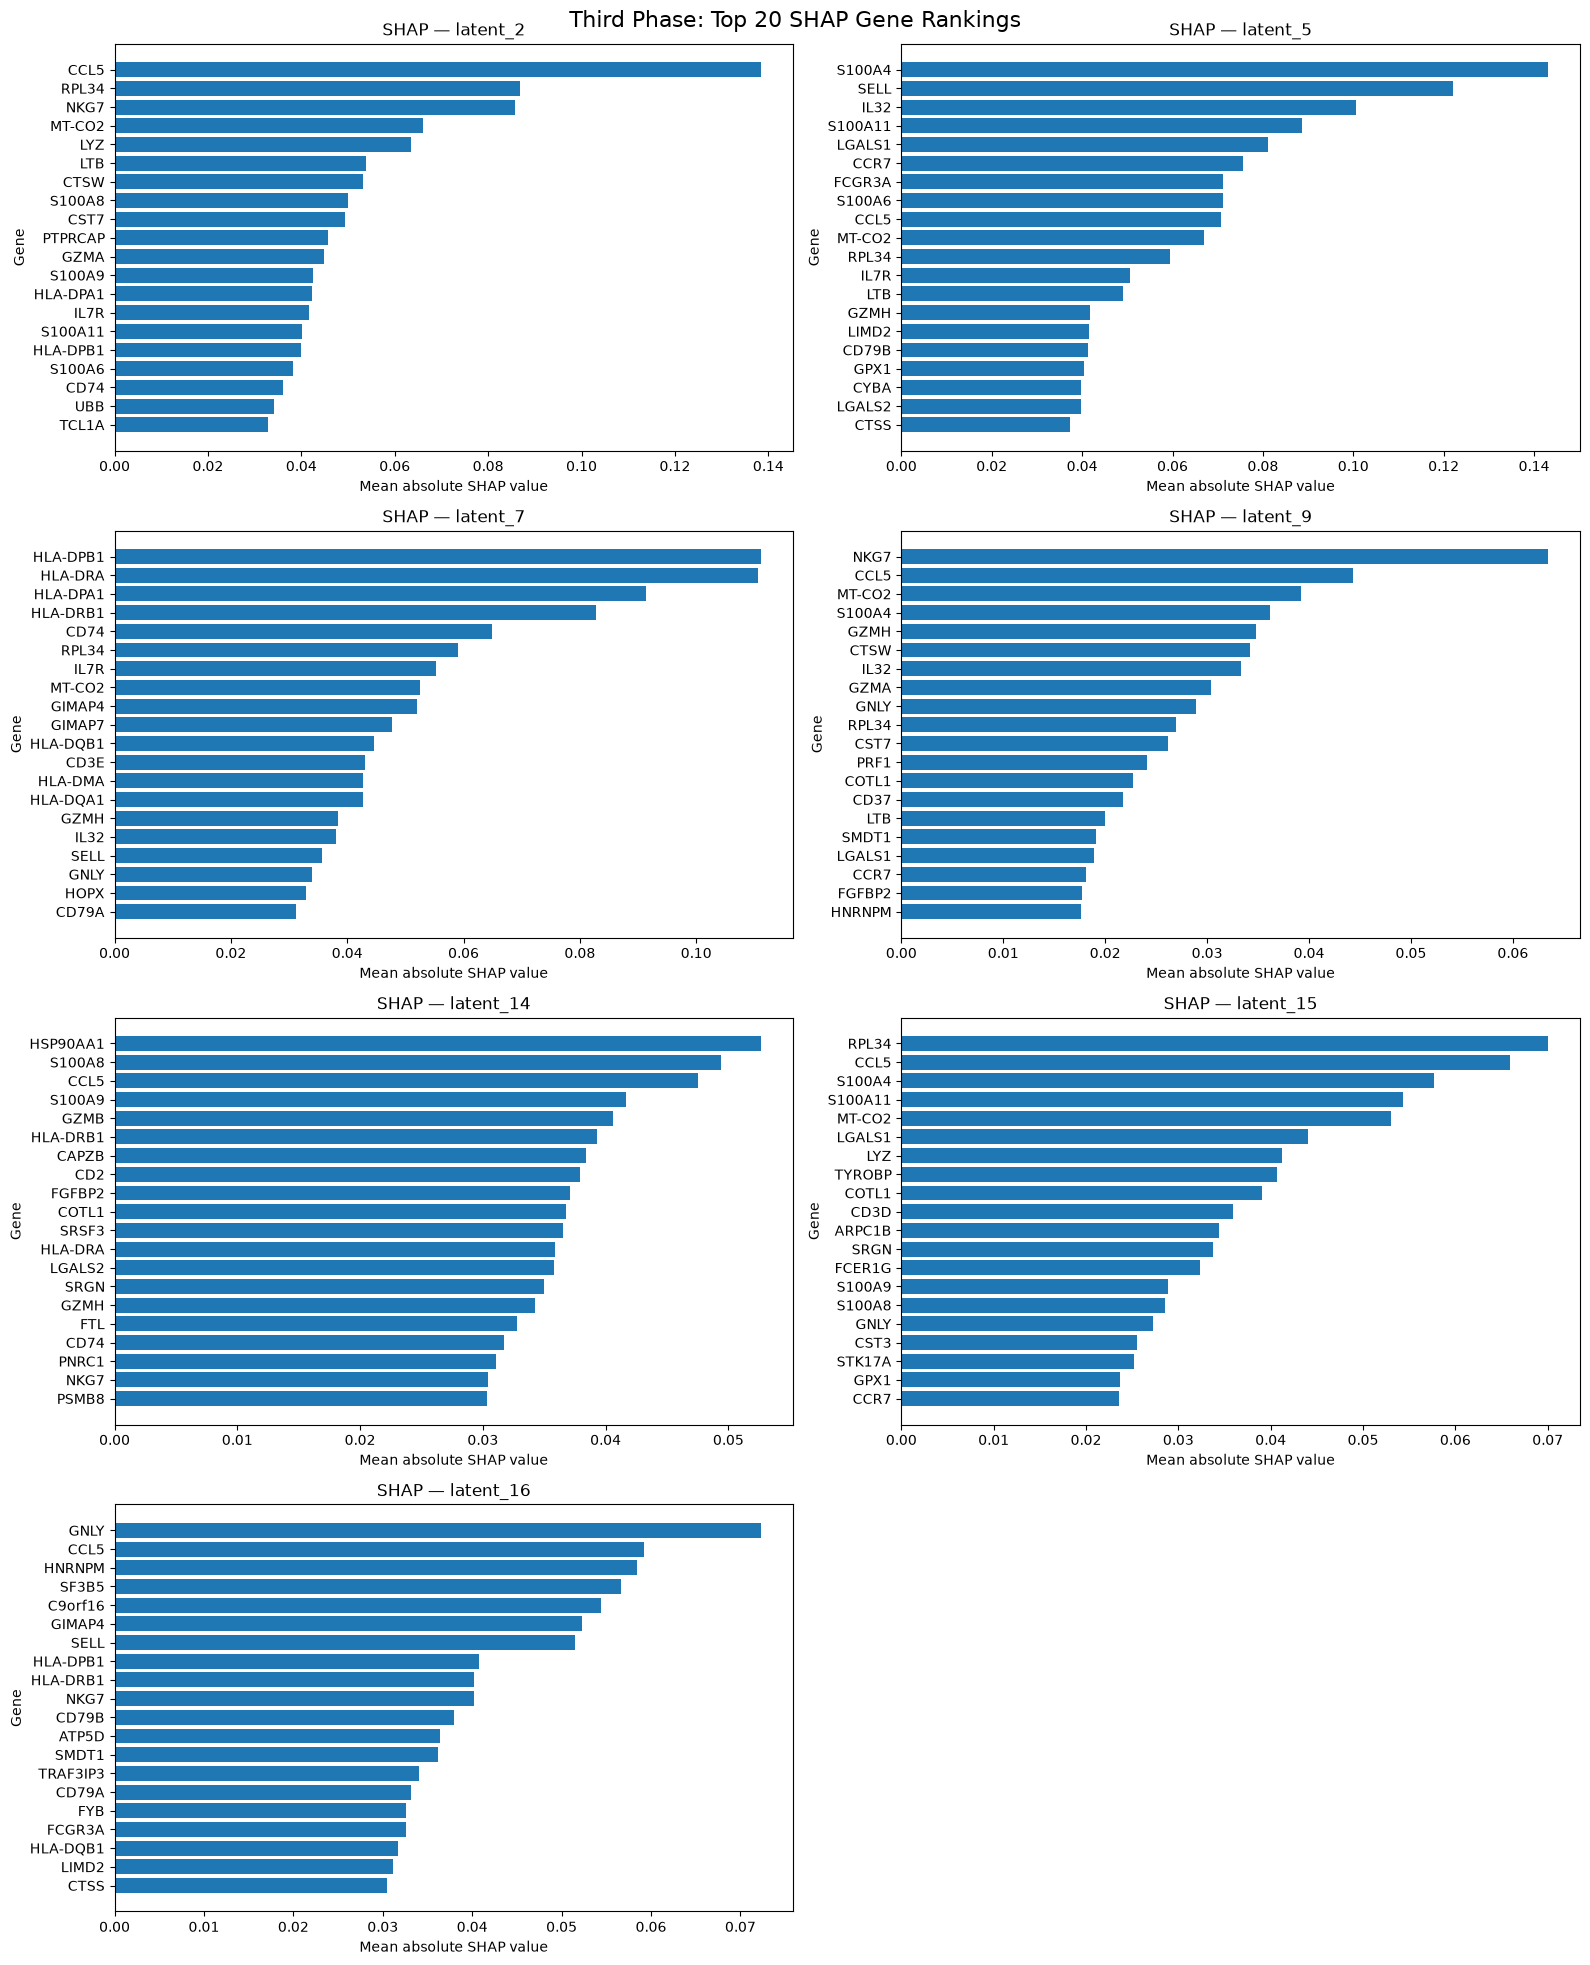

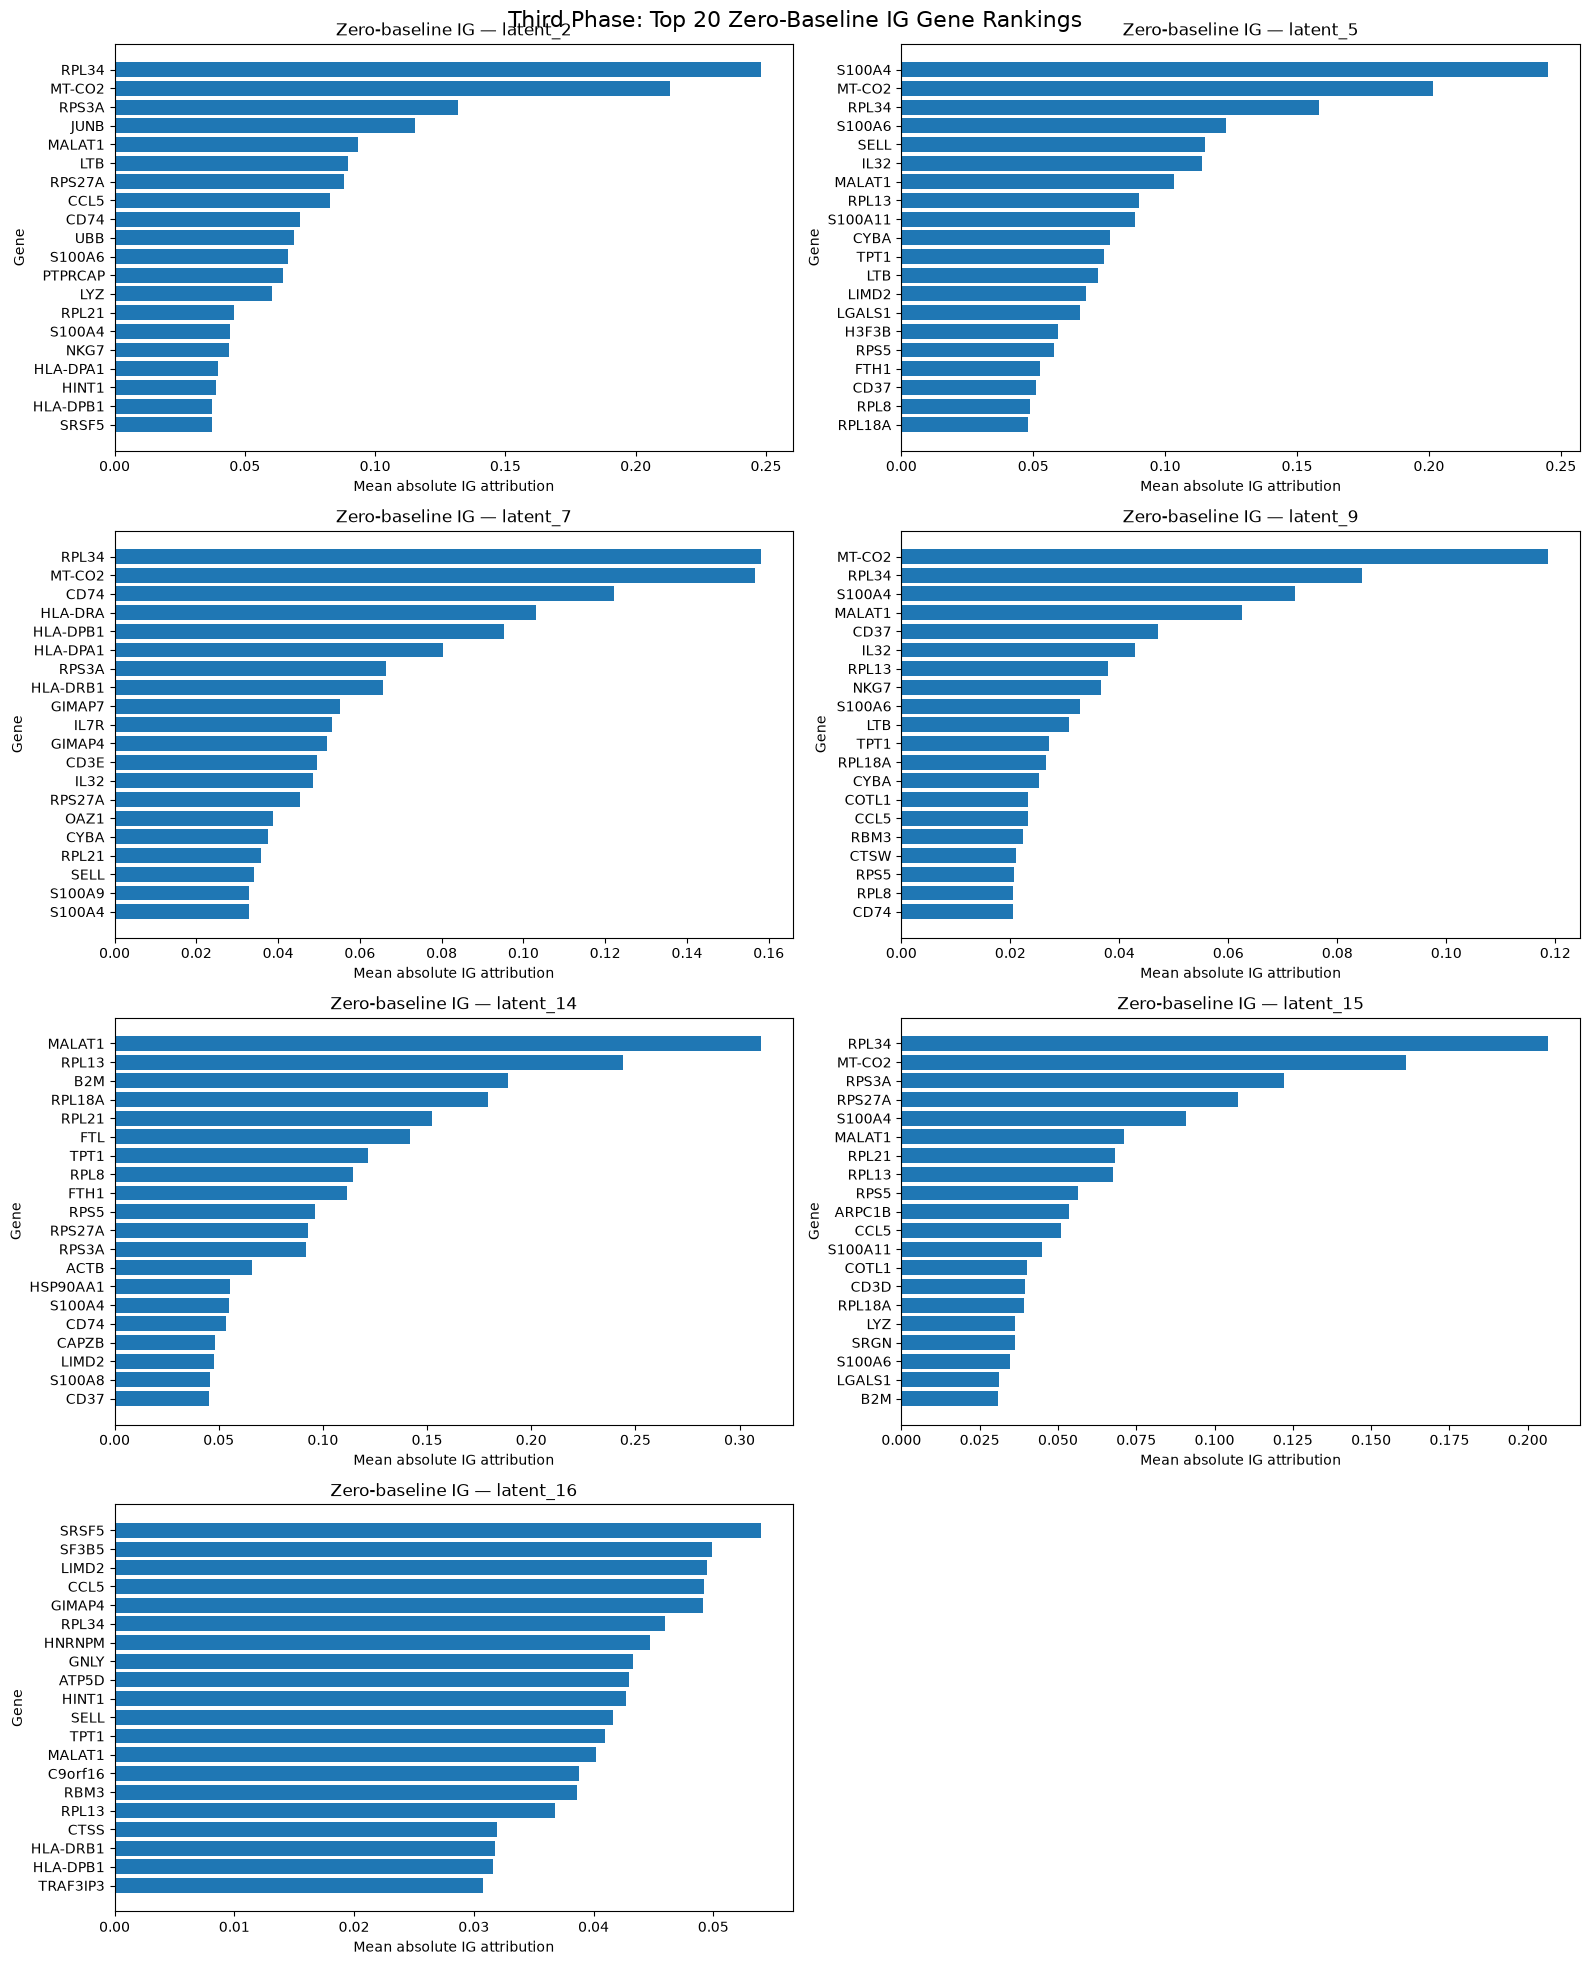

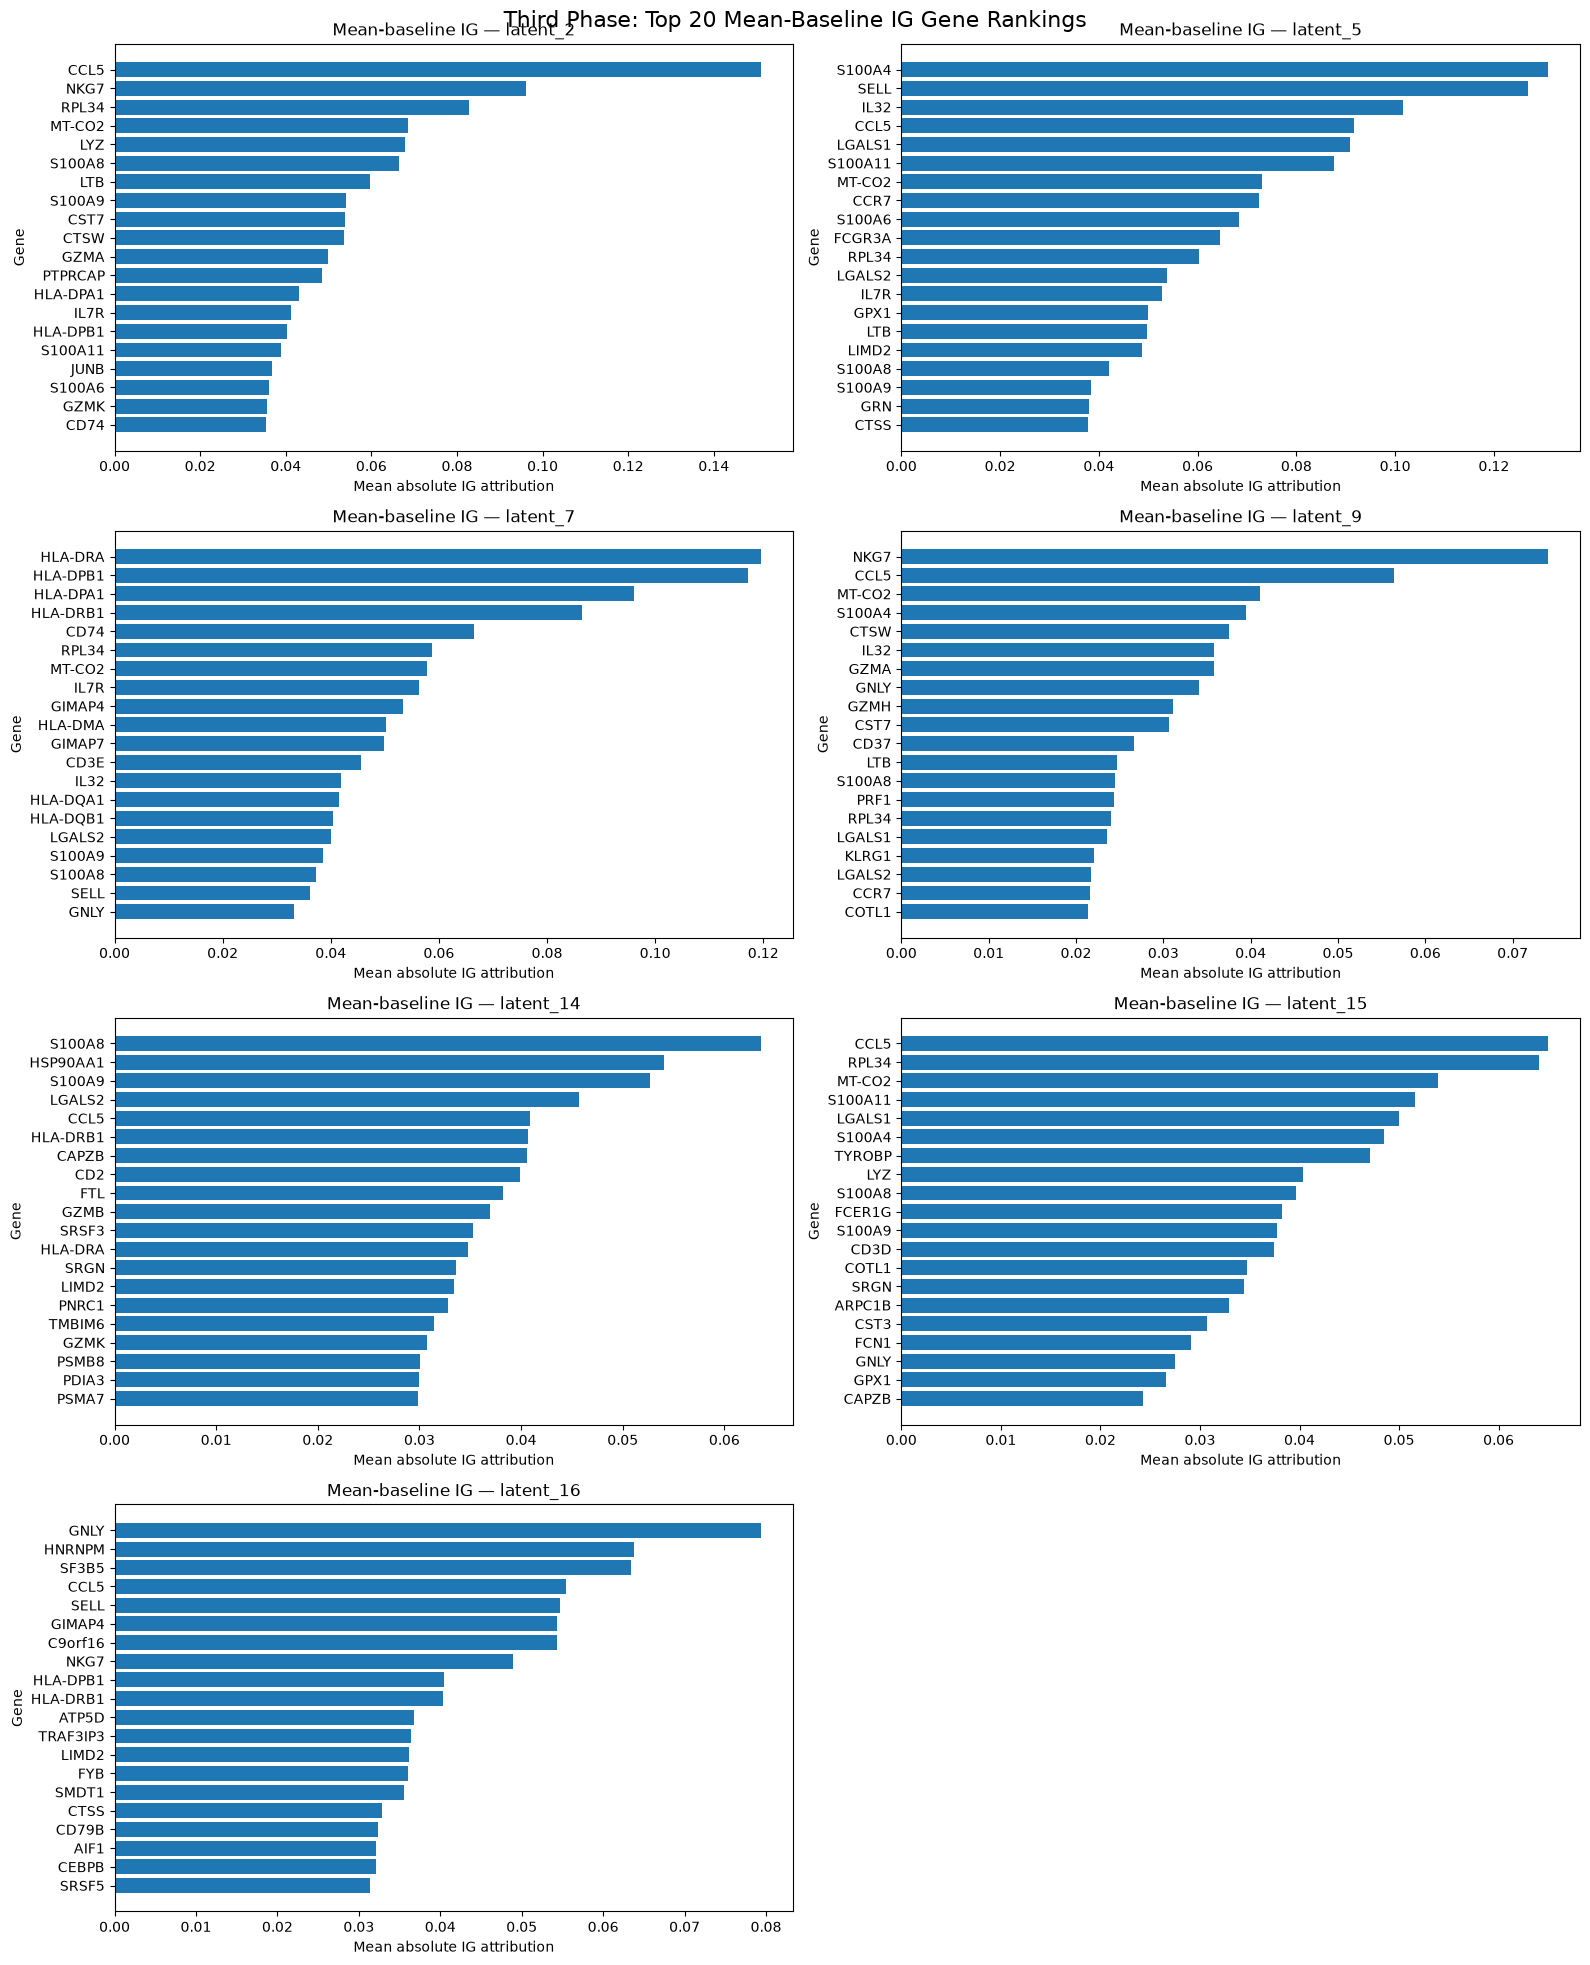


THIRD PHASE RANKING FIGURES SAVED
1. third_phase_shap_top20.png
2. third_phase_ig_zero_top20.png
3. third_phase_ig_mean_top20.png


In [126]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# THIRD PHASE: SHAP AND INTEGRATED GRADIENTS GENE RANKINGS
# ============================================================

figure_dir = ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# Load existing ranking results
shap_df = pd.read_csv(
    ROOT / "outputs/shap/shap_gene_ranking.csv"
)

ig_zero_df = pd.read_csv(
    ROOT / "outputs/attributions/ig_zero_ranking.csv"
)

ig_mean_df = pd.read_csv(
    ROOT / "outputs/attributions/ig_mean_ranking.csv"
)

# Use the seven active latent dimensions only
active_dims = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

# Filter SHAP ranking
shap_active = shap_df[
    shap_df["latent_dimension"].isin(active_dims)
].copy()

# Filter IG rankings
ig_zero_active = ig_zero_df[
    ig_zero_df["dimension"].isin(active_dims)
].copy()

ig_mean_active = ig_mean_df[
    ig_mean_df["dimension"].isin(active_dims)
].copy()

# Display verification
print("THIRD PHASE FIGURE DATA")
print("=" * 60)
print("SHAP:", shap_active.shape)
print("Zero-baseline IG:", ig_zero_active.shape)
print("Mean-baseline IG:", ig_mean_active.shape)

# ------------------------------------------------------------
# 1. SHAP TOP 20 GENES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 20)
)

axes = axes.flatten()

for i, dim in enumerate(active_dims):
    subset = (
        shap_active[
            shap_active["latent_dimension"] == dim
        ]
        .sort_values("rank")
        .head(20)
        .sort_values("mean_absolute_shap")
    )

    axes[i].barh(
        subset["gene"],
        subset["mean_absolute_shap"]
    )

    axes[i].set_title(f"SHAP — {dim}")
    axes[i].set_xlabel("Mean absolute SHAP value")
    axes[i].set_ylabel("Gene")

axes[-1].axis("off")

fig.suptitle(
    "Third Phase: Top 20 SHAP Gene Rankings",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_shap_top20.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 2. ZERO-BASELINE IG TOP 20 GENES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 20)
)

axes = axes.flatten()

for i, dim in enumerate(active_dims):
    subset = (
        ig_zero_active[
            ig_zero_active["dimension"] == dim
        ]
        .sort_values("rank")
        .head(20)
        .sort_values("mean_abs_ig")
    )

    axes[i].barh(
        subset["gene"],
        subset["mean_abs_ig"]
    )

    axes[i].set_title(f"Zero-baseline IG — {dim}")
    axes[i].set_xlabel("Mean absolute IG attribution")
    axes[i].set_ylabel("Gene")

axes[-1].axis("off")

fig.suptitle(
    "Third Phase: Top 20 Zero-Baseline IG Gene Rankings",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_ig_zero_top20.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. MEAN-BASELINE IG TOP 20 GENES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 20)
)

axes = axes.flatten()

for i, dim in enumerate(active_dims):
    subset = (
        ig_mean_active[
            ig_mean_active["dimension"] == dim
        ]
        .sort_values("rank")
        .head(20)
        .sort_values("mean_abs_ig")
    )

    axes[i].barh(
        subset["gene"],
        subset["mean_abs_ig"]
    )

    axes[i].set_title(f"Mean-baseline IG — {dim}")
    axes[i].set_xlabel("Mean absolute IG attribution")
    axes[i].set_ylabel("Gene")

axes[-1].axis("off")

fig.suptitle(
    "Third Phase: Top 20 Mean-Baseline IG Gene Rankings",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_ig_mean_top20.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nTHIRD PHASE RANKING FIGURES SAVED")
print("1. third_phase_shap_top20.png")
print("2. third_phase_ig_zero_top20.png")
print("3. third_phase_ig_mean_top20.png")


THIRD PHASE: SHAP VERSUS IG
Comparison table: (7, 5)
Gene-list table: (7, 4)


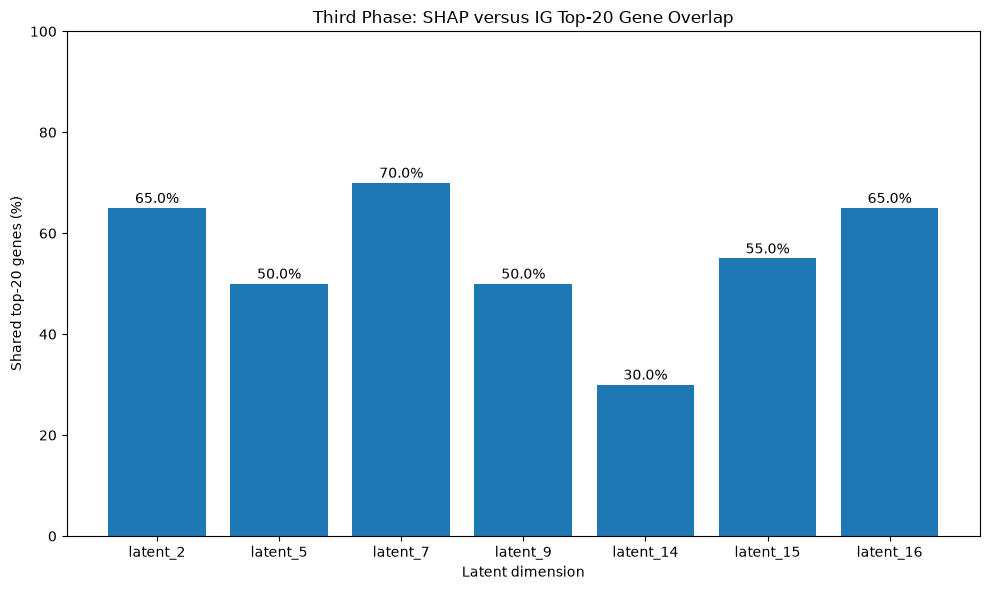

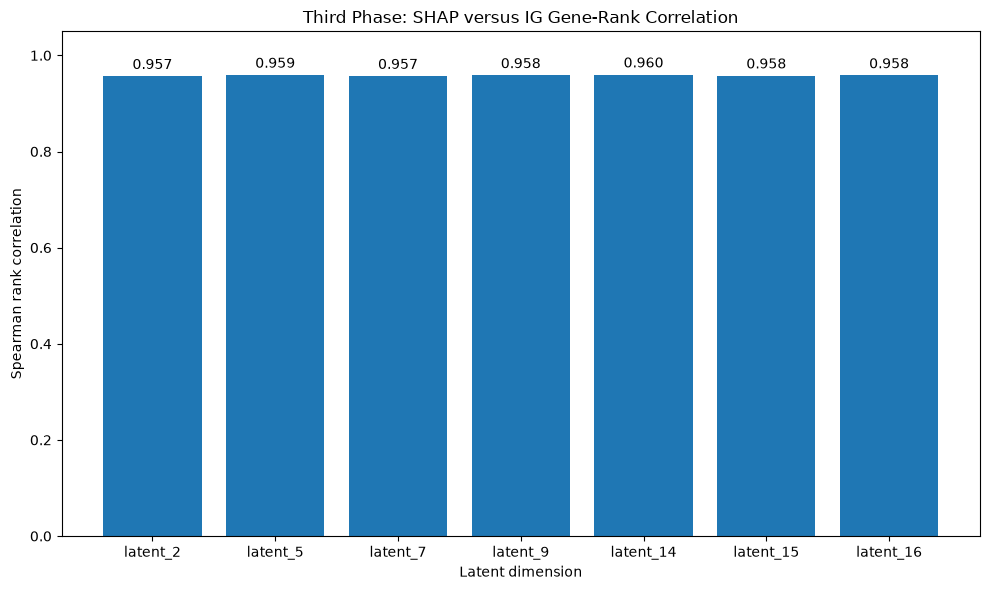

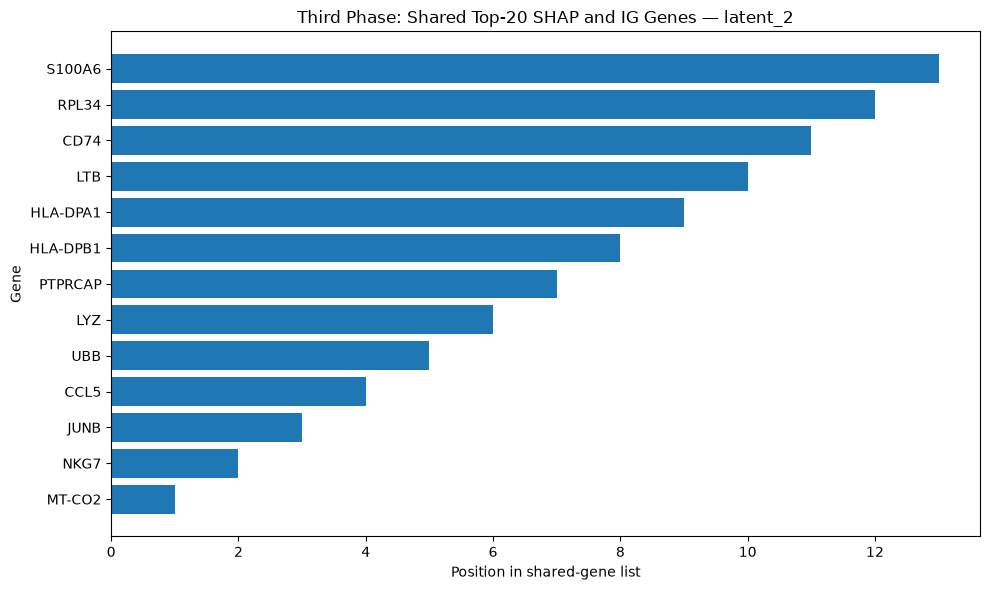

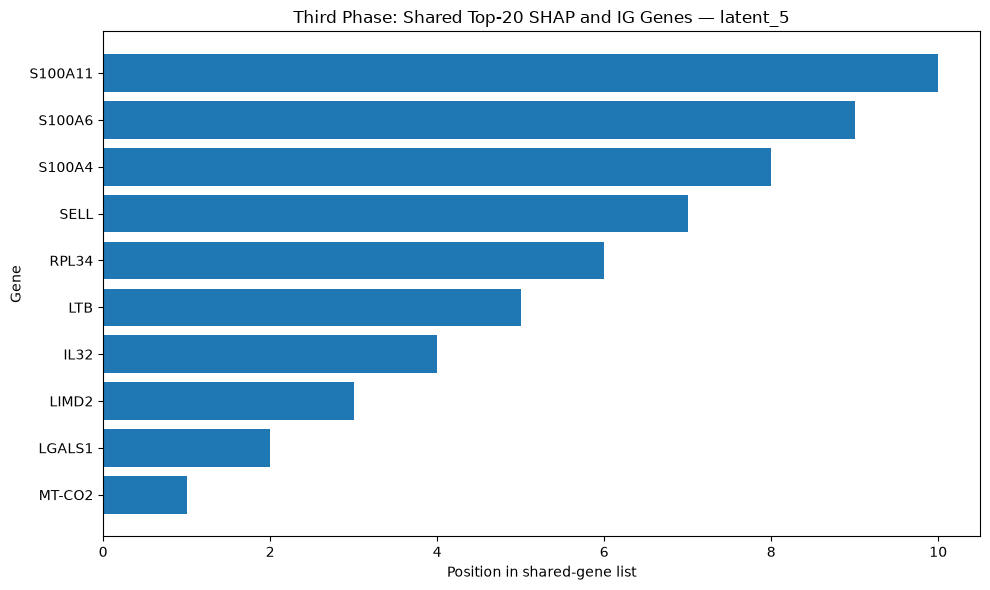

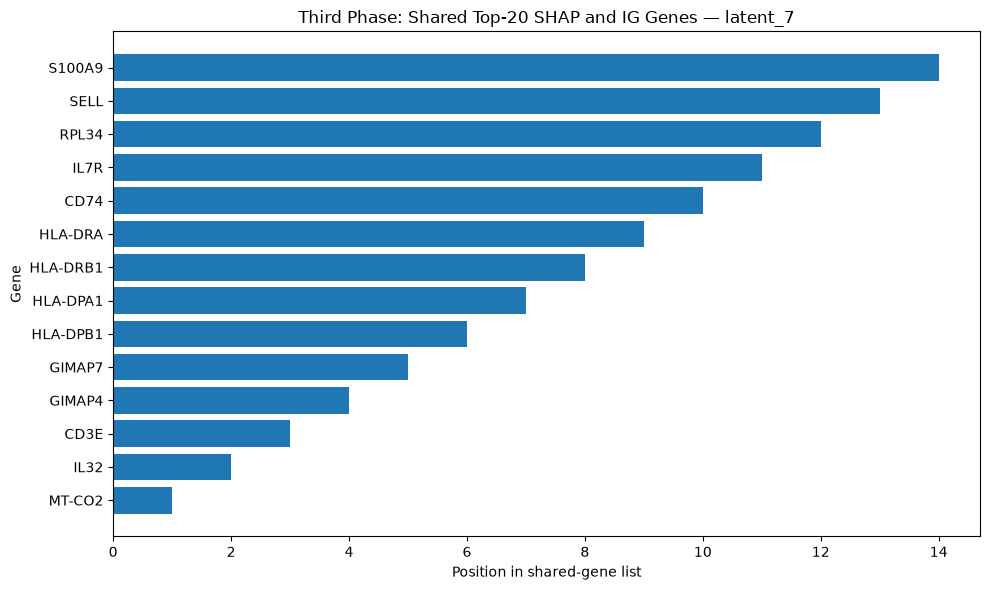

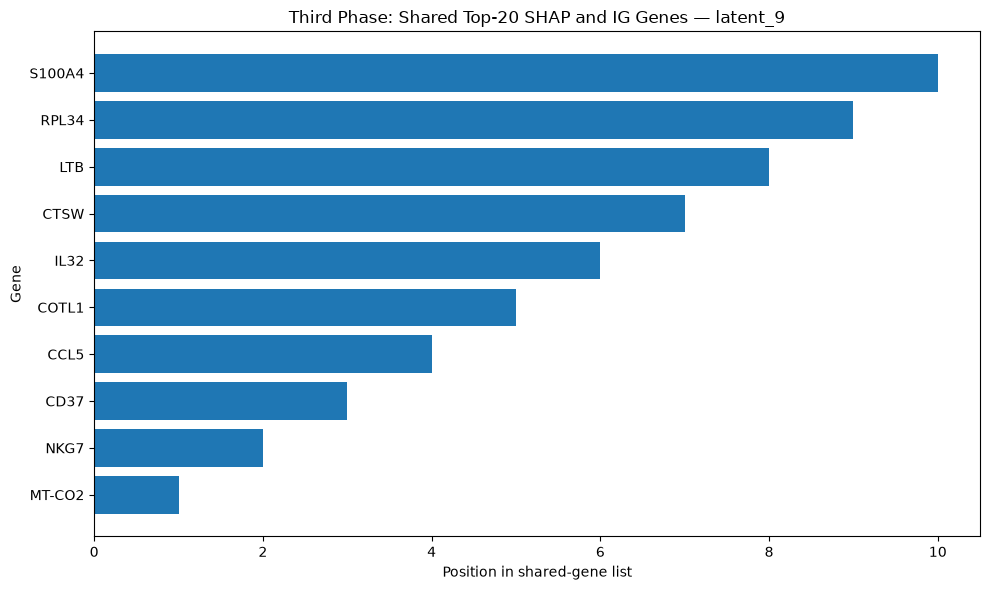

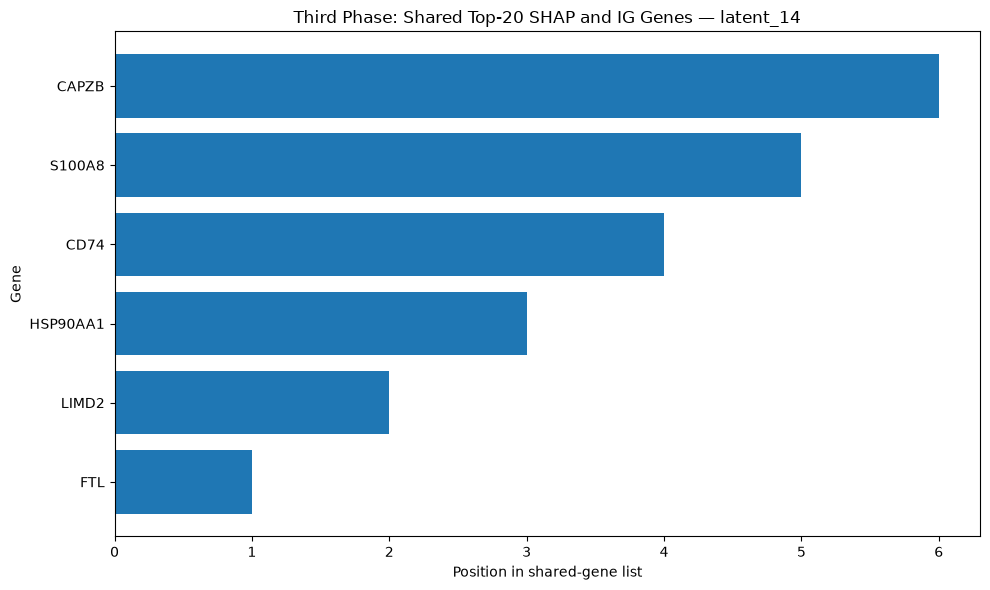

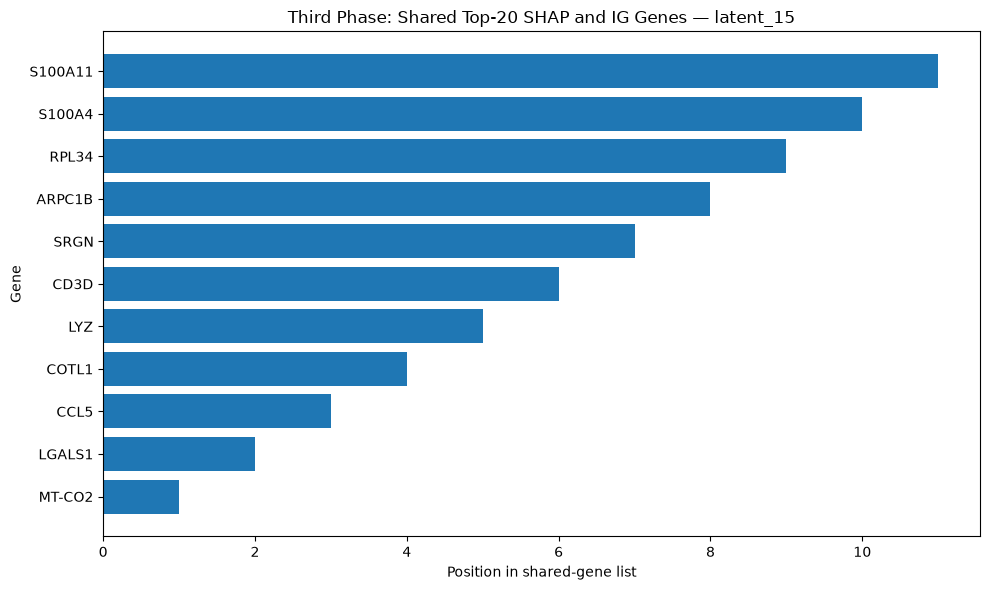

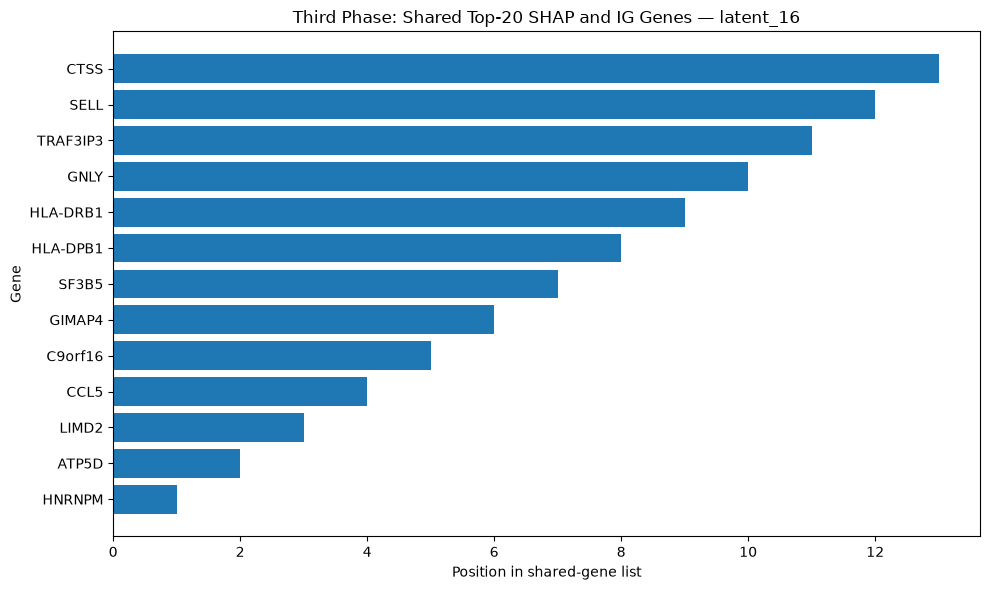


THIRD PHASE SHAP-VERSUS-IG FIGURES SAVED
1. third_phase_shap_ig_top20_overlap.png
2. third_phase_shap_ig_spearman.png
3. Seven shared-gene figures, one per active dimension.


In [127]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# THIRD PHASE: SHAP VERSUS IG COMPARISON FIGURES
# ============================================================

figure_dir = ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

active_dims = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

# Load existing comparison results
comparison_df = pd.read_csv(
    ROOT / "outputs/shap/shap_vs_ig_test528_summary.csv"
)

gene_lists_df = pd.read_csv(
    ROOT / "outputs/shap/shap_vs_ig_test528_gene_lists.csv"
)

# Verify data
print("THIRD PHASE: SHAP VERSUS IG")
print("=" * 60)
print("Comparison table:", comparison_df.shape)
print("Gene-list table:", gene_lists_df.shape)

# ------------------------------------------------------------
# 1. TOP-20 GENE OVERLAP
# ------------------------------------------------------------

comparison_df = comparison_df[
    comparison_df["latent_dimension"].isin(active_dims)
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    comparison_df["latent_dimension"],
    comparison_df["top20_overlap_percent"]
)

ax.set_title(
    "Third Phase: SHAP versus IG Top-20 Gene Overlap"
)
ax.set_xlabel("Latent dimension")
ax.set_ylabel("Shared top-20 genes (%)")
ax.set_ylim(0, 100)

for bar, value in zip(
    bars,
    comparison_df["top20_overlap_percent"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_shap_ig_top20_overlap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 2. SPEARMAN RANK CORRELATION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    comparison_df["latent_dimension"],
    comparison_df["spearman_rank_correlation"]
)

ax.set_title(
    "Third Phase: SHAP versus IG Gene-Rank Correlation"
)
ax.set_xlabel("Latent dimension")
ax.set_ylabel("Spearman rank correlation")
ax.set_ylim(0, 1.05)

for bar, value in zip(
    bars,
    comparison_df["spearman_rank_correlation"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_shap_ig_spearman.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. SHARED TOP-20 GENES BY LATENT DIMENSION
# ------------------------------------------------------------

for dim in active_dims:

    row = gene_lists_df[
        gene_lists_df["latent_dimension"] == dim
    ]

    if row.empty:
        print(f"Skipping {dim}: no gene-list data")
        continue

    shared_genes = str(
        row.iloc[0]["shared_top20_genes"]
    ).split(", ")

    shared_genes = [
        gene for gene in shared_genes
        if gene.strip() and gene.lower() != "nan"
    ]

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.barh(
        shared_genes[::-1],
        range(1, len(shared_genes) + 1)
    )

    ax.set_title(
        f"Third Phase: Shared Top-20 SHAP and IG Genes — {dim}"
    )
    ax.set_xlabel("Position in shared-gene list")
    ax.set_ylabel("Gene")

    plt.tight_layout()

    fig.savefig(
        figure_dir / f"third_phase_shared_genes_{dim}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

print("\nTHIRD PHASE SHAP-VERSUS-IG FIGURES SAVED")
print("1. third_phase_shap_ig_top20_overlap.png")
print("2. third_phase_shap_ig_spearman.png")
print("3. Seven shared-gene figures, one per active dimension.")


THIRD PHASE: IG BASELINE SENSITIVITY
Spearman comparison: (7, 3)
Top-20 overlap: (7, 4)


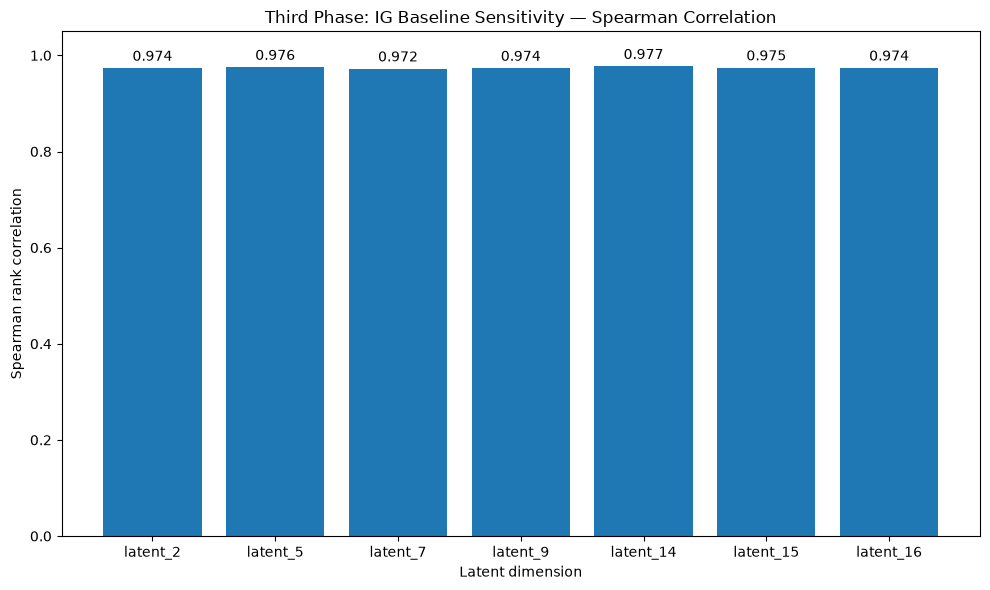

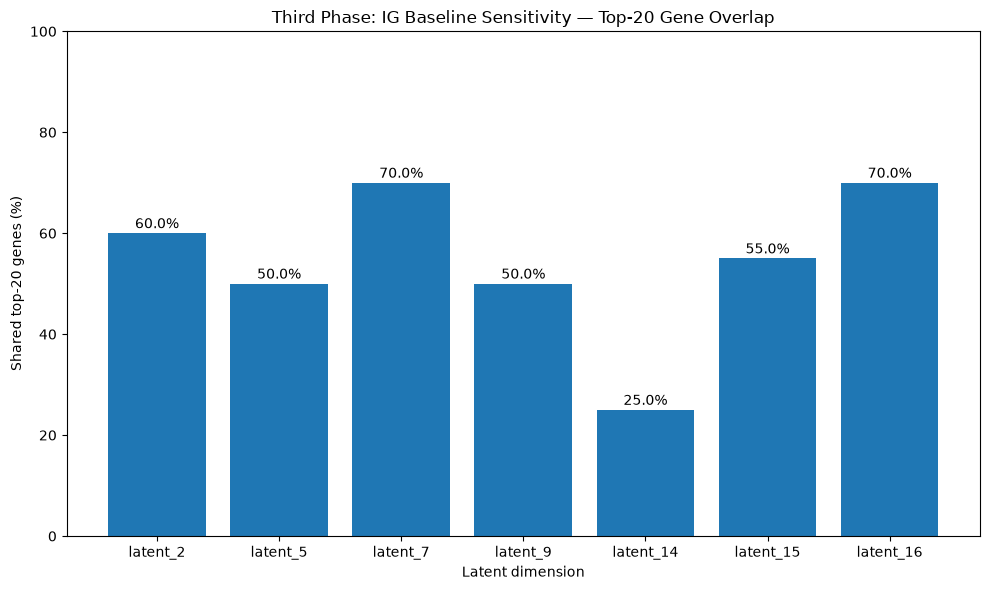


THIRD PHASE BASELINE FIGURES SAVED
1. third_phase_ig_baseline_spearman.png
2. third_phase_ig_baseline_top20_overlap.png


In [128]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# THIRD PHASE: INTEGRATED GRADIENTS BASELINE SENSITIVITY
# ============================================================

figure_dir = ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

active_dims = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

# Load existing comparison results
baseline_spearman = pd.read_csv(
    ROOT / "outputs/attributions/ig_baseline_spearman_comparison.csv"
)

baseline_overlap = pd.read_csv(
    ROOT / "outputs/attributions/ig_baseline_top20_overlap.csv"
)

# Filter active dimensions
baseline_spearman = baseline_spearman[
    baseline_spearman["dimension"].isin(active_dims)
].copy()

baseline_overlap = baseline_overlap[
    baseline_overlap["dimension"].isin(active_dims)
].copy()

# Verify data
print("THIRD PHASE: IG BASELINE SENSITIVITY")
print("=" * 60)
print("Spearman comparison:", baseline_spearman.shape)
print("Top-20 overlap:", baseline_overlap.shape)

# ------------------------------------------------------------
# 1. ZERO-BASELINE VS MEAN-BASELINE SPEARMAN CORRELATION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    baseline_spearman["dimension"],
    baseline_spearman["spearman_rho"]
)

ax.set_title(
    "Third Phase: IG Baseline Sensitivity — Spearman Correlation"
)
ax.set_xlabel("Latent dimension")
ax.set_ylabel("Spearman rank correlation")
ax.set_ylim(0, 1.05)

for bar, value in zip(
    bars,
    baseline_spearman["spearman_rho"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_ig_baseline_spearman.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 2. ZERO-BASELINE VS MEAN-BASELINE TOP-20 OVERLAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    baseline_overlap["dimension"],
    baseline_overlap["overlap_percent"]
)

ax.set_title(
    "Third Phase: IG Baseline Sensitivity — Top-20 Gene Overlap"
)
ax.set_xlabel("Latent dimension")
ax.set_ylabel("Shared top-20 genes (%)")
ax.set_ylim(0, 100)

for bar, value in zip(
    bars,
    baseline_overlap["overlap_percent"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_ig_baseline_top20_overlap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

print("\nTHIRD PHASE BASELINE FIGURES SAVED")
print("1. third_phase_ig_baseline_spearman.png")
print("2. third_phase_ig_baseline_top20_overlap.png")


THIRD PHASE: MARKER RANKING
Marker comparison shape: (84, 5)
Columns: ['latent_dimension', 'gene', 'rank_ig', 'rank_shap', 'rank_difference_shap_minus_ig']


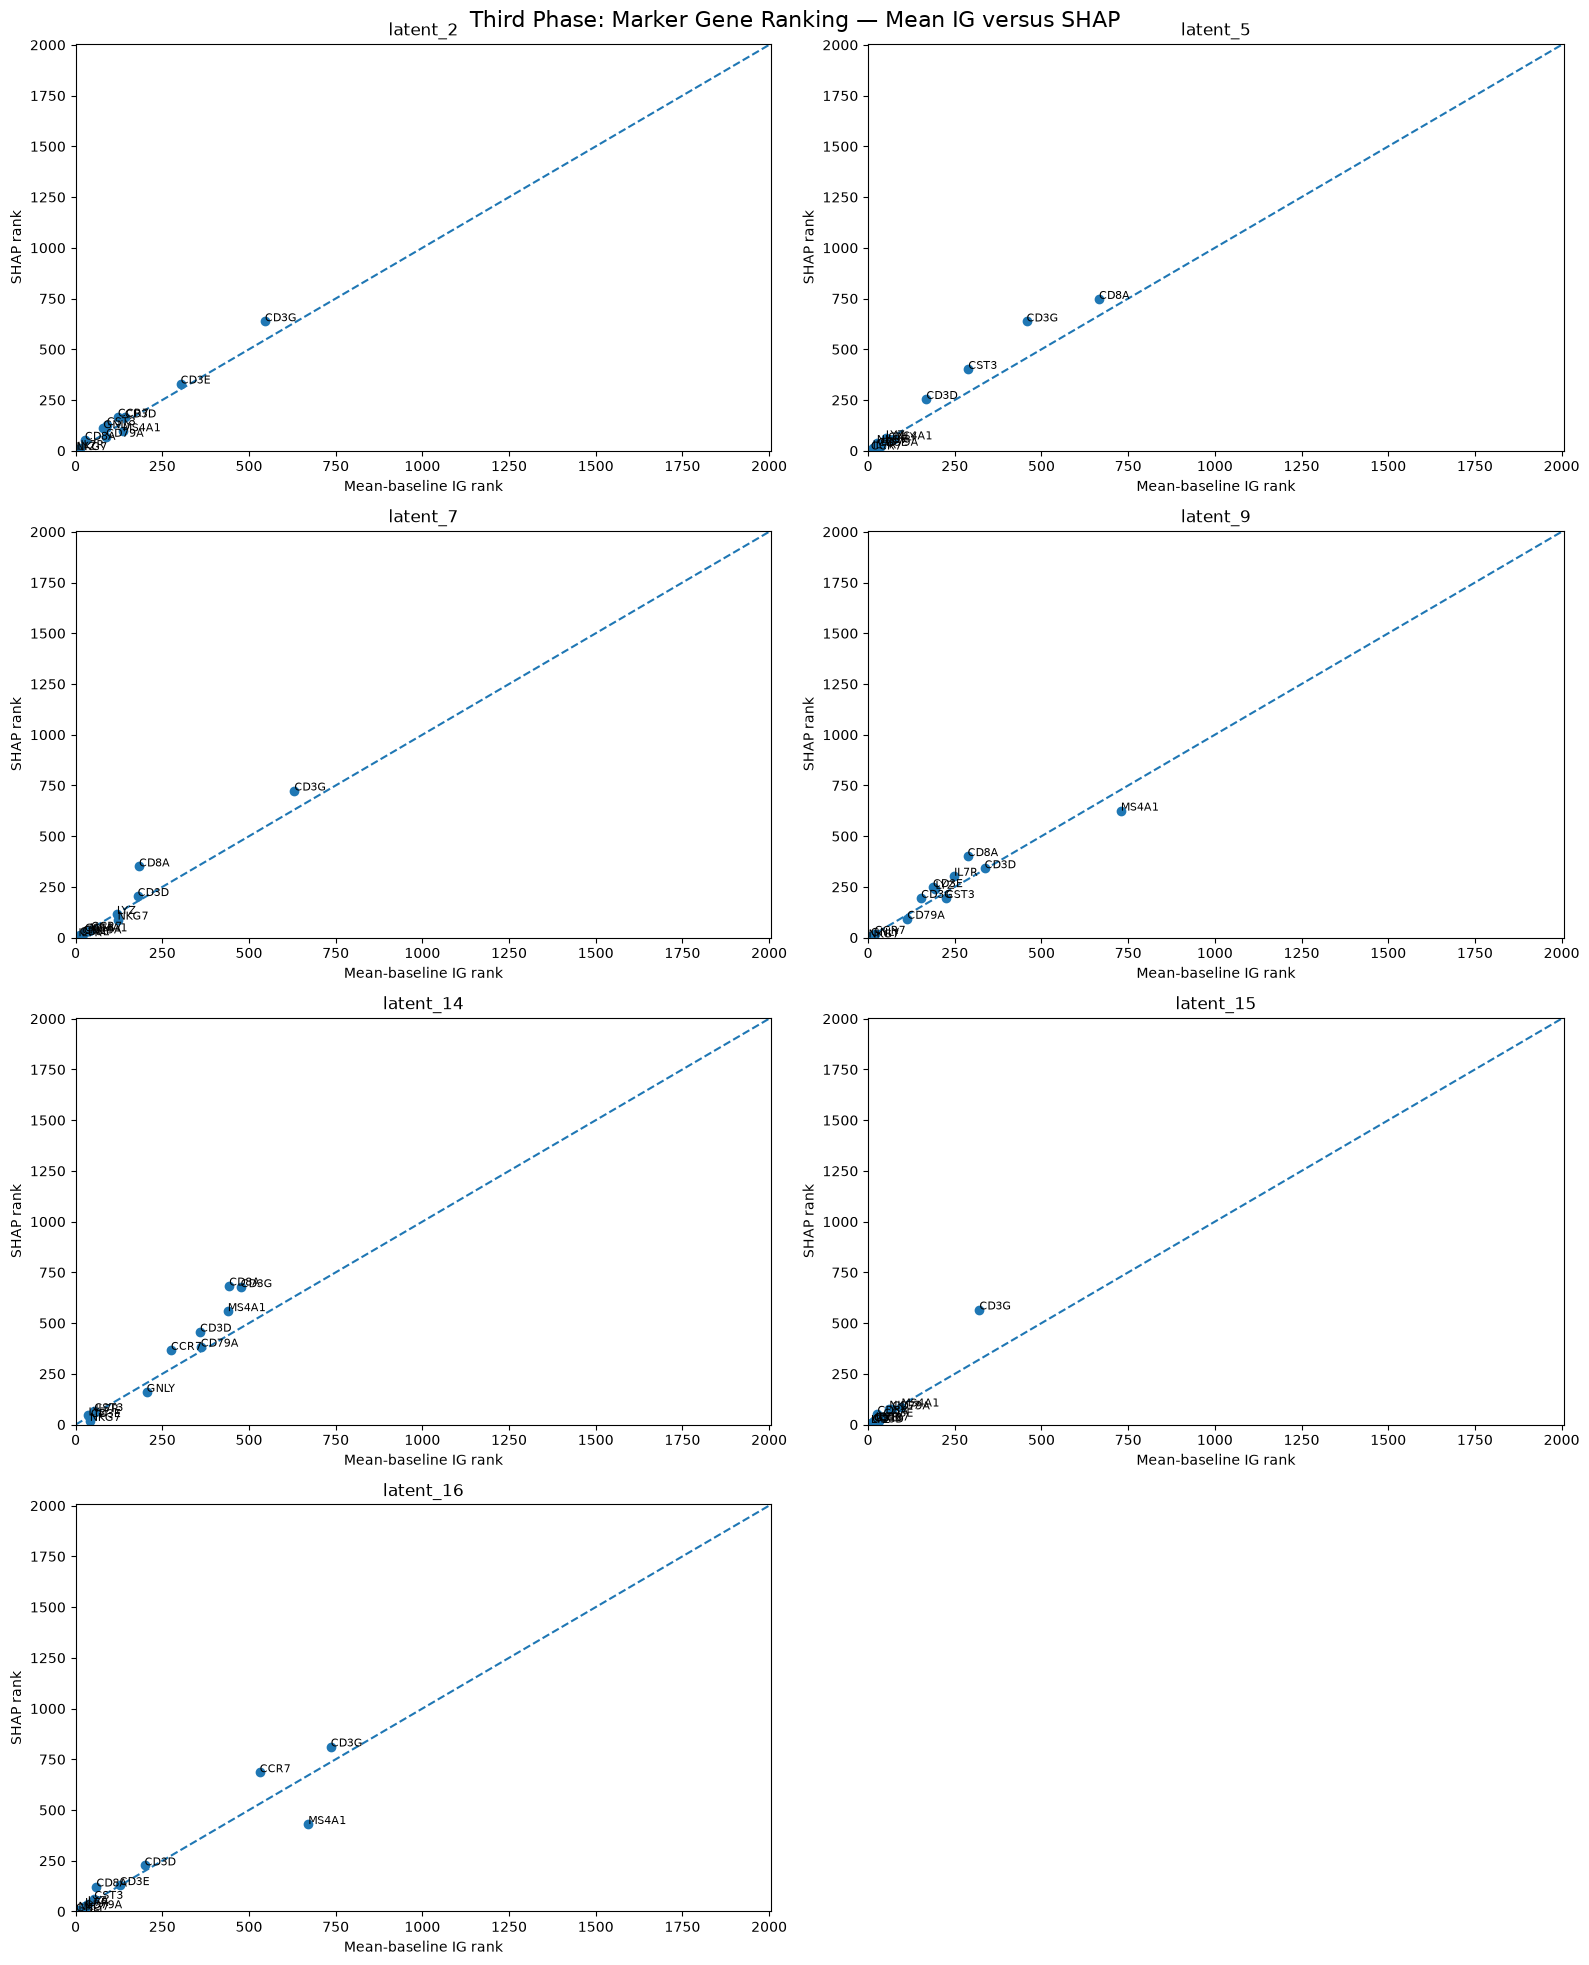


Saved: third_phase_marker_rank_ig_vs_shap.png

THIRD PHASE: COMPLETENESS DATA SOURCES

Zero-baseline IG
--------------------------------------------------
Shape: (7, 5)
Columns: ['dimension', 'mean_abs_completeness_error', 'max_abs_completeness_error', 'output_sd', 'mean_error_over_output_sd']


,dimension,mean_abs_completeness_error,max_abs_completeness_error,output_sd,mean_error_over_output_sd
0,latent_2,0.005180,0.020843,0.970521,0.005338
1,latent_5,0.005541,0.019393,0.896474,0.006180
2,latent_7,0.006305,0.024323,1.027507,0.006137



Mean-baseline IG
--------------------------------------------------
Shape: (7, 5)
Columns: ['dimension', 'mean_abs_completeness_error', 'max_abs_completeness_error', 'output_sd', 'mean_error_over_output_sd']


,dimension,mean_abs_completeness_error,max_abs_completeness_error,output_sd,mean_error_over_output_sd
0,latent_2,0.004960,0.030061,0.971441,0.005105
1,latent_5,0.005750,0.029637,0.897324,0.006408
2,latent_7,0.004351,0.023009,1.028481,0.004231



SHAP additivity
--------------------------------------------------
Shape: (16, 6)
Columns: ['latent_dimension', 'mean_absolute_error', 'max_absolute_error', 'output_sd', 'mean_output_difference', 'max_error_over_output_sd']


,latent_dimension,mean_absolute_error,max_absolute_error,output_sd,mean_output_difference,max_error_over_output_sd
0,latent_1,0.023227,0.093883,0.083298,0.068323,1.127074
1,latent_2,0.203404,0.751329,1.027609,0.840170,0.731143
2,latent_3,0.018959,0.060869,0.065148,0.053770,0.934324



Final SHAP additivity
--------------------------------------------------
Shape: (32, 8)
Columns: ['seed', 'latent_dimension', 'mean_absolute_error', 'max_absolute_error', 'output_sd', 'mean_absolute_output_gap', 'mean_error_over_output_sd', 'mean_error_over_output_gap']


,seed,latent_dimension,mean_absolute_error,max_absolute_error,output_sd,mean_absolute_output_gap,mean_error_over_output_sd,mean_error_over_output_gap
0,0,latent_1,0.007544,0.031996,0.081753,0.069487,0.092280,0.108569
1,0,latent_2,0.043271,0.237339,0.970521,0.784635,0.044586,0.055148
2,0,latent_3,0.005579,0.026547,0.066709,0.053506,0.083638,0.104277



COMPLETENESS DATA SOURCE VERIFICATION COMPLETED


In [129]:

import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# THIRD PHASE: MARKER RANKING COMPARISON
# ============================================================

figure_dir = ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

active_dims = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

# Load existing marker-ranking comparison
marker_df = pd.read_csv(
    ROOT / "outputs/attributions/ig_mean_vs_shap_marker_ranks.csv"
)

marker_df = marker_df[
    marker_df["latent_dimension"].isin(active_dims)
].copy()

print("THIRD PHASE: MARKER RANKING")
print("=" * 60)
print("Marker comparison shape:", marker_df.shape)
print("Columns:", marker_df.columns.tolist())

# ------------------------------------------------------------
# Plot IG versus SHAP marker ranks
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 20)
)

axes = axes.flatten()

for i, dim in enumerate(active_dims):

    subset = marker_df[
        marker_df["latent_dimension"] == dim
    ].copy()

    axes[i].scatter(
        subset["rank_ig"],
        subset["rank_shap"]
    )

    for _, row in subset.iterrows():
        axes[i].annotate(
            row["gene"],
            (row["rank_ig"], row["rank_shap"]),
            fontsize=8
        )

    axes[i].plot(
        [0, 2006],
        [0, 2006],
        linestyle="--"
    )

    axes[i].set_title(dim)
    axes[i].set_xlabel("Mean-baseline IG rank")
    axes[i].set_ylabel("SHAP rank")
    axes[i].set_xlim(0, 2006)
    axes[i].set_ylim(0, 2006)

axes[-1].axis("off")

fig.suptitle(
    "Third Phase: Marker Gene Ranking — Mean IG versus SHAP",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_marker_rank_ig_vs_shap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved: third_phase_marker_rank_ig_vs_shap.png")

# ============================================================
# THIRD PHASE: COMPLETENESS DATA SOURCE VERIFICATION
# ============================================================

completeness_files = {
    "Zero-baseline IG": (
        ROOT / "outputs/attributions/ig_zero_completeness.csv"
    ),
    "Mean-baseline IG": (
        ROOT / "outputs/attributions/ig_mean_completeness.csv"
    ),
    "SHAP additivity": (
        ROOT / "outputs/shap/shap_additivity_summary.csv"
    ),
    "Final SHAP additivity": (
        ROOT / "outputs/shap/shap_final_additivity_test528.csv"
    )
}

print("\nTHIRD PHASE: COMPLETENESS DATA SOURCES")
print("=" * 60)

for name, path in completeness_files.items():

    print(f"\n{name}")
    print("-" * 50)

    if path.exists():
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("File not found:", path)

print("\nCOMPLETENESS DATA SOURCE VERIFICATION COMPLETED")


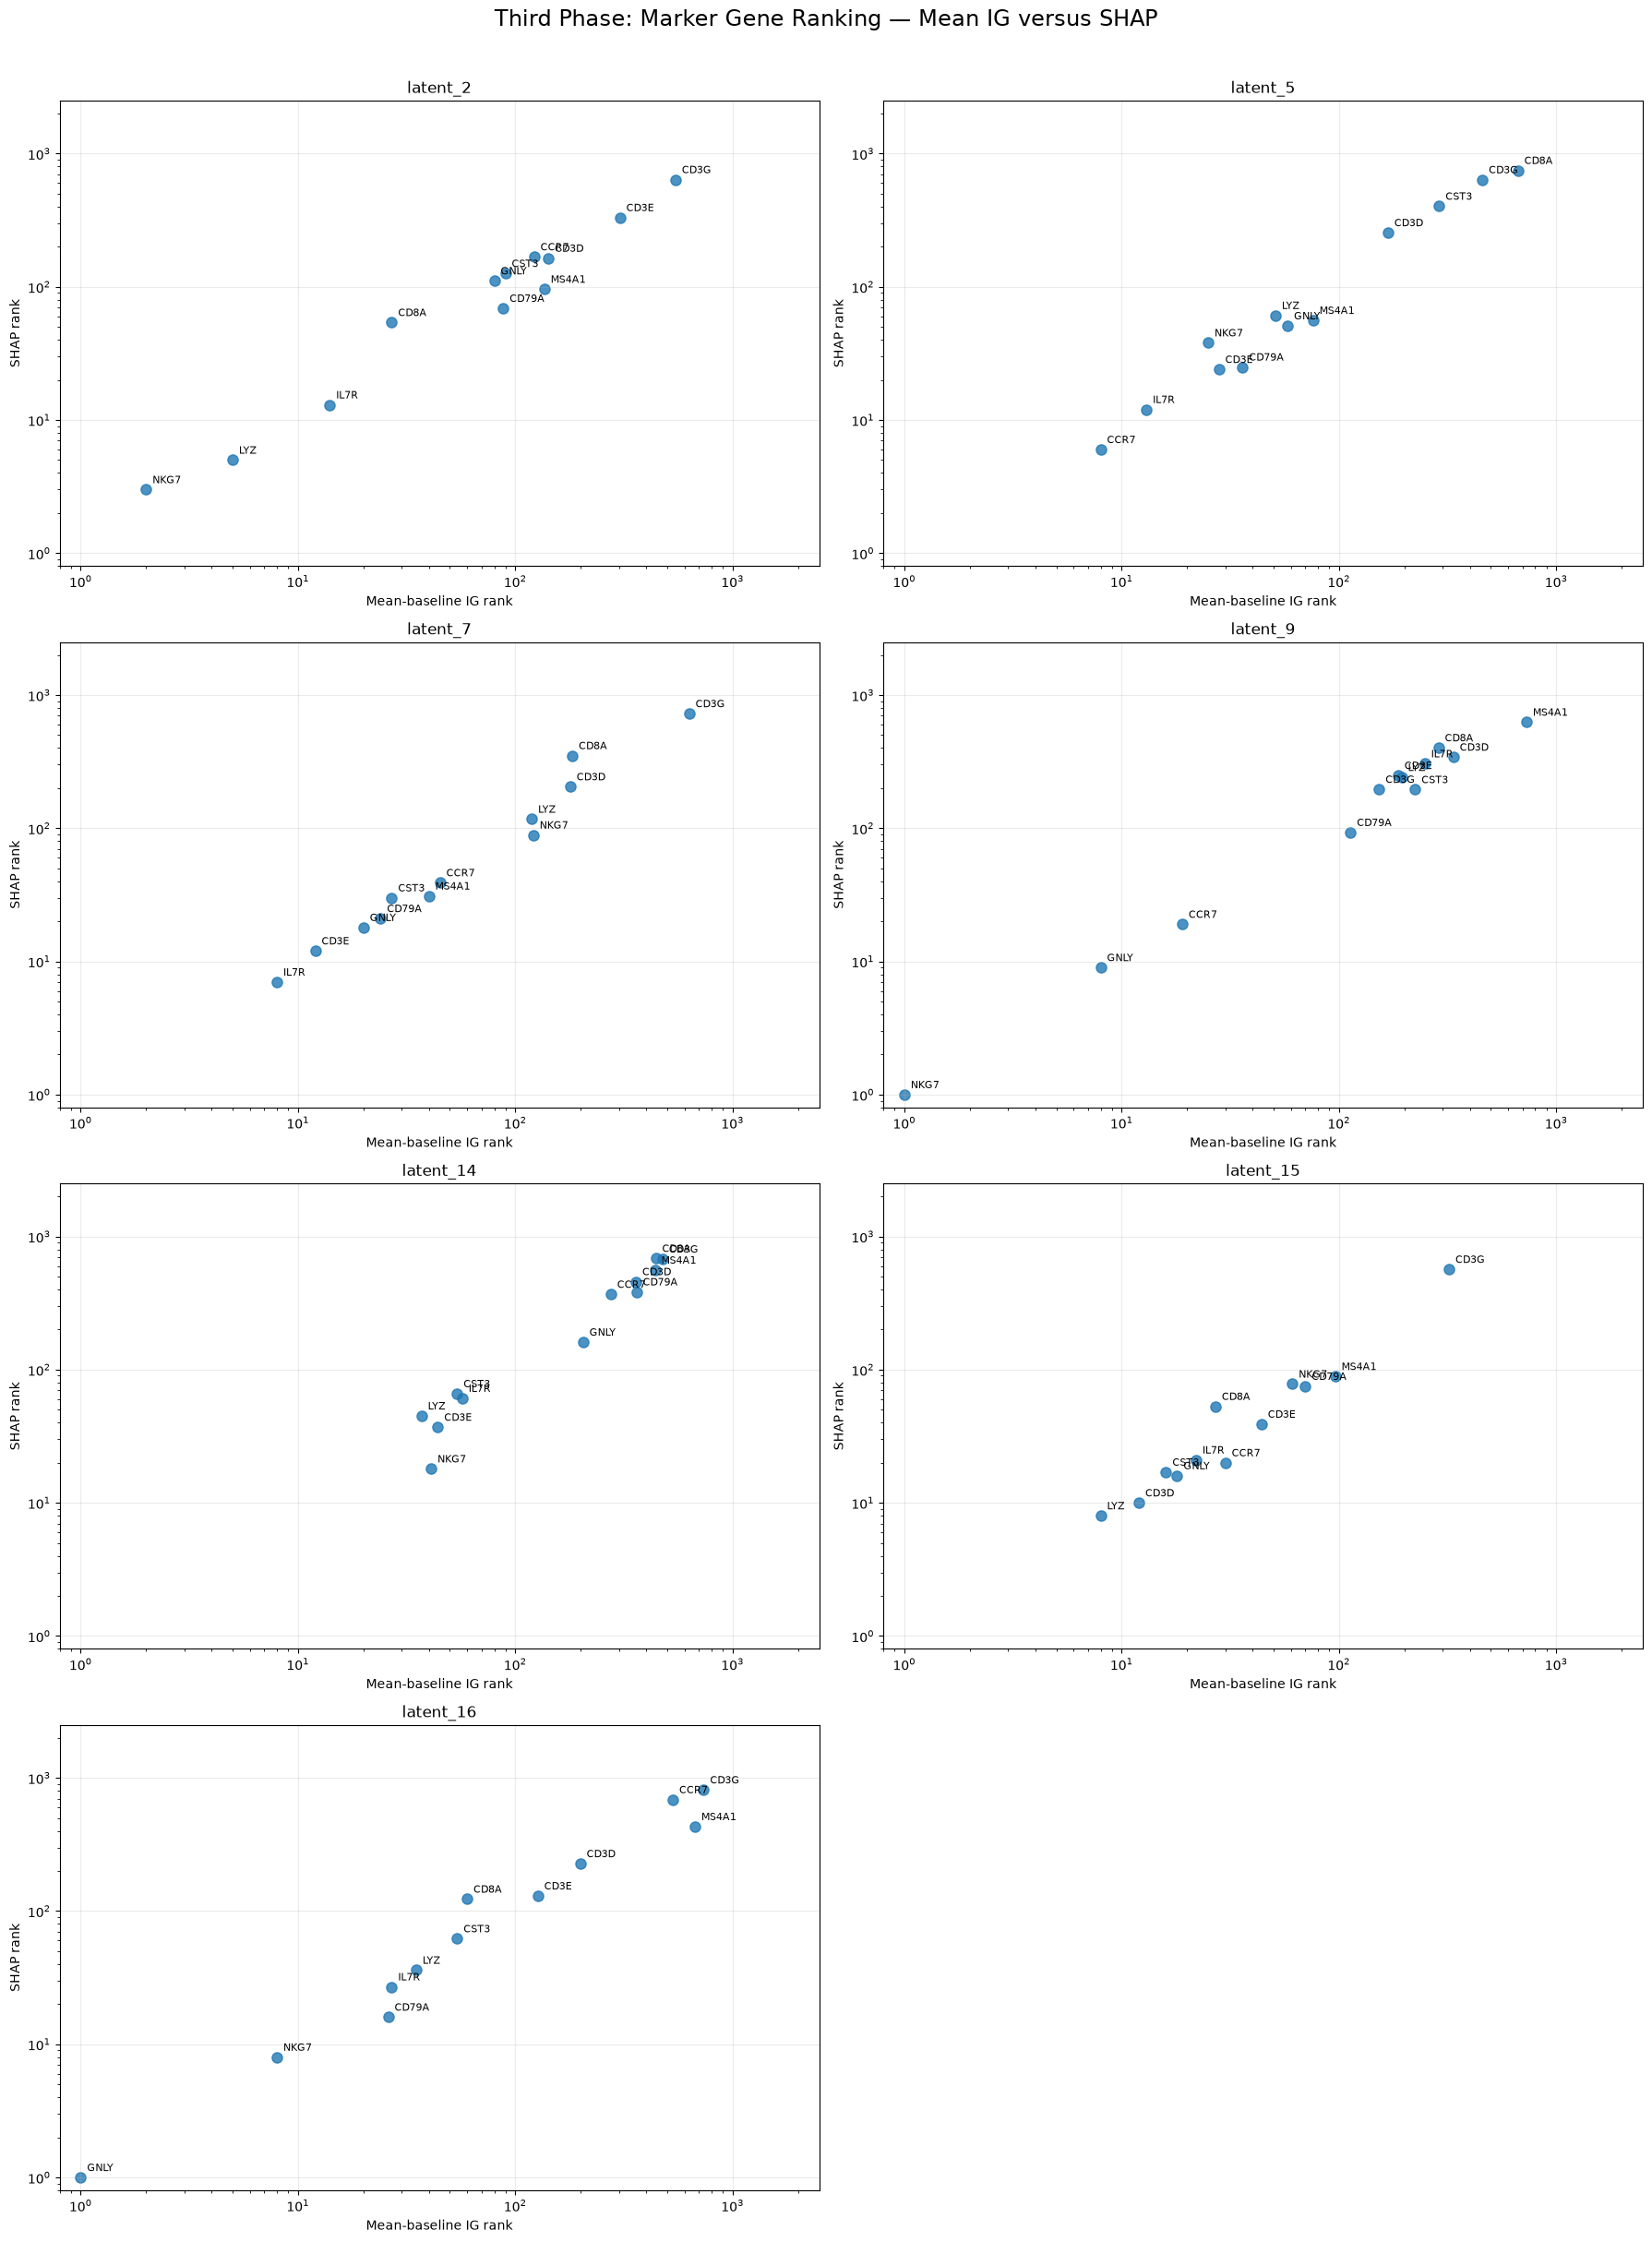

Saved: third_phase_marker_rank_ig_vs_shap_spread.png


In [130]:

# ============================================================
# THIRD PHASE: SPREAD-OUT MARKER RANKING COMPARISON
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    4, 2,
    figsize=(18, 24)
)

axes = axes.flatten()

for i, dim in enumerate(active_dims):

    subset = marker_df[
        marker_df["latent_dimension"] == dim
    ].copy()

    ax = axes[i]

    ax.scatter(
        subset["rank_ig"],
        subset["rank_shap"],
        s=65,
        alpha=0.8
    )

    for _, row in subset.iterrows():
        ax.annotate(
            row["gene"],
            (row["rank_ig"], row["rank_shap"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    # Logarithmic scales spread out lower-ranked values
    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_title(dim, fontsize=12)
    ax.set_xlabel("Mean-baseline IG rank")
    ax.set_ylabel("SHAP rank")

    ax.grid(True, alpha=0.25)

    ax.set_xlim(0.8, 2500)
    ax.set_ylim(0.8, 2500)

axes[-1].axis("off")

fig.suptitle(
    "Third Phase: Marker Gene Ranking — Mean IG versus SHAP",
    fontsize=17,
    y=1.01
)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_marker_rank_ig_vs_shap_spread.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved: third_phase_marker_rank_ig_vs_shap_spread.png")


THIRD PHASE: COMPLETENESS FIGURES
Zero-baseline IG: (7, 5)
Mean-baseline IG: (7, 5)
Final SHAP: (14, 8)


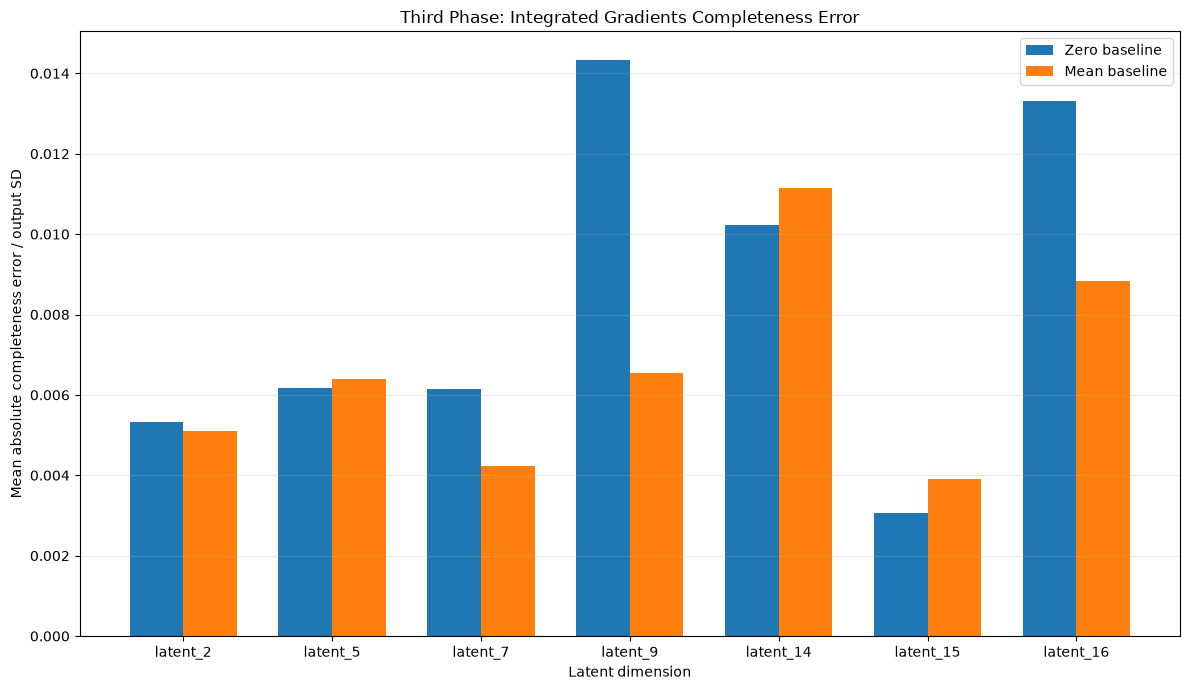

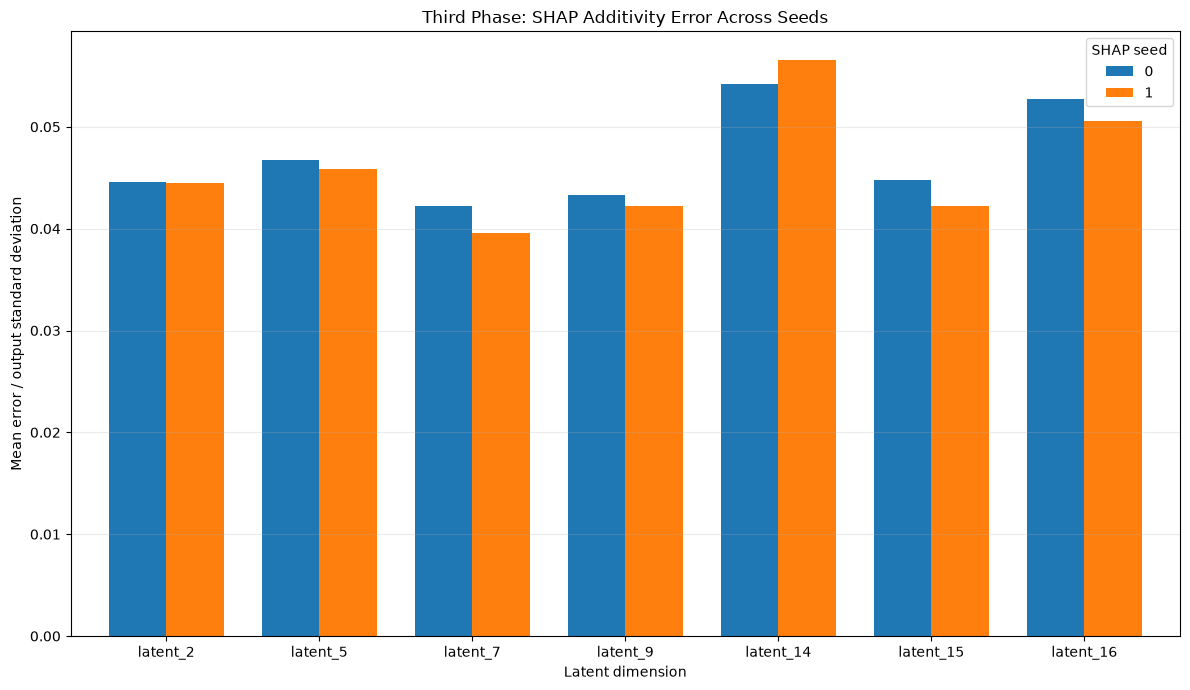

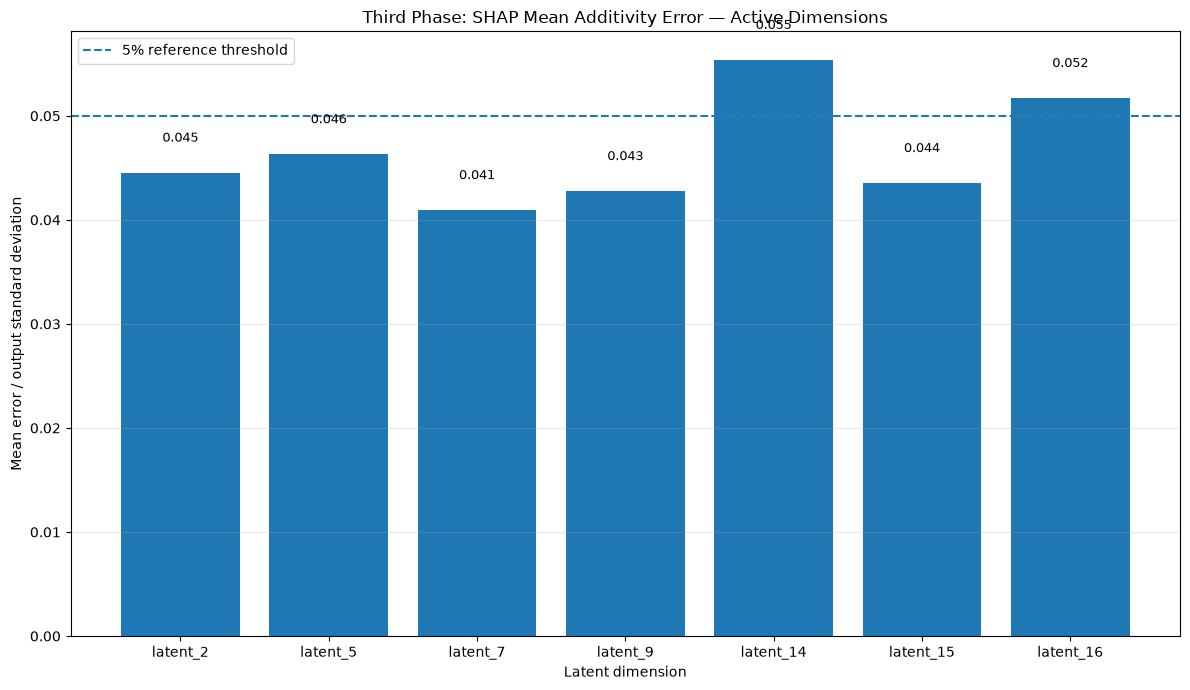


THIRD PHASE COMPLETENESS FIGURES SAVED
1. third_phase_ig_completeness_comparison.png
2. third_phase_shap_additivity_by_seed.png
3. third_phase_shap_additivity_threshold.png


In [131]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# THIRD PHASE: ATTRIBUTION COMPLETENESS FIGURES
# ============================================================

figure_dir = ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

active_dims = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

# Load existing completeness results
ig_zero = pd.read_csv(
    ROOT / "outputs/attributions/ig_zero_completeness.csv"
)

ig_mean = pd.read_csv(
    ROOT / "outputs/attributions/ig_mean_completeness.csv"
)

shap_final = pd.read_csv(
    ROOT / "outputs/shap/shap_final_additivity_test528.csv"
)

# Restrict IG and SHAP to active dimensions
ig_zero = ig_zero[
    ig_zero["dimension"].isin(active_dims)
].copy()

ig_mean = ig_mean[
    ig_mean["dimension"].isin(active_dims)
].copy()

shap_final = shap_final[
    shap_final["latent_dimension"].isin(active_dims)
].copy()

print("THIRD PHASE: COMPLETENESS FIGURES")
print("=" * 60)
print("Zero-baseline IG:", ig_zero.shape)
print("Mean-baseline IG:", ig_mean.shape)
print("Final SHAP:", shap_final.shape)

# ------------------------------------------------------------
# 1. IG ZERO-BASELINE VS MEAN-BASELINE COMPLETENESS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(active_dims))
width = 0.36

ax.bar(
    x - width / 2,
    ig_zero["mean_error_over_output_sd"],
    width,
    label="Zero baseline"
)

ax.bar(
    x + width / 2,
    ig_mean["mean_error_over_output_sd"],
    width,
    label="Mean baseline"
)

ax.set_title(
    "Third Phase: Integrated Gradients Completeness Error"
)
ax.set_xlabel("Latent dimension")
ax.set_ylabel("Mean absolute completeness error / output SD")
ax.set_xticks(x)
ax.set_xticklabels(active_dims)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_ig_completeness_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 2. FINAL SHAP ADDITIVITY ERROR BY SEED
# ------------------------------------------------------------

shap_pivot = shap_final.pivot(
    index="latent_dimension",
    columns="seed",
    values="mean_error_over_output_sd"
).reindex(active_dims)

fig, ax = plt.subplots(figsize=(12, 7))

shap_pivot.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title(
    "Third Phase: SHAP Additivity Error Across Seeds"
)
ax.set_xlabel("Latent dimension")
ax.set_ylabel("Mean error / output standard deviation")
ax.legend(title="SHAP seed")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_shap_additivity_by_seed.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. SHAP ADDITIVITY ERROR AGAINST 5% THRESHOLD
# ------------------------------------------------------------

shap_summary = (
    shap_final.groupby("latent_dimension")
    ["mean_error_over_output_sd"]
    .mean()
    .reindex(active_dims)
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.bar(
    shap_summary.index,
    shap_summary.values
)

ax.axhline(
    0.05,
    linestyle="--",
    label="5% reference threshold"
)

for bar, value in zip(bars, shap_summary.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.003,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "Third Phase: SHAP Mean Additivity Error — Active Dimensions"
)
ax.set_xlabel("Latent dimension")
ax.set_ylabel("Mean error / output standard deviation")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_shap_additivity_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

print("\nTHIRD PHASE COMPLETENESS FIGURES SAVED")
print("1. third_phase_ig_completeness_comparison.png")
print("2. third_phase_shap_additivity_by_seed.png")
print("3. third_phase_shap_additivity_threshold.png")


THIRD PHASE: MARKER ENRICHMENT
Results shape: (24, 11)
Columns: ['method', 'markers', 'top_k', 'counted', 'observed', 'null_mean', 'null_sd', 'p_value', 'empirical_p_value', 'fdr_adjusted_p_value', 'significant_after_fdr']
FDR column used: fdr_adjusted_p_value


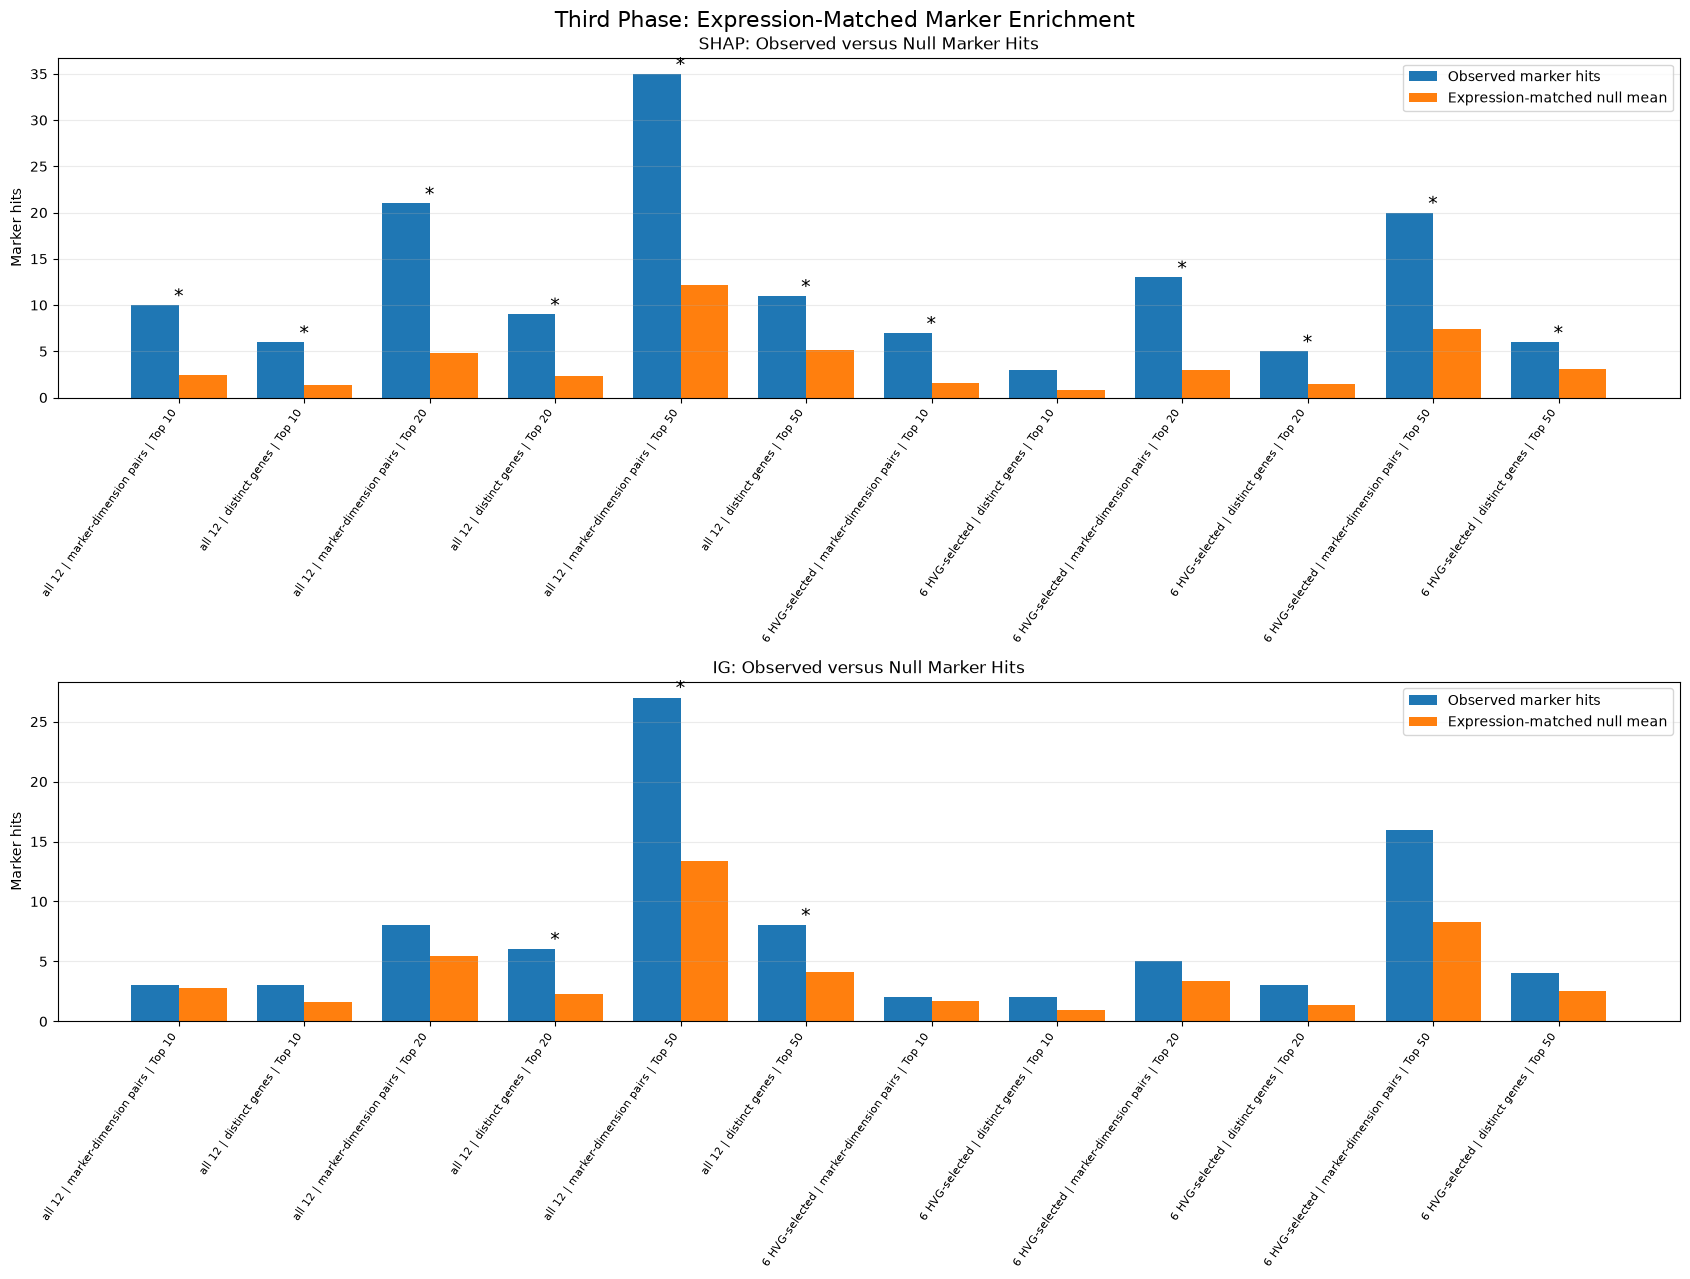

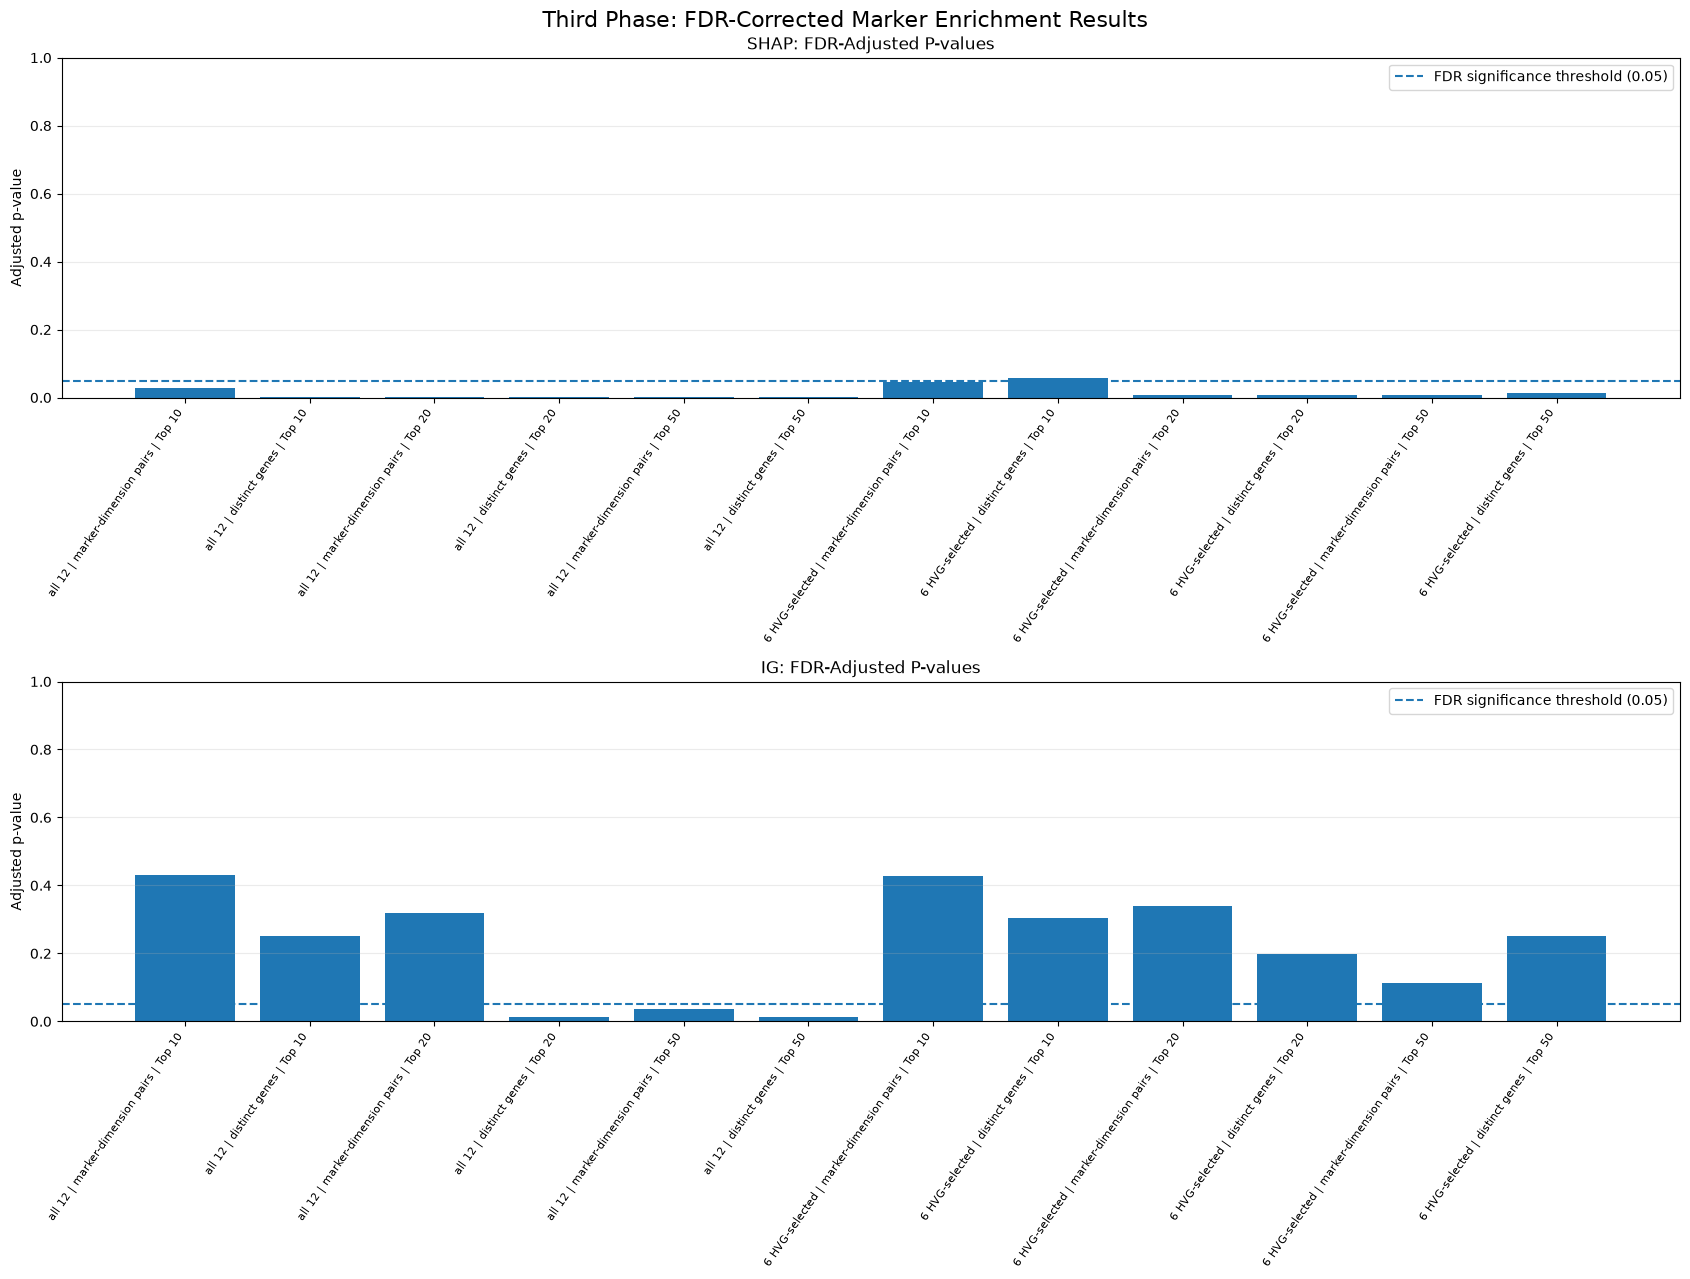


THIRD PHASE MARKER ENRICHMENT FIGURES SAVED
1. third_phase_marker_enrichment_observed_vs_null.png
2. third_phase_marker_enrichment_fdr.png

FDR SUMMARY
Total comparisons: 24
Significant after FDR: 14
FDR threshold: 0.05


In [132]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# THIRD PHASE: EXPRESSION-MATCHED MARKER ENRICHMENT
# ============================================================

figure_dir = ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

results_path = (
    ROOT / "outputs/shap/"
    "shap_ig_marker_sensitivity_test528_FDR_corrected.csv"
)

enrichment_df = pd.read_csv(results_path)

print("THIRD PHASE: MARKER ENRICHMENT")
print("=" * 60)
print("Results shape:", enrichment_df.shape)
print("Columns:", enrichment_df.columns.tolist())

# Identify the FDR-adjusted p-value column
fdr_candidates = [
    col for col in enrichment_df.columns
    if any(term in col.lower() for term in
           ["fdr", "adjusted", "p_adj", "q_value", "qvalue"])
]

if not fdr_candidates:
    raise ValueError(
        "No FDR-adjusted p-value column was found. "
        "Check the printed column names."
    )

fdr_col = fdr_candidates[0]

print("FDR column used:", fdr_col)

# Verify required columns
required_columns = [
    "method", "markers", "top_k",
    "counted", "observed", "null_mean"
]

missing = [
    col for col in required_columns
    if col not in enrichment_df.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Create comparison labels
enrichment_df["comparison"] = (
    enrichment_df["markers"].astype(str)
    + " | "
    + enrichment_df["counted"].astype(str)
    + " | Top "
    + enrichment_df["top_k"].astype(str)
)

enrichment_df["significant_fdr"] = (
    enrichment_df[fdr_col] < 0.05
)

# ------------------------------------------------------------
# 1. OBSERVED MARKER HITS VERSUS NULL EXPECTATION
# ------------------------------------------------------------

methods = ["SHAP", "IG"]

fig, axes = plt.subplots(
    2, 1,
    figsize=(17, 13)
)

for ax, method in zip(axes, methods):

    subset = enrichment_df[
        enrichment_df["method"].str.upper() == method
    ].copy()

    x = np.arange(len(subset))
    width = 0.38

    ax.bar(
        x - width / 2,
        subset["observed"],
        width,
        label="Observed marker hits"
    )

    ax.bar(
        x + width / 2,
        subset["null_mean"],
        width,
        label="Expression-matched null mean"
    )

    for i, (_, row) in enumerate(subset.iterrows()):

        if row["significant_fdr"]:
            ax.text(
                i,
                max(row["observed"], row["null_mean"]) + 0.3,
                "*",
                ha="center",
                fontsize=14
            )

    ax.set_title(f"{method}: Observed versus Null Marker Hits")
    ax.set_ylabel("Marker hits")
    ax.set_xticks(x)
    ax.set_xticklabels(
        subset["comparison"],
        rotation=55,
        ha="right",
        fontsize=8
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Third Phase: Expression-Matched Marker Enrichment",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_marker_enrichment_observed_vs_null.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 2. FDR-ADJUSTED P-VALUES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(17, 13)
)

for ax, method in zip(axes, methods):

    subset = enrichment_df[
        enrichment_df["method"].str.upper() == method
    ].copy()

    x = np.arange(len(subset))

    ax.bar(
        x,
        subset[fdr_col]
    )

    ax.axhline(
        0.05,
        linestyle="--",
        label="FDR significance threshold (0.05)"
    )

    ax.set_title(f"{method}: FDR-Adjusted P-values")
    ax.set_ylabel("Adjusted p-value")
    ax.set_xticks(x)
    ax.set_xticklabels(
        subset["comparison"],
        rotation=55,
        ha="right",
        fontsize=8
    )
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Third Phase: FDR-Corrected Marker Enrichment Results",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    figure_dir / "third_phase_marker_enrichment_fdr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

print("\nTHIRD PHASE MARKER ENRICHMENT FIGURES SAVED")
print("1. third_phase_marker_enrichment_observed_vs_null.png")
print("2. third_phase_marker_enrichment_fdr.png")

print("\nFDR SUMMARY")
print("Total comparisons:", len(enrichment_df))
print(
    "Significant after FDR:",
    int(enrichment_df["significant_fdr"].sum())
)
print("FDR threshold: 0.05")


In [133]:

# ============================================================
# THIRD PHASE: FINAL FIGURE INVENTORY
# ============================================================

from pathlib import Path

figure_dir = ROOT / "figures"

third_phase_figures = sorted(
    figure_dir.glob("third_phase_*.png")
)

print("THIRD PHASE FINAL FIGURE INVENTORY")
print("=" * 65)

for i, path in enumerate(third_phase_figures, 1):
    size_mb = path.stat().st_size / (1024 * 1024)
    print(f"{i:02d}. {path.name} ({size_mb:.2f} MB)")

print("\nTOTAL THIRD PHASE FIGURES:", len(third_phase_figures))
print("FIGURE DIRECTORY:", figure_dir)

print("\nINVENTORY COMPLETED")


THIRD PHASE FINAL FIGURE INVENTORY
01. third_phase_ig_baseline_spearman.png (0.10 MB)
02. third_phase_ig_baseline_top20_overlap.png (0.11 MB)
03. third_phase_ig_completeness_comparison.png (0.12 MB)
04. third_phase_ig_mean_top20.png (0.74 MB)
05. third_phase_ig_zero_top20.png (0.73 MB)
06. third_phase_marker_enrichment_fdr.png (0.64 MB)
07. third_phase_marker_enrichment_observed_vs_null.png (0.53 MB)
08. third_phase_marker_rank_ig_vs_shap.png (0.85 MB)
09. third_phase_marker_rank_ig_vs_shap_spread.png (0.71 MB)
10. third_phase_shap_additivity_by_seed.png (0.11 MB)
11. third_phase_shap_additivity_threshold.png (0.13 MB)
12. third_phase_shap_ig_spearman.png (0.10 MB)
13. third_phase_shap_ig_top20_overlap.png (0.11 MB)
14. third_phase_shap_top20.png (0.73 MB)
15. third_phase_shared_genes_latent_14.png (0.08 MB)
16. third_phase_shared_genes_latent_15.png (0.09 MB)
17. third_phase_shared_genes_latent_16.png (0.10 MB)
18. third_phase_shared_genes_latent_2.png (0.09 MB)
19. third_phase_shared

In [134]:

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# THIRD PHASE: FINAL SCIENTIFIC AND REPRODUCIBILITY AUDIT
# ============================================================

project_root = ROOT
figure_dir = project_root / "figures"

active_dims = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

audit_results = []

def record_check(name, passed, details):
    audit_results.append({
        "check": name,
        "status": "PASS" if passed else "CHECK",
        "details": details
    })

print("THIRD PHASE FINAL AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. FIGURE INVENTORY
# ------------------------------------------------------------

figures = sorted(figure_dir.glob("third_phase_*.png"))

record_check(
    "Third Phase figure inventory",
    len(figures) == 21,
    f"{len(figures)} figures found; expected 21"
)

# Check that each image file is non-empty
empty_figures = [
    path.name for path in figures
    if path.stat().st_size == 0
]

record_check(
    "Figure files non-empty",
    len(empty_figures) == 0,
    f"Empty files: {empty_figures}"
)

# ------------------------------------------------------------
# 2. SHAP AND IG RANKING TABLES
# ------------------------------------------------------------

shap = pd.read_csv(
    project_root / "outputs/shap/shap_gene_ranking.csv"
)

ig_zero = pd.read_csv(
    project_root / "outputs/attributions/ig_zero_ranking.csv"
)

ig_mean = pd.read_csv(
    project_root / "outputs/attributions/ig_mean_ranking.csv"
)

shap_active = shap[
    shap["latent_dimension"].isin(active_dims)
]

ig_zero_active = ig_zero[
    ig_zero["dimension"].isin(active_dims)
]

ig_mean_active = ig_mean[
    ig_mean["dimension"].isin(active_dims)
]

expected_rows = 2006 * len(active_dims)

record_check(
    "SHAP active-dimension ranking",
    len(shap_active) == expected_rows,
    f"{len(shap_active)} rows; expected {expected_rows}"
)

record_check(
    "Zero-baseline IG ranking",
    len(ig_zero_active) == expected_rows,
    f"{len(ig_zero_active)} rows; expected {expected_rows}"
)

record_check(
    "Mean-baseline IG ranking",
    len(ig_mean_active) == expected_rows,
    f"{len(ig_mean_active)} rows; expected {expected_rows}"
)

# Check each active dimension has 2,006 genes
for name, df, dimension_col in [
    ("SHAP", shap_active, "latent_dimension"),
    ("Zero IG", ig_zero_active, "dimension"),
    ("Mean IG", ig_mean_active, "dimension")
]:
    counts = df.groupby(dimension_col)["gene"].nunique()

    record_check(
        f"{name}: 2,006 unique genes per active dimension",
        len(counts) == 7 and (counts == 2006).all(),
        str(counts.to_dict())
    )

# ------------------------------------------------------------
# 3. NUMERICAL VALIDATION
# ------------------------------------------------------------

record_check(
    "SHAP ranking values finite",
    np.isfinite(
        shap_active["mean_absolute_shap"].to_numpy()
    ).all(),
    "Checked mean_absolute_shap"
)

record_check(
    "Zero IG ranking values finite",
    np.isfinite(
        ig_zero_active["mean_abs_ig"].to_numpy()
    ).all(),
    "Checked mean_abs_ig"
)

record_check(
    "Mean IG ranking values finite",
    np.isfinite(
        ig_mean_active["mean_abs_ig"].to_numpy()
    ).all(),
    "Checked mean_abs_ig"
)

# ------------------------------------------------------------
# 4. SHAP VERSUS IG COMPARISON
# ------------------------------------------------------------

shap_ig = pd.read_csv(
    project_root / "outputs/shap/shap_vs_ig_test528_summary.csv"
)

record_check(
    "SHAP versus IG comparison dimensions",
    len(shap_ig) == 7
    and set(shap_ig["latent_dimension"]) == set(active_dims),
    f"{len(shap_ig)} dimensions present"
)

# ------------------------------------------------------------
# 5. BASELINE SENSITIVITY
# ------------------------------------------------------------

baseline_spearman = pd.read_csv(
    project_root / "outputs/attributions/ig_baseline_spearman_comparison.csv"
)

baseline_overlap = pd.read_csv(
    project_root / "outputs/attributions/ig_baseline_top20_overlap.csv"
)

record_check(
    "IG baseline Spearman comparison",
    len(baseline_spearman) == 7
    and set(baseline_spearman["dimension"]) == set(active_dims),
    f"{len(baseline_spearman)} dimensions present"
)

record_check(
    "IG baseline top-20 overlap",
    len(baseline_overlap) == 7
    and set(baseline_overlap["dimension"]) == set(active_dims),
    f"{len(baseline_overlap)} dimensions present"
)

# ------------------------------------------------------------
# 6. ATTRIBUTION COMPLETENESS
# ------------------------------------------------------------

ig_zero_comp = pd.read_csv(
    project_root / "outputs/attributions/ig_zero_completeness.csv"
)

ig_mean_comp = pd.read_csv(
    project_root / "outputs/attributions/ig_mean_completeness.csv"
)

shap_comp = pd.read_csv(
    project_root / "outputs/shap/shap_final_additivity_test528.csv"
)

record_check(
    "Zero-baseline IG completeness",
    len(ig_zero_comp) == 7
    and set(ig_zero_comp["dimension"]) == set(active_dims),
    f"{len(ig_zero_comp)} dimensions present"
)

record_check(
    "Mean-baseline IG completeness",
    len(ig_mean_comp) == 7
    and set(ig_mean_comp["dimension"]) == set(active_dims),
    f"{len(ig_mean_comp)} dimensions present"
)

record_check(
    "Final SHAP additivity results",
    set(shap_comp["latent_dimension"]) == set(active_dims)
    and shap_comp["seed"].nunique() == 2
    and len(shap_comp) == 14,
    f"{len(shap_comp)} rows; {shap_comp['seed'].nunique()} seeds"
)

# ------------------------------------------------------------
# 7. CORRECTED FDR RESULTS
# ------------------------------------------------------------

fdr = pd.read_csv(
    project_root / "outputs/shap/"
    "shap_ig_marker_sensitivity_test528_FDR_corrected.csv"
)

fdr_candidates = [
    col for col in fdr.columns
    if any(term in col.lower() for term in
           ["fdr", "adjusted", "p_adj", "q_value", "qvalue"])
]

if fdr_candidates:
    fdr_col = fdr_candidates[0]
    significant_count = int((fdr[fdr_col] < 0.05).sum())

    record_check(
        "FDR comparison count",
        len(fdr) == 24,
        f"{len(fdr)} comparisons; expected 24"
    )

    record_check(
        "FDR significant result count",
        significant_count == 14,
        f"{significant_count} significant comparisons; expected 14"
    )
else:
    record_check(
        "FDR adjusted p-value column",
        False,
        "No adjusted p-value column found"
    )

# ------------------------------------------------------------
# 8. DISPLAY FINAL AUDIT
# ------------------------------------------------------------

audit_df = pd.DataFrame(audit_results)

print("\nAUDIT RESULTS")
print("=" * 70)

display(audit_df)

print("\nSUMMARY")
print("=" * 70)

passed = (audit_df["status"] == "PASS").sum()
checked = (audit_df["status"] == "CHECK").sum()

print("Checks passed:", passed)
print("Checks requiring review:", checked)
print("Total checks:", len(audit_df))

if checked == 0:
    print("\nALL THIRD PHASE AUDIT CHECKS PASSED.")
else:
    print("\nPLEASE REVIEW THE CHECK ITEMS ABOVE.")

print("\nNo source files or analysis results were modified.")


THIRD PHASE FINAL AUDIT

AUDIT RESULTS


,check,status,details
0,Third Phase figure inventory,PASS,21 figures found; expected 21
1,Figure files non-empty,PASS,Empty files: []
2,SHAP active-dimension ranking,PASS,14042 rows; expected 14042
3,Zero-baseline IG ranking,PASS,14042 rows; expected 14042
4,Mean-baseline IG ranking,PASS,14042 rows; expected 14042
5,"SHAP: 2,006 unique genes per active dimension",PASS,"{'latent_14': 2006, 'latent_15': 2006, 'latent..."
6,"Zero IG: 2,006 unique genes per active dimension",PASS,"{'latent_14': 2006, 'latent_15': 2006, 'latent..."
7,"Mean IG: 2,006 unique genes per active dimension",PASS,"{'latent_14': 2006, 'latent_15': 2006, 'latent..."
8,SHAP ranking values finite,PASS,Checked mean_absolute_shap
9,Zero IG ranking values finite,PASS,Checked mean_abs_ig



SUMMARY
Checks passed: 18
Checks requiring review: 1
Total checks: 19

PLEASE REVIEW THE CHECK ITEMS ABOVE.

No source files or analysis results were modified.


In [135]:

# ============================================================
# THIRD PHASE: CORRECTED SHAP ADDITIVITY AUDIT
# ============================================================

shap_comp = pd.read_csv(
    ROOT / "outputs/shap/shap_final_additivity_test528.csv"
)

active_dims = [
    "latent_2",
    "latent_5",
    "latent_7",
    "latent_9",
    "latent_14",
    "latent_15",
    "latent_16"
]

# Filter to the seven active dimensions
shap_active_comp = shap_comp[
    shap_comp["latent_dimension"].isin(active_dims)
].copy()

print("THIRD PHASE: SHAP ADDITIVITY VERIFICATION")
print("=" * 60)

print("Original rows:", len(shap_comp))
print("Active dimension rows:", len(shap_active_comp))
print("Active dimensions:", shap_active_comp["latent_dimension"].nunique())
print("Seeds:", sorted(shap_active_comp["seed"].unique()))

# Verify two seeds for every active dimension
counts = shap_active_comp.groupby(
    "latent_dimension"
)["seed"].nunique()

print("\nSeeds per active dimension:")
print(counts)

assert len(shap_active_comp) == 14
assert shap_active_comp["latent_dimension"].nunique() == 7
assert shap_active_comp["seed"].nunique() == 2
assert (counts == 2).all()

print("\nPASS: All seven active dimensions have results for both SHAP seeds.")


THIRD PHASE: SHAP ADDITIVITY VERIFICATION
Original rows: 32
Active dimension rows: 14
Active dimensions: 7
Seeds: [0, 1]

Seeds per active dimension:
latent_dimension
latent_14    2
latent_15    2
latent_16    2
latent_2     2
latent_5     2
latent_7     2
latent_9     2
Name: seed, dtype: int64

PASS: All seven active dimensions have results for both SHAP seeds.
